# Music Hit Predictor: Analítica predictiva del éxito musical en Billboard

**Proyecto final – Análisis predictivo con dataset propio (Parcial 3)**

|  |  |
|---|---|
| Estudiante | `Angel Johan Toloza Oviedo` |
| Curso / docente | `Carlos Carrascal Avendaño / Análisis y diseño de sistemas con énfasis en el análisis de datos.` |
| Enlace al dataset original (Kaggle) | `https://www.kaggle.com/datasets/luthfimuthathohirin/billboard-hot-100-spotify-audio-features` |
| Enlace al video de sustentación | `https://drive.google.com/drive/folders/1vT3KcO1Mwr3FkmImRjkcnx8mnWN_uN80?usp=sharing` |
| Fecha de entrega | `8/11/2026` |

> **Tipo de problema:** clasificación supervisada **multiclase** (4 clases).
> **Variable objetivo:** `chart_success_tier`.
> **Aviso:** ejercicio académico. El modelo describe patrones entre canciones que **ya ingresaron** al Billboard Hot 100; no predice si una canción inédita será un éxito ni establece causalidad.

## Tabla de contenido

0. [Configuración del entorno](#config)
1. [Bloque 1 · Planteamiento, carga e inspección](#b1)
2. [Bloque 2 · Limpieza, transformación e ingeniería de características](#b2)
3. [Bloque 3 · Análisis exploratorio y visualización](#b3)
4. [Bloque 4 · Modelos tradicionales](#b4)
   - 4.9 [Experimento complementario: valor del enriquecimiento con IA](#b4ia)
5. [Bloque 5 · Red neuronal (TensorFlow/Keras)](#b5)
6. [Reto final · Escenario B (clasificación)](#reto)
7. [Bloque 6 · Informe ejecutivo](#b6)
8. [Cierre: tabla final, checklist, limitaciones, declaración de IA, referencias, revisión humana y guía de sustentación](#cierre)

<a id="config"></a>
## 0. Configuración del entorno

Todas las librerías se importan en **una sola celda** y todas las fuentes de aleatoriedad usan la misma semilla (`SEED = 42`) para que el notebook sea reproducible al ejecutarse desde cero (`Entorno de ejecución → Reiniciar y ejecutar todo`).

Google Colab ya incluye todas las librerías utilizadas (pandas, NumPy, Matplotlib, Seaborn, SciPy, scikit-learn y TensorFlow); no hace falta instalar nada.

In [ ]:
# ============================================================
# Imports centralizados
# ============================================================
import os, re, ast, glob, zipfile, random, warnings, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # oculta mensajes informativos de TensorFlow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.model_selection import (StratifiedGroupKFold, cross_validate, cross_val_score,
                                     cross_val_predict, GridSearchCV, RandomizedSearchCV)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report,
                             precision_recall_curve, ConfusionMatrixDisplay)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings("ignore")

# ============================================================
# Reproducibilidad
# ============================================================
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)          # fija semillas de Python, NumPy y TF
try:
    tf.config.experimental.enable_op_determinism()  # operaciones deterministas en TF
except Exception as e:
    print("Determinismo de TF no disponible:", e)

# ============================================================
# Parámetros globales del proyecto
# ============================================================
DATA_FILE = "billboard_hot_100_spotify_audio_features_enriched.csv"
TARGET = "chart_success_tier"
# Orden ordinal de las clases (de menor a mayor éxito)
TIER_ORDER  = ["hot_100_entry", "top_forty_hit", "top_ten_smash", "historic_number_one"]
TIER_LABELS = ["Hot 100 (41–100)", "Top 40 (11–40)", "Top 10 (2–10)", "N.º 1"]
# Decisión documentada en la sección 2.3: excluir del modelado el bloque de procedencia no verificable
EXCLUIR_BLOQUE_NO_VERIFICABLE = True
N_ITER_SEARCH = 12      # iteraciones de RandomizedSearchCV (subir si hay más tiempo de cómputo)

# ============================================================
# Estilo gráfico: rampa secuencial azul para el target ordinal
# y paleta categórica fija para otras series
# ============================================================
TIER_COLORS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
CAT_COLORS  = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
TIER_PALETTE = dict(zip(TIER_ORDER, TIER_COLORS))
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e5e1", "axes.edgecolor": "#898781",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

print("Versiones →",
      f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} |",
      f"seaborn {sns.__version__} | tensorflow {tf.__version__}")

I0000 00:00:1794019388.087283    7621 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794019389.427664    7621 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Versiones → pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | seaborn 0.13.2 | tensorflow 2.21.0


<a id="b1"></a>
# Bloque 1 · Planteamiento del problema, carga e inspección de datos

## 1.1 Contexto empresarial

Una **discográfica** quiere entender mejor qué características musicales aparecen asociadas con distintos niveles de éxito comercial dentro del **Billboard Hot 100**. Hoy la evaluación del potencial de una canción depende, sobre todo, de la experiencia artística, la intuición, las tendencias del momento y el análisis de mercado. Este proyecto explora cómo el análisis de datos puede **complementar** (no sustituir) ese criterio.

## 1.2 Pregunta de negocio

> **¿En qué medida las características musicales originales permiten predecir el nivel de éxito histórico de canciones que ingresaron al Billboard Hot 100, y cuánto mejora esta predicción al incorporar variables de enriquecimiento musical?**

## 1.3 Objetivos

**Objetivo general.** Desarrollar una solución de análisis predictivo con Python, visualización de datos, modelos tradicionales de Machine Learning y una red neuronal, para investigar la relación entre características musicales y niveles de éxito histórico en el Billboard Hot 100.

**Objetivos específicos.**
1. Inspeccionar, limpiar y transformar el dataset, identificando faltantes, duplicados, atípicos e inválidos.
2. Explorar relaciones entre características musicales y niveles de éxito.
3. Construir y comparar modelos tradicionales de clasificación supervisada (baseline, regresión logística, árbol de decisión y Random Forest).
4. Construir una red neuronal con TensorFlow/Keras y compararla con los modelos tradicionales.
5. Evaluar con métricas adecuadas a un problema multiclase **desbalanceado**.
6. Investigar si las variables enriquecidas con IA aportan información musical adicional o si reproducen resultados históricos (*data leakage*).
7. Interpretar resultados y comunicar hallazgos, limitaciones y riesgos.

## 1.4 Beneficiarios y decisiones que apoyaría

| Beneficiario | Decisión que apoyaría el análisis |
|---|---|
| Equipo de A&R / producción musical | Identificar qué perfiles sonoros se asocian históricamente a niveles de éxito más altos dentro del Hot 100. |
| Equipo de análisis de mercado | Comprender tendencias musicales por década (energía, bailabilidad, valencia, duración). |
| Dirección comercial | Usar el modelo como **una señal más** para priorizar análisis de canciones; nunca como criterio único. |
| Equipo de datos | Evaluar críticamente el valor (y los riesgos) de comprar o usar datasets enriquecidos con IA. |

**Impacto esperado:** mejor comprensión de patrones históricos y una evaluación honesta de cuánto (o qué tan poco) explican las variables de audio. **Fuera de alcance:** garantizar el éxito comercial o predecir si una canción inédita entrará al Hot 100.

## 1.5 Fuente del dataset y justificación

| Campo | Información |
|---|---|
| Archivo | `billboard_hot_100_spotify_audio_features_enriched.csv` |
| Plataforma | Kaggle |
| Autor | Luthfi Muthathohirin |
| URL | `https://www.kaggle.com/datasets/luthfimuthathohirin/billboard-hot-100-spotify-audio-features` |
| Licencia | **CC0** (dominio público) |
| Fecha de consulta | `01/11/2026` |
| Periodo declarado por el autor | agosto de 1958 a octubre de 2026 |
| Dimensiones | 32.503 registros × 33 columnas (se verifica abajo) |

**Metodología de recopilación declarada por el autor** *(información declarada, no verificada independientemente en este proyecto)*:
- Se recopilaron registros históricos y modernos del Billboard Hot 100.
- Se agregaron métricas de desempeño: posición máxima, semanas acumuladas y fechas de aparición.
- Se incorporaron características musicales mediante la **Spotify Web API**.
- Se usaron mecanismos de *matching* exacto y *fuzzy* para asociar canciones con registros de Spotify.
- Se añadieron etiquetas, perfiles y racionalizaciones generadas mediante **inteligencia artificial**.
- El autor reporta un **Cohen's Kappa de 0,8728** entre anotadores para entradas modernas del enriquecimiento. Esto mide **acuerdo entre anotadores**, no la exactitud de las etiquetas ni el desempeño de un modelo predictivo.

**¿Por qué este dataset?**
- Cumple los requisitos del enunciado: fuente pública (Kaggle), > 1.000 registros, > 8 predictores (≥ 3 numéricos y ≥ 1 categórico), variable objetivo clara y licencia que permite uso académico.
- No es un dataset clásico de clase.
- Tiene **imperfecciones reales** (nulos, duplicados, *matching* dudoso, columnas derivadas del resultado), lo que permite demostrar limpieza y prevención de *data leakage*.
- Combina un problema de negocio realista con un reto metodológico: evaluar críticamente datos enriquecidos con IA.

## 1.6 Carga del archivo en Google Colab

La función `load_dataset()` busca el CSV en el directorio de trabajo; si no lo encuentra, busca un `.zip` que lo contenga y, en Colab, abre un **botón de carga** (`files.upload()`) para seleccionar el CSV **o el ZIP** (el dataset pesa ~43 MB, por eso puede entregarse comprimido).

> Alternativa con Google Drive: `from google.colab import drive; drive.mount('/content/drive')` y luego `load_dataset('/content/drive/MyDrive/<ruta>/billboard_hot_100_spotify_audio_features_enriched.csv')`.

In [ ]:
def _extract_from_zip(zip_path, file_name=DATA_FILE):
    # Extrae el CSV de un ZIP (busca por nombre de archivo, sin importar carpetas internas)
    with zipfile.ZipFile(zip_path) as zf:
        members = [m for m in zf.namelist() if m.endswith(file_name)]
        if not members:
            return None
        zf.extract(members[0], ".")
        return members[0]

def load_dataset(path=DATA_FILE):
    # 1) Rutas directas
    for p in [path, os.path.join("/content", DATA_FILE), os.path.join("data", DATA_FILE)]:
        if os.path.exists(p):
            print(f"Archivo encontrado: {p}")
            return pd.read_csv(p)
    # 2) ZIP en el directorio de trabajo
    for z in glob.glob("*.zip") + glob.glob("/content/*.zip"):
        member = _extract_from_zip(z)
        if member:
            print(f"CSV extraído de {z}")
            return pd.read_csv(member)
    # 3) Botón de carga en Colab
    try:
        from google.colab import files
        print("Seleccione el archivo CSV (o el ZIP que lo contiene)...")
        uploaded = files.upload()
        name = next(iter(uploaded))
        if name.endswith(".zip"):
            name = _extract_from_zip(name)
        return pd.read_csv(name)
    except ImportError:
        raise FileNotFoundError(f"No se encontró {DATA_FILE}. Colóquelo junto al notebook.")

df_raw = load_dataset()
print(f"Registros: {df_raw.shape[0]:,} | Columnas: {df_raw.shape[1]}")

Archivo encontrado: billboard_hot_100_spotify_audio_features_enriched.csv


Registros: 32,503 | Columnas: 33


## 1.7 Primeras 10 filas

In [ ]:
df_raw.head(10)

,song_id,performer,song,spotify_genre,spotify_track_id,spotify_track_preview_url,spotify_track_duration_ms,spotify_track_explicit,spotify_track_album,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,spotify_track_popularity,peak_position,weeks_on_chart,first_week,last_week,chart_success_tier,hit_longevity_profile,acoustic_mood_cluster,musical_era,evidence_span,cot_rationale,confidence_score
0,Blinding LightsThe Weeknd,The Weeknd,Blinding Lights,"['canadian contemporary r&b', 'canadian pop', ...",0sf12qNH5qcw8qpgymFOqD,NaN,201573.0000,False,Blinding Lights,0.5130,0.7960,1.0000,-4.0750,1.0000,0.0629,0.0015,0.0002,0.0938,0.3450,171.0170,4.0000,96.0000,1.0000,76.0000,2019-12-14,2021-05-29,historic_number_one,mega_marathon_hit,intense_aggressive_drive,digital_streaming_explosion,"The Weeknd - Blinding Lights: peak=1, weeks=76...",Psychoacoustic and commercial chart telemetry ...,0.9660
1,Party Rock AnthemLMFAO Featuring Lauren Bennet...,LMFAO Featuring Lauren Bennett & GoonRock,Party Rock Anthem,"['dance pop', 'pop', 'pop rap']",0IkKz2J93C94Ei4BvDop7P,NaN,262173.0000,False,Sorry For Party Rocking,0.7500,0.7270,5.0000,-4.2100,0.0000,0.1420,0.0189,0.0000,0.2660,0.3590,129.9930,4.0000,68.0000,1.0000,68.0000,2011-02-12,2012-07-21,historic_number_one,mega_marathon_hit,intense_aggressive_drive,digital_streaming_explosion,LMFAO Featuring Lauren Bennett & GoonRock - Pa...,Psychoacoustic and commercial chart telemetry ...,0.9560
2,Rolling In The DeepAdele,Adele,Rolling In The Deep,"['british soul', 'pop', 'uk pop']",1CkvWZme3pRgbzaxZnTl5X,https://p.scdn.co/mp3-preview/8c174ce25d94b502...,228293.0000,False,21,0.7290,0.7560,8.0000,-5.1190,1.0000,0.0294,0.1310,0.0000,0.0527,0.5220,104.9450,4.0000,76.0000,1.0000,65.0000,2010-12-25,2012-04-14,historic_number_one,mega_marathon_hit,balanced_acoustic_pop,digital_streaming_explosion,"Adele - Rolling In The Deep: peak=1, weeks=65,...",Psychoacoustic and commercial chart telemetry ...,0.9590
3,CirclesPost Malone,Post Malone,Circles,"['dfw rap', 'melodic rap', 'rap']",21jGcNKet2qwijlDFuPiPb,NaN,215280.0000,False,Hollywood's Bleeding,0.6950,0.7620,0.0000,-3.4970,1.0000,0.0395,0.1920,0.0024,0.0863,0.5530,120.0420,4.0000,98.0000,1.0000,61.0000,2019-09-14,2020-11-07,historic_number_one,mega_marathon_hit,balanced_acoustic_pop,digital_streaming_explosion,"Post Malone - Circles: peak=1, weeks=61, dance...",Psychoacoustic and commercial chart telemetry ...,0.9650
4,Macarena (Bayside Boys Mix)Los Del Rio,Los Del Rio,Macarena (Bayside Boys Mix),"['deep norteno', 'duranguense', 'norteno', 'no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0000,60.0000,1995-09-02,1997-02-08,historic_number_one,mega_marathon_hit,balanced_acoustic_pop,mtv_synth_pop_boom,Los Del Rio - Macarena (Bayside Boys Mix): pea...,Psychoacoustic and commercial chart telemetry ...,0.9450
5,All Of MeJohn Legend,John Legend,All Of Me,"['neo mellow', 'neo soul', 'pop', 'r&b', 'urba...",3U4isOIWM3VvDubwSI3y7a,https://p.scdn.co/mp3-preview/488c53471e56ff9f...,269560.0000,False,Love In The Future (Expanded Edition),0.4220,0.2640,8.0000,-7.0640,1.0000,0.0322,0.9220,0.0000,0.1320,0.3310,119.9300,4.0000,87.0000,1.0000,59.0000,2013-09-21,2014-12-06,historic_number_one,mega_marathon_hit,moody_melancholic,digital_streaming_explosion,"John Legend - All Of Me: peak=1, weeks=59, dan...",Psychoacoustic and commercial chart telemetry ...,0.9650
6,Somebody That I Used To KnowGotye Featuring Ki...,Gotye Featuring Kimbra,Somebody That I Used To Know,['australian pop'],4wCmqSrbyCgxEXROQE6vtV,NaN,244973.0000,False,Making Mirrors,0.8570,0.5170,0.0000,-6.9720,1.0000,0.0384,0.5650,0.0002,0.1020,0.7540,129.0630,4.0000,77.0000,1.0000,59.0000,2012-01-21,2013-03-02,historic_number_one,mega_marathon_hit,chill_downtempo_groove,digital_streaming_explosion,Gotye Featuring Kimbra - Somebody That I Used ...,Psychoacoustic and commercial chart telemetry ...,0.9600
7,Shape Of YouEd S

## 1.8 Últimas 5 filas

In [ ]:
df_raw.tail(5)

,song_id,performer,song,spotify_genre,spotify_track_id,spotify_track_preview_url,spotify_track_duration_ms,spotify_track_explicit,spotify_track_album,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,spotify_track_popularity,peak_position,weeks_on_chart,first_week,last_week,chart_success_tier,hit_longevity_profile,acoustic_mood_cluster,musical_era,evidence_span,cot_rationale,confidence_score
32498,Guy for That (Version 161)Post Malone,Post Malone,Guy for That (Version 161),"['pop rap', 'melodic rap', 'contemporary count...",266f0812b55a0dcd7fa804,https://p.scdn.co/mp3-preview/266f0812b55a0dcd...,191354.0000,False,Austin,0.4540,0.8180,8.0000,-5.6710,1.0000,0.5260,0.2700,0.0298,0.2320,0.3470,114.6120,4.0000,79.0000,100.0000,22.0000,2022-07-19,2022-12-20,hot_100_entry,sustained_radio_hit,intense_aggressive_drive,hyper_streaming_short_form_era,Post Malone - Guy for That (Version 161): peak...,Psychoacoustic and commercial chart telemetry ...,0.9950
32499,Drunk in My Mind feat. GunnaBenson Boone,Benson Boone,Drunk in My Mind feat. Gunna,"['pop', 'singer-songwriter pop']",c5e683d11c79c82611632f,https://p.scdn.co/mp3-preview/c5e683d11c79c826...,182437.0000,False,Fireworks & Rollerblades,0.7910,0.7740,9.0000,-11.2450,0.0000,0.1100,0.2520,0.0520,0.0930,0.2160,148.0220,3.0000,86.0000,100.0000,18.0000,2024-11-28,2025-04-03,hot_100_entry,standard_chart_run,intense_aggressive_drive,hyper_streaming_short_form_era,Benson Boone - Drunk in My Mind feat. Gunna: p...,Psychoacoustic and commercial chart telemetry ...,0.9950
32500,Chemical (Part 2)Post Malone,Post Malone,Chemical (Part 2),"['pop rap', 'melodic rap', 'contemporary count...",5d42319d0b6c0a7ac12307,https://p.scdn.co/mp3-preview/5d42319d0b6c0a7a...,172776.0000,True,Austin,0.7560,0.2730,9.0000,-10.2230,0.0000,0.1300,0.2900,0.0166,0.0720,0.4430,107.6630,4.0000,55.0000,100.0000,17.0000,2025-03-05,2025-07-02,hot_100_entry,standard_chart_run,balanced_acoustic_pop,hyper_streaming_short_form_era,"Post Malone - Chemical (Part 2): peak=100, wee...",Psychoacoustic and commercial chart telemetry ...,0.9950
32501,Greedy (Version 2498)Tate McRae,Tate McRae,Greedy (Version 2498),"['dance pop', 'pop']",c132683c545fdc30247f58,https://p.scdn.co/mp3-preview/c132683c545fdc30...,217132.0000,False,Think Later,0.5640,0.5700,3.0000,-8.9290,1.0000,0.2820,0.3910,0.0276,0.2500,0.5880,141.5450,4.0000,56.0000,100.0000,12.0000,2025-12-28,2026-03-22,hot_100_entry,standard_chart_run,chill_downtempo_groove,hyper_streaming_short_form_era,"Tate McRae - Greedy (Version 2498): peak=100, ...",Psychoacoustic and commercial chart telemetry ...,0.9950
32502,Rich Baby Daddy feat. Travis ScottSexyy Red,Sexyy Red,Rich Baby Daddy feat. Travis Scott,"['trap', 'southern hip hop']",e62db09e2981da2f8d6496,https://p.scdn.co/mp3-preview/e62db09e2981da2f...,206624.0000,True,Hood Hottest Princess,0.6900,0.8180,11.0000,-3.1680,1.0000,0.0320,0.3490,0.0000,0.3640,0.5960,99.2930,3.0000,48.0000,100.0000,6.0000,2025-02-03,2025-03-17,hot_100_entry,fleeting_entry,balanced_acoustic_pop,hyper_streaming_short_form_era,Sexyy Red - Rich Baby Daddy feat. Travis Scott...,Psychoacoustic and commercial chart telemetry ...,0.9950


## 1.9 Dimensiones, tipos de datos, nulos y duplicados

Se verifican los **nombres reales** de las columnas (no se asume la estructura de otros datasets).

In [ ]:
print(f"Dimensiones: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas\n")
print("Columnas reales del archivo:")
print(list(df_raw.columns))

resumen = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "nulos": df_raw.isna().sum(),
    "% nulos": (df_raw.isna().mean() * 100).round(2),
    "valores únicos": df_raw.nunique(),
})
display(resumen)
print(f"Duplicados exactos (todas las columnas iguales): {df_raw.duplicated().sum()}")
print(f"song_id repetidos: {df_raw['song_id'].duplicated().sum()}")

Dimensiones: 32,503 filas × 33 columnas

Columnas reales del archivo:
['song_id', 'performer', 'song', 'spotify_genre', 'spotify_track_id', 'spotify_track_preview_url', 'spotify_track_duration_ms', 'spotify_track_explicit', 'spotify_track_album', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'spotify_track_popularity', 'peak_position', 'weeks_on_chart', 'first_week', 'last_week', 'chart_success_tier', 'hit_longevity_profile', 'acoustic_mood_cluster', 'musical_era', 'evidence_span', 'cot_rationale', 'confidence_score']


,tipo,nulos,% nulos,valores únicos
song_id,str,0,0.0000,32366
performer,str,0,0.0000,10073
song,str,0,0.0000,27273
spotify_genre,str,1600,4.9200,3407
spotify_track_id,str,5106,15.7100,27177
spotify_track_preview_url,str,15740,48.4300,16643
spotify_track_duration_ms,float64,5106,15.7100,16707
spotify_track_explicit,object,5106,15.7100,2
spotify_track_album,str,5112,15.7300,13195
danceability,float64,5169,15.9000,841


Duplicados exactos (todas las columnas iguales): 24
song_id repetidos: 137


## 1.10 Definición y verificación de la variable objetivo

`chart_success_tier` clasifica el **nivel de éxito histórico** de cada canción dentro del Hot 100 en cuatro categorías ordenadas. El documento de especificación pide **verificar su regla de construcción** antes de entrenar, así que se compara contra `peak_position` (mejor posición alcanzada).

In [ ]:
verif = (df_raw.groupby(TARGET)["peak_position"]
         .agg(registros="size", peak_min="min", peak_max="max")
         .reindex(TIER_ORDER))
display(verif)

# Reconstruimos el target a partir de peak_position con la regla observada
def tier_from_peak(p):
    if pd.isna(p): return np.nan
    if p == 1:   return "historic_number_one"
    if p <= 10:  return "top_ten_smash"
    if p <= 40:  return "top_forty_hit"
    return "hot_100_entry"

reconstruido = df_raw["peak_position"].apply(tier_from_peak)
mask = df_raw["peak_position"].notna()
coincidencia = (reconstruido[mask] == df_raw.loc[mask, TARGET]).mean()
print(f"Coincidencia de la regla con el target: {coincidencia:.2%} "
      f"(sobre {mask.sum():,} filas con peak_position)")
print(f"Filas con target pero sin peak_position (target no verificable): {(~mask).sum()}")

,registros,peak_min,peak_max
chart_success_tier,,,
hot_100_entry,16466,41.0000,100.0000
top_forty_hit,9601,11.0000,40.0000
top_ten_smash,5108,2.0000,10.0000
historic_number_one,1328,1.0000,1.0000


Coincidencia de la regla con el target: 100.00% (sobre 32,500 filas con peak_position)
Filas con target pero sin peak_position (target no verificable): 3


**Resultado de la verificación.** La regla se cumple en el **100 %** de las 32.500 filas con `peak_position`:

| Clase | Regla verificada | Interpretación |
|---|---|---|
| `hot_100_entry` | pico entre 41 y 100 | Entró al Hot 100 sin llegar al Top 40 |
| `top_forty_hit` | pico entre 11 y 40 | Llegó al Top 40 |
| `top_ten_smash` | pico entre 2 y 10 | Llegó al Top 10 sin ser N.º 1 |
| `historic_number_one` | pico = 1 | Llegó al N.º 1 |

**¿Por qué es la variable objetivo adecuada?** Resume en cuatro niveles ordenados el resultado que le interesa a la discográfica (qué tan alto llegó una canción), es más estable que la posición exacta y permite un problema de clasificación multiclase interpretable. Dos consecuencias importantes:
1. Como el target **es** un corte de `peak_position`, esa columna jamás puede usarse como predictor (sería *leakage* total; ver 2.10).
2. Hay **3 filas** con target pero sin `peak_position` ni fechas: su etiqueta no se puede verificar y se excluyen del modelado.

**Limitación del target:** todas las canciones del dataset **ya entraron** al Hot 100. El modelo solo puede distinguir niveles de éxito *entre canciones que entraron*; no puede predecir si una canción inédita entrará a la lista.

## 1.11 Diccionario de datos

Se documentan las **33 columnas**. Tipo, % de nulos y cardinalidad se calculan del archivo real; unidad y significado provienen del documento de especificación y de lo observado en los datos. La columna **Rol** anticipa la decisión de modelado (justificada en la sección 2.10).

In [ ]:
DICCIONARIO = {
 # columna: (unidad / dominio, significado, rol en el proyecto)
 "song_id": ("texto", "Identificador de la canción (concatena título + intérprete)", "Identificación"),
 "performer": ("texto", "Artista o intérprete", "Identificación (alta cardinalidad; no se usa)"),
 "song": ("texto", "Nombre de la canción", "Identificación"),
 "spotify_genre": ("lista serializada de textos", "Géneros asociados en Spotify", "Predictor (procesado a macro-géneros)"),
 "spotify_track_id": ("texto", "Identificador de la pista en Spotify", "Identificación / agrupación"),
 "spotify_track_preview_url": ("URL", "Enlace a la vista previa de audio", "Técnica (no se usa)"),
 "spotify_track_duration_ms": ("milisegundos", "Duración de la pista", "Predictor (→ duration_minutes)"),
 "spotify_track_explicit": ("booleano", "Indicador de contenido explícito", "Predictor binario"),
 "spotify_track_album": ("texto", "Álbum", "No se usa (alta cardinalidad)"),
 "danceability": ("0–1", "Facilidad estimada de baile", "Predictor numérico"),
 "energy": ("0–1", "Intensidad musical estimada", "Predictor numérico"),
 "key": ("entero 0–11 (clase de tono)", "Tonalidad codificada", "Predictor categórico nominal"),
 "loudness": ("dB", "Volumen promedio (loudness)", "Predictor numérico"),
 "mode": ("0 = menor, 1 = mayor", "Modalidad", "Predictor binario"),
 "speechiness": ("0–1", "Presencia estimada de contenido hablado", "Predictor numérico"),
 "acousticness": ("0–1", "Estimación de carácter acústico", "Predictor numérico"),
 "instrumentalness": ("0–1", "Estimación de contenido instrumental", "Predictor numérico"),
 "liveness": ("0–1", "Estimación de presencia de audiencia en vivo", "Predictor numérico"),
 "valence": ("0–1", "Positividad musical estimada", "Predictor numérico"),
 "tempo": ("BPM", "Tempo estimado", "Predictor numérico"),
 "time_signature": ("entero (compás)", "Compás estimado", "Predictor categórico"),
 "spotify_track_popularity": ("0–100", "Popularidad en Spotify (momento de medición no documentado)", "EXCLUIDA (posible fuga temporal)"),
 "peak_position": ("posición 1–100", "Mejor posición histórica en el Hot 100", "EXCLUIDA (define el target)"),
 "weeks_on_chart": ("semanas", "Semanas acumuladas en el Hot 100", "EXCLUIDA (resultado histórico)"),
 "first_week": ("fecha", "Primera semana en la lista", "EXCLUIDA como predictor (se usa para EDA)"),
 "last_week": ("fecha", "Última semana en la lista", "EXCLUIDA (resultado histórico)"),
 "chart_success_tier": ("4 categorías ordinales", "Nivel de éxito histórico (derivado de peak_position)", "TARGET"),
 "hit_longevity_profile": ("4 categorías", "Perfil de longevidad (enriquecimiento IA)", "EXCLUIDA (derivada de weeks_on_chart)"),
 "acoustic_mood_cluster": ("5 categorías", "Etiqueta de ánimo acústico (enriquecimiento IA)", "Solo Modelo B (auditada)"),
 "musical_era": ("4 categorías", "Era musical (enriquecimiento IA)", "Solo experimento exploratorio C"),
 "evidence_span": ("texto", "Evidencia textual del enriquecimiento", "EXCLUIDA (contiene peak y semanas)"),
 "cot_rationale": ("texto", "Racionalización generada por IA", "EXCLUIDA (menciona el target)"),
 "confidence_score": ("0–1", "Confianza reportada por el enriquecimiento", "EXCLUIDA (asociada al target)"),
}
assert set(DICCIONARIO) == set(df_raw.columns), "El diccionario no cubre exactamente las columnas reales"

dicc = pd.DataFrame([
    {"variable": c, "tipo pandas": str(df_raw[c].dtype), "unidad / dominio": u,
     "significado": s, "rol": r, "% nulos": round(df_raw[c].isna().mean() * 100, 2),
     "n únicos": df_raw[c].nunique()}
    for c, (u, s, r) in DICCIONARIO.items()
])
with pd.option_context("display.max_colwidth", 80):
    display(dicc)

,variable,tipo pandas,unidad / dominio,significado,rol,% nulos,n únicos
0,song_id,str,texto,Identificador de la canción (concatena título + intérprete),Identificación,0.0000,32366
1,performer,str,texto,Artista o intérprete,Identificación (alta cardinalidad; no se usa),0.0000,10073
2,song,str,texto,Nombre de la canción,Identificación,0.0000,27273
3,spotify_genre,str,lista serializada de textos,Géneros asociados en Spotify,Predictor (procesado a macro-géneros),4.9200,3407
4,spotify_track_id,str,texto,Identificador de la pista en Spotify,Identificación / agrupación,15.7100,27177
5,spotify_track_preview_url,str,URL,Enlace a la vista previa de audio,Técnica (no se usa),48.4300,16643
6,spotify_track_duration_ms,float64,milisegundos,Duración de la pista,Predictor (→ duration_minutes),15.7100,16707
7,spotify_track_explicit,object,booleano,Indicador de contenido explícito,Predictor binario,15.7100,2
8,spotify_track_album,str,texto,Álbum,No se usa (alta cardinalidad),15.7300,13195
9,danceability,float64,0–1,Facilidad estimada de baile,Predictor numérico,15.9000,841


## 1.12 Reto: función reutilizable `report_data_quality(df)`

Recibe cualquier `DataFrame` y muestra: dimensiones, tipos, nulos (n y %), duplicados exactos, cardinalidad de categóricas y estadísticos descriptivos de las numéricas.

In [ ]:
def report_data_quality(df, max_cat_preview=3):
    # Informe de estructura y calidad de un DataFrame
    print("=" * 70)
    print(f"INFORME DE CALIDAD · {df.shape[0]:,} filas × {df.shape[1]} columnas")
    print("=" * 70)

    # 1) Tipos de datos
    tipos = df.dtypes.astype(str).value_counts()
    print("\n1) Tipos de datos:", dict(tipos))

    # 2) Valores faltantes
    nulos = pd.DataFrame({"n_nulos": df.isna().sum(), "%_nulos": (df.isna().mean() * 100).round(2)})
    nulos = nulos[nulos.n_nulos > 0].sort_values("%_nulos", ascending=False)
    print(f"\n2) Columnas con faltantes: {len(nulos)} de {df.shape[1]}")
    display(nulos)

    # 3) Duplicados exactos
    print(f"3) Filas duplicadas exactas: {df.duplicated().sum():,}")

    # 4) Cardinalidad de categóricas (no numéricas)
    cat_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
    card = pd.DataFrame({
        "n_categorias": [df[c].nunique() for c in cat_cols],
        "ejemplos": [", ".join(map(str, df[c].dropna().unique()[:max_cat_preview]))[:70] for c in cat_cols],
    }, index=cat_cols).sort_values("n_categorias")
    print(f"\n4) Cardinalidad de {len(cat_cols)} variables categóricas / texto:")
    display(card)

    # 5) Descriptivos de numéricas
    num_cols = df.select_dtypes(include="number").columns
    print(f"5) Estadísticos descriptivos de {len(num_cols)} variables numéricas:")
    display(df[num_cols].describe().T)

report_data_quality(df_raw)

INFORME DE CALIDAD · 32,503 filas × 33 columnas

1) Tipos de datos: {'float64': np.int64(17), 'str': np.int64(15), 'object': np.int64(1)}



2) Columnas con faltantes: 23 de 33


,n_nulos,%_nulos
spotify_track_preview_url,15740,48.4300
danceability,5169,15.9000
speechiness,5169,15.9000
mode,5169,15.9000
loudness,5169,15.9000
key,5169,15.9000
energy,5169,15.9000
valence,5169,15.9000
tempo,5169,15.9000
time_signature,5169,15.9000


3) Filas duplicadas exactas: 24



4) Cardinalidad de 16 variables categóricas / texto:


,n_categorias,ejemplos
spotify_track_explicit,2,"False, True"
musical_era,4,"digital_streaming_explosion, mtv_synth_pop_boo..."
chart_success_tier,4,"historic_number_one, top_ten_smash, top_forty_hit"
hit_longevity_profile,4,"mega_marathon_hit, sustained_radio_hit, standa..."
acoustic_mood_cluster,5,"intense_aggressive_drive, balanced_acoustic_po..."
spotify_genre,3407,"['canadian contemporary r&b', 'canadian pop', ..."
last_week,4756,"2021-05-29, 2012-07-21, 2012-04-14"
first_week,4756,"2019-12-14, 2011-02-12, 2010-12-25"
performer,10073,"The Weeknd, LMFAO Featuring Lauren Bennett & G..."
spotify_track_album,13195,"Blinding Lights, Sorry For Party Rocking, 21"


5) Estadísticos descriptivos de 17 variables numéricas:


,count,mean,std,min,25%,50%,75%,max
spotify_track_duration_ms,27397.0000,218749.5074,64862.4253,29688.0000,176253.0000,213708.0000,247426.0000,3079157.0000
danceability,27334.0000,0.6028,0.1544,0.0000,0.5010,0.6100,0.7130,0.9880
energy,27334.0000,0.6186,0.1955,0.0006,0.4800,0.6340,0.7730,0.9970
key,27334.0000,5.2675,3.5448,0.0000,2.0000,5.0000,8.0000,11.0000
loudness,27334.0000,-8.5295,3.5230,-28.0300,-10.8238,-8.1190,-5.7900,2.2910
mode,27334.0000,0.7019,0.4574,0.0000,0.0000,1.0000,1.0000,1.0000
speechiness,27334.0000,0.0899,0.1010,0.0000,0.0329,0.0447,0.0928,0.9510
acousticness,27334.0000,0.2931,0.2716,0.0000,0.0557,0.2080,0.4820,0.9910
instrumentalness,27334.0000,0.0327,0.1291,0.0000,0.0000,0.0000,0.0025,0.9820
liveness,27334.0000,0.1933,0.1554,0.0010,0.0920,0.1360,0.2540,0.9990


**Diagnóstico inicial (resumen):**
- **32.503 filas × 33 columnas**: 17 numéricas y 16 de texto/categóricas.
- **Faltantes:** el bloque de audio de Spotify (danceability, energy, …, time_signature) falta **en bloque** en 5.169 filas (15,9 %): son canciones que no se pudieron asociar con Spotify. `spotify_track_preview_url` falta en 48 % (no se usa). `spotify_genre` falta en 4,9 %.
- **Duplicados:** 24 filas idénticas en todas las columnas y 137 `song_id` repetidos (se analizan en 2.1–2.2).
- **Rangos sospechosos:** `tempo` y `danceability` con mínimo 0, `time_signature` con valores 0 y 1, `loudness` con máximo positivo (+2,3 dB) y una duración máxima de 51 minutos (se revisan en 2.5–2.6).
- **Cardinalidad:** `performer` (10.073), `song_id` y `spotify_track_album` tienen cardinalidad muy alta y no aportan generalización; `spotify_genre` tiene 3.407 combinaciones distintas en formato de lista serializada y requiere procesamiento.
- `cot_rationale` y `evidence_span` son textos únicos por fila generados por IA; `confidence_score` solo toma 54 valores entre 0,942 y 0,995.

<a id="b2"></a>
# Bloque 2 · Limpieza, transformación e ingeniería de características

Principio rector: **no eliminar nada automáticamente**. Cada decisión se toma con evidencia y queda documentada. Se trabaja sobre una copia (`df`) y `df_raw` se conserva intacto.

## 2.1 Duplicados exactos

In [ ]:
df = df_raw.copy()
dups = df[df.duplicated(keep=False)].sort_values("song_id")
print(f"Filas involucradas en duplicados exactos: {len(dups)} "
      f"→ copias sobrantes: {df.duplicated().sum()}")
display(dups[["song_id", "spotify_track_id", "peak_position", "weeks_on_chart", "first_week", TARGET]].head(10))

Filas involucradas en duplicados exactos: 48 → copias sobrantes: 24


,song_id,spotify_track_id,peak_position,weeks_on_chart,first_week,chart_success_tier
16733,24/7Meek Mill Featuring Ella Mai,NaN,54.0000,19.0000,2018-12-15,hot_100_entry
16732,24/7Meek Mill Featuring Ella Mai,NaN,54.0000,19.0000,2018-12-15,hot_100_entry
11122,Bad Bad BadYoung Thug Featuring Lil Baby,1GeNui6m825V8jP4uKiIaH,32.0000,9.0000,2019-08-31,top_forty_hit
11121,Bad Bad BadYoung Thug Featuring Lil Baby,1GeNui6m825V8jP4uKiIaH,32.0000,9.0000,2019-08-31,top_forty_hit
20878,Baila Baila BailaOzuna x Daddy Yankee x J Balv...,NaN,69.0000,9.0000,2019-05-11,hot_100_entry
20877,Baila Baila BailaOzuna x Daddy Yankee x J Balv...,NaN,69.0000,9.0000,2019-05-11,hot_100_entry
8033,Beer Never Broke My HeartLuke Combs,3RzcoFkZ0AOp2nH71jP504,21.0000,21.0000,2019-05-18,top_forty_hit
8032,Beer Never Broke My HeartLuke Combs,3RzcoFkZ0AOp2nH71jP504,21.0000,21.0000,2019-05-18,top_forty_hit
21349,CalmaPedro Capo X Farruko,NaN,71.0000,20.0000,2019-03-23,hot_100_entry
21348,CalmaPedro Capo X Farruko,NaN,71.0000,20.0000,2019-03-23,hot_100_entry


**Decisión: eliminar las copias exactas (se conserva la primera aparición).** Son filas idénticas en las **33 columnas** (incluidas las fechas y el texto generado), por lo que no representan una nueva entrada en la lista sino una repetición técnica. Conservarlas sobre-ponderaría esas canciones y permitiría que una misma fila quedara a la vez en entrenamiento y prueba (evaluación optimista).

In [ ]:
n_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Filas: {n_antes:,} → {len(df):,} (eliminadas {n_antes - len(df)})")

Filas: 32,503 → 32,479 (eliminadas 24)


## 2.2 Registros repetidos por canción y granularidad

Que un `song_id` o un `spotify_track_id` se repita **no** implica un duplicado. Se distinguen cuatro situaciones:
1. **Repetición legítima:** la misma canción con varias entradas (reingresos, versiones navideñas que vuelven cada año).
2. **Contextos o versiones distintas** de la misma canción.
3. **Posibles errores de *matching*:** canciones diferentes asociadas a la misma pista de Spotify.
4. Duplicados exactos (ya tratados).

In [ ]:
# (a) song_id repetidos tras quitar duplicados exactos
rep_song = df[df["song_id"].duplicated(keep=False)].sort_values("song_id")
n_grupos = rep_song["song_id"].nunique()
mismo_target = rep_song.groupby("song_id")[TARGET].nunique().eq(1).sum()
print(f"(a) song_id repetidos: {len(rep_song)} filas en {n_grupos} canciones; "
      f"{mismo_target} de ellas con el mismo target en todas sus filas")
display(rep_song[["song_id", "spotify_track_id", "peak_position", "weeks_on_chart",
                  "first_week", "danceability", TARGET]].head(8))

# (b) Una misma pista de Spotify asociada a canciones distintas → posible error de matching
tid = df[df["spotify_track_id"].notna()]
multi = tid.groupby("spotify_track_id")["song_id"].nunique()
ids_conflicto = multi[multi > 1].index
conf = tid[tid["spotify_track_id"].isin(ids_conflicto)].sort_values("spotify_track_id")
print(f"\n(b) spotify_track_id compartido por canciones DIFERENTES: {len(ids_conflicto)} pistas, {len(conf)} filas")
display(conf[["spotify_track_id", "song_id", "peak_position", "first_week"]].head(10))

(a) song_id repetidos: 224 filas en 111 canciones; 97 de ellas con el mismo target en todas sus filas


,song_id,spotify_track_id,peak_position,weeks_on_chart,first_week,danceability,chart_success_tier
2384,A Holly Jolly ChristmasBurl Ives,65Q2mv3UlVi9eO70OpsmSe,4.0000,19.0000,2017-01-07,0.6830,top_ten_smash
2385,A Holly Jolly ChristmasBurl Ives,65Q2mv3UlVi9eO70OpsmSe,4.0000,19.0000,2017-01-07,0.6740,top_ten_smash
9352,Act UpCity Girls,3A2yGHWIzmGEIolwonU69h,26.0000,21.0000,2019-03-16,0.9380,top_forty_hit
9353,Act UpCity Girls,3A2yGHWIzmGEIolwonU69h,26.0000,21.0000,2019-03-16,0.9380,top_forty_hit
3040,Adore YouHarry Styles,1M4qEo4HE3PRaCOM7EXNJq,6.0000,50.0000,2019-12-21,0.6760,top_ten_smash
29949,Adore YouHarry Styles,c596d55a3968a4562dbc39,3.0000,16.0000,2021-12-13,0.6440,top_ten_smash
56,All I Want For Christmas Is YouMariah Carey,0bYg9bo50gSsH3LtXe2SQn,1.0000,43.0000,2000-01-08,0.3350,historic_number_one
55,All I Want For Christmas Is YouMariah Carey,0bYg9bo50gSsH3LtXe2SQn,1.0000,43.0000,2000-01-08,0.3350,historic_number_one



(b) spotify_track_id compartido por canciones DIFERENTES: 109 pistas, 223 filas


,spotify_track_id,song_id,peak_position,first_week
23407,0DpjGs3EbsI1TKiYSSeTRF,Bongo Bongo BongoPreston Epps,78.0000,1960-08-13
6200,0DpjGs3EbsI1TKiYSSeTRF,Bongo RockPreston Epps,14.0000,1959-05-16
16970,0LpE5tfNe15QLvQL4YDi7T,Bad RomanceGlee Cast,54.0000,2010-06-05
23944,0LpE5tfNe15QLvQL4YDi7T,BadGlee Cast,80.0000,2012-02-18
15081,0Px86mRlxdB3YqpK6KXWlr,Once An Addict (Interlude)J. Cole,47.0000,2018-05-05
4248,0Px86mRlxdB3YqpK6KXWlr,interludeJ. Cole,8.0000,2021-05-22
19636,0RgcOUQg4qYAEt9RIdf3oB,"StarEarth, Wind & Fire",64.0000,1979-12-22
653,0RgcOUQg4qYAEt9RIdf3oB,"Shining StarEarth, Wind & Fire",1.0000,1975-02-15
11672,0Y1JthFAUbcqmNxEMAklOe,FridayGlee Cast,34.0000,2011-05-28
21898,0Y1JthFAUbcqmNxEMAklOe,Last Friday NightGlee Cast,72.0000,2011-11-19


**Interpretación.**
- **(a)** Tras quitar duplicados exactos quedan 224 filas con `song_id` repetido (111 canciones). En 97 de ellas el target es el mismo en todas sus filas. Hay casos legítimos (por ejemplo *All I Want For Christmas Is You* o *A Holly Jolly Christmas*, que reingresan cada temporada) y casos con pequeñas diferencias en audio (otra edición de la pista). Son **repeticiones legítimas o versiones**, no errores evidentes.
- **(b)** 109 pistas de Spotify están asociadas a **canciones distintas** (223 filas). Ejemplos: *Bongo Rock* y *Bongo Bongo Bongo* de Preston Epps, o *Bad Romance* y *Bad* de Glee Cast, comparten exactamente la misma pista. Son **probables errores del *matching* fuzzy** declarado por el autor: una de las dos canciones recibió el audio de la otra.

**Decisión: conservar estos registros** (no hay forma objetiva de saber cuál de las dos asociaciones es la correcta y eliminar ambas perdería información válida), **pero** construir una clave de agrupación (`group_key`) para que las filas relacionadas caigan siempre del mismo lado del split. Así se evita que el modelo "memorice" un vector de audio en entrenamiento y lo "reconozca" en prueba.

**Granularidad:** cada fila representa una **canción-intérprete con su recorrido en el Hot 100** (posición máxima, semanas, primera y última semana), no una semana de la lista.

In [ ]:
# Clave de agrupación: une filas que comparten song_id o spotify_track_id (union-find sencillo).
# Se usará en el split y en la validación cruzada para que una misma canción/pista
# nunca quede a la vez en entrenamiento y en prueba.
def build_group_key(frame):
    parent = {}
    def find(x):
        while parent.setdefault(x, x) != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(a, b):
        parent[find(a)] = find(b)
    for sid, tid_ in zip(frame["song_id"], frame["spotify_track_id"]):
        a = "S:" + str(sid)
        find(a)
        if pd.notna(tid_):
            union(a, "T:" + str(tid_))
    return frame["song_id"].map(lambda s: find("S:" + str(s)))

df["group_key"] = build_group_key(df)
print(f"Filas: {len(df):,} | grupos (canción/pista): {df['group_key'].nunique():,}")

Filas: 32,479 | grupos (canción/pista): 32,255


## 2.3 Auditoría de procedencia: bloque de registros 2021–2026

Durante la inspección apareció un patrón anómalo en las filas de la era `hyper_streaming_short_form_era`. Se contrastan con el resto usando **criterios verificables**:
- Las listas Billboard Hot 100 tienen fecha de **sábado**; ¿se cumple en `first_week`?
- Los IDs de Spotify son cadenas base62 de 22 caracteres; ¿hay IDs **hexadecimales**?
- ¿Aparecen títulos con sufijos artificiales tipo **"(Version N)"**?
- Cada semana solo hay **un** número 1: ¿cuántos números 1 nuevos por año hay?

In [ ]:
fw = pd.to_datetime(df["first_week"], errors="coerce")
bloque = np.where(df["musical_era"].eq("hyper_streaming_short_form_era"), "2021–2026 (era hyper_streaming)", "1958–2021 (resto)")

aud = pd.DataFrame({
    "bloque": bloque,
    "sabado": fw.dt.dayofweek.eq(5),
    "id_hex": df["spotify_track_id"].astype(str).str.fullmatch(r"[0-9a-f]{22}"),
    "titulo_version_n": df["song"].str.contains(r"\(Version \d+\)", regex=True),
    "es_numero_1": df[TARGET].eq("historic_number_one"),
    "anio": fw.dt.year.astype("Int64"),
    "audio_faltante": df["danceability"].isna(),
})
tabla_aud = aud.groupby("bloque").agg(
    filas=("sabado", "size"),
    pct_fecha_sabado=("sabado", "mean"),
    pct_id_hexadecimal=("id_hex", "mean"),
    titulos_version_n=("titulo_version_n", "sum"),
    pct_numero_1=("es_numero_1", "mean"),
    pct_audio_faltante=("audio_faltante", "mean"),
)
n1_anio = aud[aud.es_numero_1].groupby(["bloque", "anio"]).size().groupby("bloque").mean()
tabla_aud["n1_nuevos_por_anio_prom"] = n1_anio
for c in ["pct_fecha_sabado", "pct_id_hexadecimal", "pct_numero_1", "pct_audio_faltante"]:
    tabla_aud[c] = (tabla_aud[c] * 100).round(2)   # expresado en %
display(tabla_aud)

print("Números 1 nuevos por año en los últimos años de cada bloque:")
display(aud[aud.es_numero_1].groupby(["bloque", "anio"]).size().unstack(0).tail(10))

,filas,pct_fecha_sabado,pct_id_hexadecimal,titulos_version_n,pct_numero_1,pct_audio_faltante,n1_nuevos_por_anio_prom
bloque,,,,,,,
1958–2021 (resto),29479,99.9900,0.0000,0,3.8300,17.5100,17.6562
2021–2026 (era hyper_streaming),3000,14.5700,100.0000,1290,6.5000,0.0000,32.5000


Números 1 nuevos por año en los últimos años de cada bloque:


bloque,1958–2021 (resto),2021–2026 (era hyper_streaming)
anio,,
2017,9.0000,NaN
2018,15.0000,NaN
2019,17.0000,NaN
2020,17.0000,NaN
2021,9.0000,12.0000
2022,NaN,40.0000
2023,NaN,33.0000
2024,NaN,44.0000
2025,NaN,42.0000


**Hallazgo crítico de calidad.** Las 3.000 filas etiquetadas como `hyper_streaming_short_form_era` (2021–2026) no se comportan como datos reales del Billboard Hot 100:

| Criterio verificable | Bloque 1958–2021 | Bloque 2021–2026 |
|---|---|---|
| `first_week` cae en sábado (fecha oficial de las listas) | 99,99 % | **14,6 %** (≈ 1/7, como fechas al azar) |
| IDs de Spotify con formato hexadecimal (no base62) | 0 % | **100 %** |
| Títulos con sufijo artificial "(Version N)" | 0 | **1.290** |
| Números 1 nuevos por año (promedio) | ≈ 17,7 | **≈ 32,5** (hasta 44 en un año) |
| Filas sin audio de Spotify | 17,5 % | 0 % |

En la realidad solo puede haber **un** N.º 1 por semana y muchos N.º 1 se mantienen varias semanas, por lo que 40–44 números 1 nuevos por año es muy poco plausible. Las fechas en cualquier día de la semana y los títulos "(Version 1057)" indican **registros generados o aumentados sintéticamente**. La documentación disponible no permite confirmar su origen.

**Decisión (configurable con `EXCLUIR_BLOQUE_NO_VERIFICABLE`):** **no se borran** del DataFrame, pero **se excluyen del modelado principal** porque (1) su target no es verificable, (2) contendría muchas "versiones" casi idénticas de la misma canción que inflarían las métricas y (3) su distribución de clases es muy distinta (6,5 % de N.º 1 vs 3,8 %). En la sección 4.9.2 se hace un **análisis de sensibilidad** incluyéndolas. *Esta decisión requiere revisión humana y debe defenderse en la sustentación.*

In [ ]:
# Marcamos (no borramos) el bloque y las filas con target no verificable
df["bloque_no_verificable"] = df["musical_era"].eq("hyper_streaming_short_form_era")
df["target_verificable"] = df["peak_position"].notna()
print(df[["bloque_no_verificable", "target_verificable"]].value_counts())

bloque_no_verificable  target_verificable
False                  True                  29476
True                   True                   3000
False                  False                     3
Name: count, dtype: int64


## 2.4 Análisis de valores faltantes

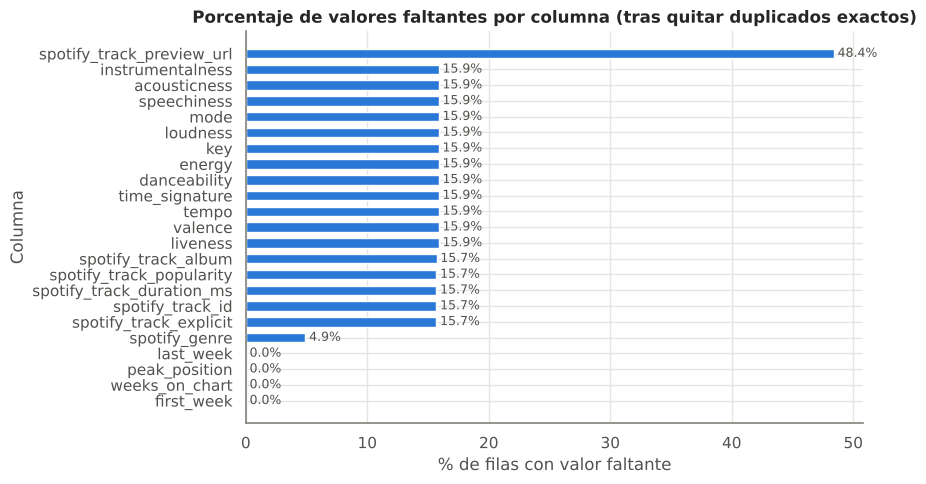

Filas SIN ninguna característica de audio: 5,161 (15.9%)
Filas con audio parcialmente faltante: 0


In [ ]:
falt = (df.drop(columns=["group_key", "bloque_no_verificable", "target_verificable"])
          .isna().mean().mul(100).sort_values(ascending=False))
falt = falt[falt > 0]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(falt.index[::-1], falt.values[::-1], color=CAT_COLORS[0], height=0.6)
for y, v in enumerate(falt.values[::-1]):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center", fontsize=9, color="#52514e")
ax.set_title("Porcentaje de valores faltantes por columna (tras quitar duplicados exactos)")
ax.set_xlabel("% de filas con valor faltante"); ax.set_ylabel("Columna")
plt.tight_layout(); plt.show()

AUDIO_COLS = ["danceability", "energy", "loudness", "speechiness", "acousticness",
              "instrumentalness", "liveness", "valence", "tempo"]
sin_audio = df[AUDIO_COLS].isna().all(axis=1)
parcial = df[AUDIO_COLS].isna().any(axis=1) & ~sin_audio
print(f"Filas SIN ninguna característica de audio: {sin_audio.sum():,} ({sin_audio.mean():.1%})")
print(f"Filas con audio parcialmente faltante: {parcial.sum()}")

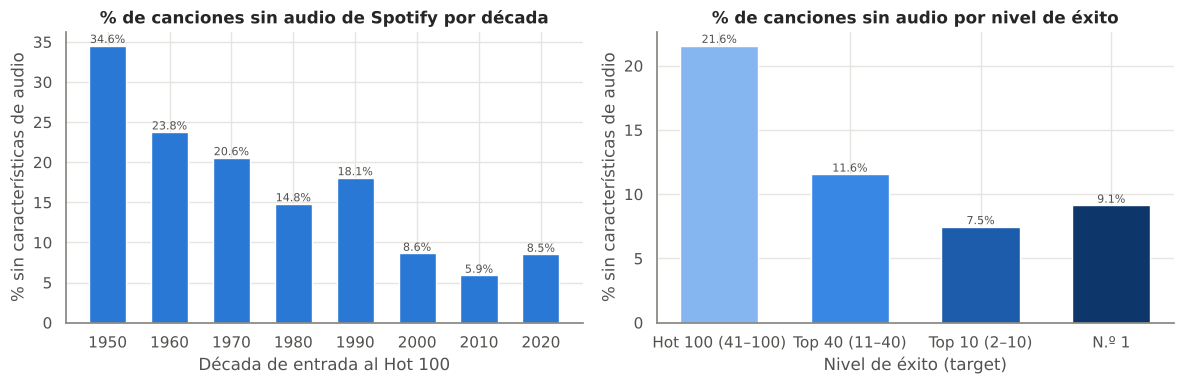

In [ ]:
# ¿El faltante es aleatorio? Comparamos la tasa de 'sin audio' por década y por nivel de éxito
df["entry_year"] = fw.dt.year.astype("Int64")
df["entry_decade"] = (df["entry_year"] // 10 * 10).astype("Int64")
tasa_dec = df.groupby("entry_decade")["danceability"].apply(lambda s: s.isna().mean() * 100)
tasa_tier = df.groupby(TARGET)["danceability"].apply(lambda s: s.isna().mean() * 100).reindex(TIER_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(tasa_dec.index.astype(str), tasa_dec.values, color=CAT_COLORS[0], width=0.6)
axes[0].set_title("% de canciones sin audio de Spotify por década")
axes[0].set_xlabel("Década de entrada al Hot 100"); axes[0].set_ylabel("% sin características de audio")
axes[1].bar(TIER_LABELS, tasa_tier.values, color=TIER_COLORS, width=0.6)
axes[1].set_title("% de canciones sin audio por nivel de éxito")
axes[1].set_xlabel("Nivel de éxito (target)"); axes[1].set_ylabel("% sin características de audio")
for ax in axes:
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

**Patrón observado.** El faltante del audio es **en bloque** (5.161 filas sin **ninguna** característica de audio y 0 filas con faltantes parciales): es un fallo de *matching* con Spotify, no un dato suelto que se perdió.

**¿Es aleatorio?** No:
- Por **década**: falta en el 34,6 % de las canciones de los años 50 y solo en el 5,9 % de las de los 2010.
- Por **nivel de éxito**: falta en el 21,6 % de las canciones *Hot 100 (41–100)* y solo en el 7,5–11,6 % de las demás clases.

Las canciones antiguas y menos exitosas tienen menos probabilidad de estar en el catálogo de Spotify. Es un faltante **no aleatorio (MNAR)**: la ausencia en sí misma está asociada al target.

**Utilidad:** muestra que una imputación ingenua sería peligrosa. Si se imputan esas 5.161 filas con un valor fijo, todas compartirían el mismo vector de audio "artificial" y el modelo aprendería que *"audio igual a la mediana" ⇒ canción poco exitosa*. Eso reflejaría la disponibilidad en Spotify (que a su vez depende del éxito posterior), no la música.

**Limitación:** el gráfico muestra asociación, no la causa exacta del fallo del *matching*.

### 2.4.1 Comparación de estrategias de imputación (variable: `danceability`)

Se comparan cuatro estrategias sobre el bloque histórico verificable. Se mide cuánto distorsiona cada una la distribución observada (media, desviación estándar y estadístico **Kolmogórov–Smirnov** frente a los valores reales; KS = 0 significa distribución idéntica).

,n filas,media,desv. estándar,mediana,KS vs observado
Observado (sin faltantes),24317.0000,0.5999,0.1531,0.6080,0.0000
Eliminación de filas (listwise),24317.0000,0.5999,0.1531,0.6080,0.0000
Imputación por media,29476.0000,0.5999,0.1391,0.5999,0.0912
Imputación por mediana,29476.0000,0.6013,0.1391,0.6080,0.0874
Mediana por década (grupo),29476.0000,0.5985,0.1406,0.6000,0.0621


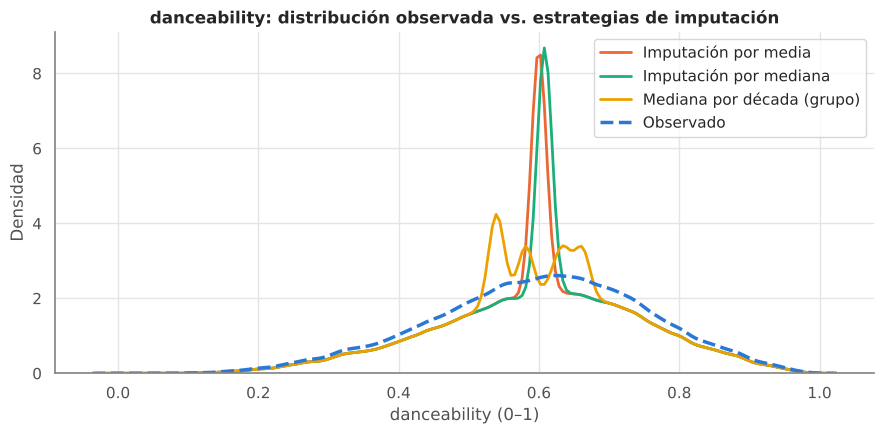

In [ ]:
base = df[~df["bloque_no_verificable"] & df["target_verificable"]].copy()
obs = base["danceability"].dropna()

estrategias = {
    "Observado (sin faltantes)": obs,
    "Eliminación de filas (listwise)": obs,
    "Imputación por media": base["danceability"].fillna(obs.mean()),
    "Imputación por mediana": base["danceability"].fillna(obs.median()),
    "Mediana por década (grupo)": base["danceability"].fillna(
        base.groupby("entry_decade")["danceability"].transform("median")).fillna(obs.median()),
}
comp = pd.DataFrame({
    nombre: {"n filas": len(s), "media": s.mean(), "desv. estándar": s.std(),
             "mediana": s.median(), "KS vs observado": stats.ks_2samp(s, obs).statistic}
    for nombre, s in estrategias.items()
}).T
display(comp)

fig, ax = plt.subplots(figsize=(9, 4.5))
for (nombre, s), color in zip(list(estrategias.items())[2:], CAT_COLORS[1:4]):
    sns.kdeplot(s, ax=ax, label=nombre, color=color, lw=2, bw_adjust=0.6)
sns.kdeplot(obs, ax=ax, label="Observado", color=CAT_COLORS[0], lw=2.5, ls="--", bw_adjust=0.6)
ax.set_title("danceability: distribución observada vs. estrategias de imputación")
ax.set_xlabel("danceability (0–1)"); ax.set_ylabel("Densidad"); ax.legend()
plt.tight_layout(); plt.show()

**Comparación (variable `danceability`, 5.159 faltantes en el bloque histórico verificable):**
- **Media y mediana global** conservan el centro de la distribución, pero **reducen la desviación estándar** de 0,153 a 0,139 y crean un pico artificial en un solo valor (KS ≈ 0,09).
- **Mediana por década** distorsiona algo menos (KS = 0,062) porque respeta la tendencia temporal, pero sigue inventando el perfil musical del 17,5 % de las canciones.
- **Eliminación de filas** conserva exactamente la distribución observada (KS = 0), a costa de reducir el tamaño de muestra y sub-representar las décadas antiguas y la clase *Hot 100*.

**Estrategia elegida (dos niveles):**
1. **Filas sin ninguna característica de audio → se excluyen del conjunto de modelado.** La pregunta de negocio es si *las características musicales* predicen el éxito. Si el 100 % del bloque musical es inventado, la fila no aporta información musical y además introduciría la fuga descrita arriba. El costo (sesgo hacia canciones disponibles en Spotify) se declara como limitación.
2. **Faltantes puntuales (los inválidos marcados en 2.6, 4 duraciones, 94 compases, 4 indicadores explícitos) → imputación por mediana (numéricas) o moda (categóricas/binarias) dentro del `Pipeline`**, ajustada **solo con entrenamiento**. Se elige la mediana porque es robusta ante las variables asimétricas (speechiness, instrumentalness, liveness).

`spotify_genre` faltante o vacío no se imputa: se convierte en el indicador `genre_unknown` (sección 2.8).

## 2.5 Valores atípicos: diagramas de caja y regla IQR

Regla IQR: un valor es atípico si está fuera de $[Q_1 - 1.5\,IQR,\; Q_3 + 1.5\,IQR]$, con $IQR = Q_3 - Q_1$. Se analiza el conjunto histórico verificable con audio.

,Q1,Q3,IQR,límite inf.,límite sup.,n atípicos,% atípicos,mín.,máx.
variable,,,,,,,,,
danceability,0.4990,0.7080,0.2090,0.1860,1.0210,85,0.3500,0.0000,0.9880
energy,0.4760,0.7770,0.3010,0.0240,1.2290,9,0.0370,0.0010,0.9970
loudness,-11.0360,-5.8580,5.1780,-18.8030,1.9090,180,0.7400,-28.0300,2.2910
speechiness,0.0320,0.0680,0.0360,-0.0220,0.1220,3370,13.8590,0.0000,0.9510
acousticness,0.0470,0.5080,0.4610,-0.6450,1.2000,0,0.0000,0.0000,0.9910
instrumentalness,0.0000,0.0000,0.0000,-0.0010,0.0010,5060,20.8080,0.0000,0.9820
liveness,0.0910,0.2480,0.1570,-0.1450,0.4840,1441,5.9260,0.0100,0.9990
valence,0.4150,0.8020,0.3870,-0.1660,1.3830,0,0.0000,0.0000,0.9910
tempo,99.0690,136.4880,37.4190,42.9410,192.6160,279,1.1470,0.0000,241.0090


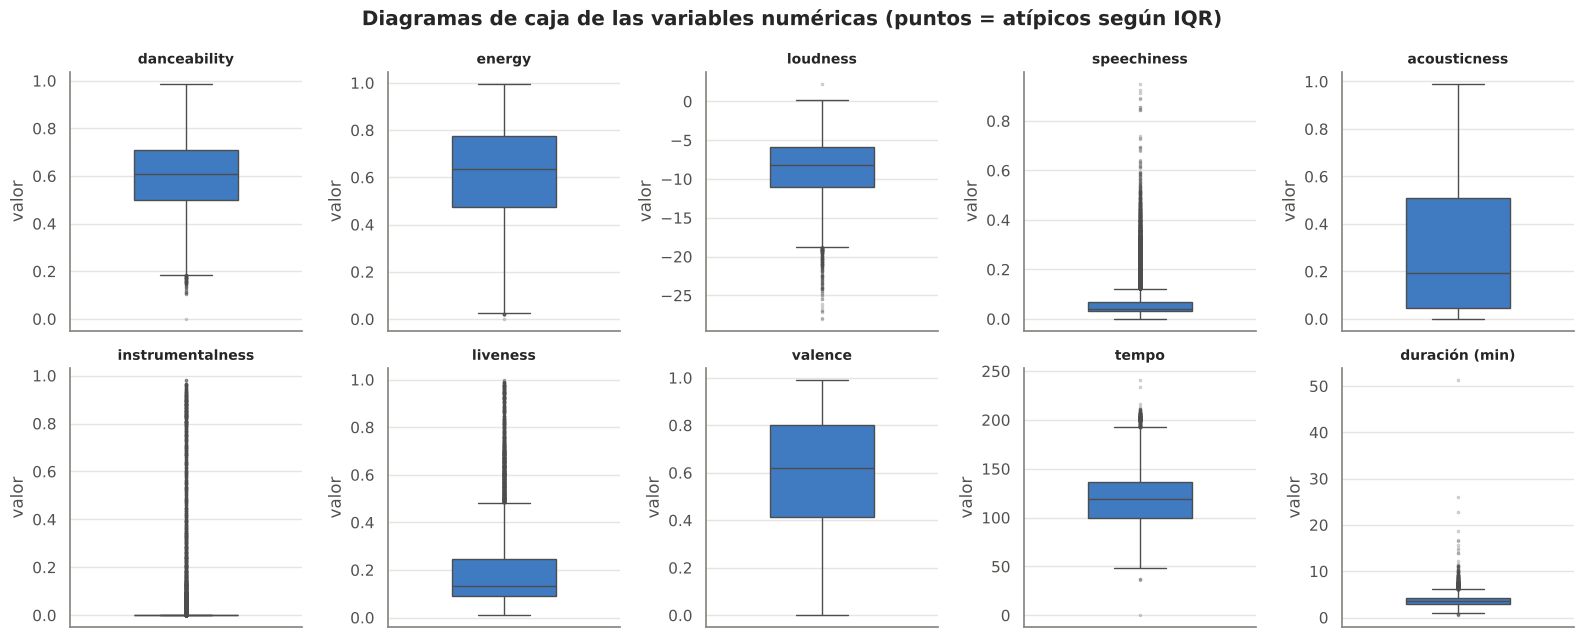

In [ ]:
NUM_EDA = AUDIO_COLS + ["spotify_track_duration_ms"]
eda_base = base.dropna(subset=AUDIO_COLS)

def iqr_table(frame, cols):
    filas = []
    for c in cols:
        s = frame[c].dropna()
        q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = ((s < lo) | (s > hi)).sum()
        filas.append({"variable": c, "Q1": q1, "Q3": q3, "IQR": iqr, "límite inf.": lo,
                      "límite sup.": hi, "n atípicos": n_out, "% atípicos": n_out / len(s) * 100,
                      "mín.": s.min(), "máx.": s.max()})
    return pd.DataFrame(filas).set_index("variable")

tabla_iqr = iqr_table(eda_base, NUM_EDA)
display(tabla_iqr.round(3))

fig, axes = plt.subplots(2, 5, figsize=(16, 6.5))
for ax, c in zip(axes.ravel(), NUM_EDA):
    serie = eda_base[c] / 60000 if c == "spotify_track_duration_ms" else eda_base[c]
    sns.boxplot(y=serie, ax=ax, color=CAT_COLORS[0], width=0.45, fliersize=1.5,
                flierprops={"alpha": 0.3})
    ax.set_title(c if c != "spotify_track_duration_ms" else "duración (min)", fontsize=10)
    ax.set_ylabel("valor"); ax.set_xlabel("")
fig.suptitle("Diagramas de caja de las variables numéricas (puntos = atípicos según IQR)", fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
# Inspección de los casos más extremos de duración
cols_show = ["song_id", "spotify_track_album", "spotify_track_duration_ms", "peak_position", "first_week"]
extremos = eda_base.assign(duracion_min=eda_base["spotify_track_duration_ms"] / 60000)
display(extremos.nlargest(5, "duracion_min")[cols_show + ["duracion_min"]])
display(extremos.nsmallest(3, "duracion_min")[cols_show + ["duracion_min"]])

,song_id,spotify_track_album,spotify_track_duration_ms,peak_position,first_week,duracion_min
22192,SexualGoddess,Sacral Chakra - Releaing Your Creative & Sexua...,3079157.0000,74.0000,1992-12-12,51.3193
3723,Tubular BellsMike Oldfield,Tubular Bells,1561133.0000,7.0000,1974-02-23,26.0189
9242,AutobahnKraftwerk,Autobahn (2009 Remaster),1367093.0000,25.0000,1975-03-15,22.7849
12413,By The Time I Get To PhoenixIsaac Hayes,Hot Buttered Soul,1124153.0000,37.0000,1969-08-30,18.7359
1450,Love To Love You BabyDonna Summer,Love To Love You Baby,1008533.0000,2.0000,1975-12-06,16.8089


,song_id,spotify_track_album,spotify_track_duration_ms,peak_position,first_week,duracion_min
9388,Raise The RoofLuke Featuring No Good But So Good,Changin' the Game,29688.0000,26.0000,1998-03-28,0.4948
29324,Beautiful TripKid Cudi,"{'album_type': 'album', 'artists': [{'external...",37013.0000,100.0000,2020-12-26,0.6169
13058,Think Of YouChris Young Duet With Cassadee Pope,I'm Comin' Over - Stories Behind the Songs,46253.0000,40.0000,2016-03-05,0.7709


**Análisis por variable y decisión:**

| Variable | % atípicos (IQR) | ¿Qué representan? | Decisión |
|---|---|---|---|
| `instrumentalness` | 20,8 % | La mayoría de canciones vale ≈ 0 (tienen voz), así que IQR ≈ 0 y **cualquier** canción instrumental cae fuera. Valores **válidos**. | Conservar |
| `speechiness` | 13,9 % | Rap y canciones habladas tienen valores altos. **Válidos** y relevantes por género. | Conservar |
| `liveness` | 5,9 % | Grabaciones en vivo. **Válidos**. | Conservar |
| `loudness` | 0,7 % | Canciones antiguas o acústicas muy suaves (hasta −28 dB). **Válidos**. | Conservar |
| `tempo` | 1,1 % | Tempos muy lentos o muy rápidos (el estimador a veces duplica o divide a la mitad el BPM). El único 0 BPM es **inválido** (2.6). | Conservar; 0 → NaN |
| duración | 2,3 % | Versiones largas reales (*Tubular Bells* 26 min, *Autobahn* 23 min, *Love To Love You Baby* 17 min) y un caso de **posible error de *matching***: *Sexual* de Goddess (pico 74) asociado a un álbum de meditación de **51 min**. | Conservar (sin evidencia suficiente para eliminar); queda marcado para revisión |
| danceability, energy | < 0,4 % | Valores extremos plausibles. | Conservar |

**Justificación general:** el enunciado pide no eliminar automáticamente. Los atípicos son, en su mayoría, **variación musical real** y eliminarlos sesgaría el análisis contra géneros minoritarios. En vez de eliminarlos se usan modelos robustos (Random Forest) y escalado con la mediana como imputador; la regresión logística y la red reciben datos estandarizados.

## 2.6 Revisión de valores inválidos o incoherentes

Se buscan valores **imposibles o sospechosos**; no se eliminan automáticamente.

In [ ]:
lw = pd.to_datetime(df["last_week"], errors="coerce")
span_sem = (lw - fw).dt.days / 7 + 1
reglas = {
    "tempo = 0 BPM (imposible en música con pulso)": df["tempo"].eq(0),
    "danceability = 0": df["danceability"].eq(0),
    "time_signature ∈ {0, 1} (compás no válido/indeterminado)": df["time_signature"].isin([0, 1]),
    "loudness > 0 dB (inusual, posible pero raro)": df["loudness"].gt(0),
    "duración > 15 min": df["spotify_track_duration_ms"].gt(15 * 60000),
    "last_week anterior a first_week": lw.lt(fw),
    "weeks_on_chart > semanas entre first y last week": df["weeks_on_chart"].gt(span_sem + 0.5),
    "peak_position/fechas faltantes con target presente": df["peak_position"].isna(),
}
tabla_inv = pd.DataFrame({"n filas": {k: int(v.sum()) for k, v in reglas.items()}})
display(tabla_inv)
display(df.loc[reglas["weeks_on_chart > semanas entre first y last week"],
               ["song_id", "weeks_on_chart", "first_week", "last_week"]].head(5))

,n filas
tempo = 0 BPM (imposible en música con pulso),1
danceability = 0,1
"time_signature ∈ {0, 1} (compás no válido/indeterminado)",95
"loudness > 0 dB (inusual, posible pero raro)",2
duración > 15 min,8
last_week anterior a first_week,0
weeks_on_chart > semanas entre first y last week,14
peak_position/fechas faltantes con target presente,3


,song_id,weeks_on_chart,first_week,last_week
1229,34+35Ariana Grande Feat. Doja Cat & Megan Thee...,28.0000,2021-01-02,2021-05-22
2619,Even Though I'm LeavingLuke Combs,42.0000,2019-06-22,2020-02-22
2620,Even Though I'm LeavingLuke Combs,42.0000,2019-06-22,2020-02-22
4251,"Eastsidebenny blanco, Halsey & Khalid",52.0000,2019-01-05,2019-07-20
5023,RITMO (Bad Boys For Life)Black Eyed Peas X J B...,32.0000,2020-01-04,2020-06-06


**Decisiones:**
- `tempo = 0` (1 fila), `danceability = 0` (1 fila) y `time_signature ∈ {0, 1}` (95 filas): valores **físicamente imposibles o indeterminados** en la API. **No se eliminan las filas**: el valor se convierte en `NaN` y el `Pipeline` lo imputa (mediana o moda, ajustadas con entrenamiento).
- `loudness > 0 dB` (2 filas): inusual, pero posible en masterizaciones muy comprimidas. **Se conserva.**
- Duraciones > 15 min (8 filas): ver 2.5. **Se conservan.**
- `weeks_on_chart` mayor que el lapso entre primera y última semana (14 filas, p. ej. *Even Though I'm Leaving*: 42 semanas en un lapso de 36): **incoherencia** probablemente por reingresos o por cómo el autor agregó las fechas. **No afecta al modelo** porque `weeks_on_chart` y las fechas están excluidas como predictores, pero se documenta.
- `last_week` anterior a `first_week`: 0 casos.
- 3 filas sin `peak_position` ni fechas: target **no verificable** → excluidas del modelado.

In [ ]:
# Aplicamos la decisión: valores imposibles → NaN (se imputarán dentro del Pipeline, ajustado solo con train)
df.loc[df["tempo"].eq(0), "tempo"] = np.nan
df.loc[df["danceability"].eq(0), "danceability"] = np.nan
df.loc[df["time_signature"].isin([0, 1]), "time_signature"] = np.nan
print("Nulos tras marcar inválidos:", df[["tempo", "danceability", "time_signature"]].isna().sum().to_dict())

Nulos tras marcar inválidos: {'tempo': 5162, 'danceability': 5162, 'time_signature': 5256}


## 2.7 Procesamiento de fechas

In [ ]:
df["first_week_dt"] = fw
df["last_week_dt"] = lw
print("Rango de first_week:", fw.min().date(), "→", fw.max().date())
print("Fechas no convertibles:", fw.isna().sum())
display(df.groupby("entry_decade").size().rename("canciones").to_frame().T)

# Verificamos que musical_era es solo un corte del año de entrada (enriquecimiento derivado de la fecha)
display(df.groupby("musical_era")["entry_year"].agg(["min", "max", "size"]))

Rango de first_week: 1958-08-02 → 2026-10-10
Fechas no convertibles: 3


entry_decade,1950,1960,1970,1980,1990,2000,2010,2020
canciones,926,6852,5299,4114,3423,3419,4530,3913


,min,max,size
musical_era,,,
digital_streaming_explosion,2000,2021,8865
golden_rock_soul_era,1958,1979,13077
hyper_streaming_short_form_era,2021,2026,3000
mtv_synth_pop_boom,1980,1999,7537


**Resultado.** `first_week` y `last_week` se convierten a fecha sin errores (salvo las 3 filas sin fecha). El rango va de **1958-08-02 a 2026-10-10**, consistente con el periodo declarado por el autor. Se derivan `entry_year` y `entry_decade`.

La tabla confirma que `musical_era` (enriquecimiento IA) es **un simple corte del año de entrada** (1958–1979, 1980–1999, 2000–2021, 2021–2026). No aporta información musical: es **contexto temporal**.

**Uso de las fechas:** las fechas **no** se usan como predictores en el modelo principal (instrucción del proyecto: `first_week` y `last_week` excluidas). `last_week` además depende del resultado (cuánto duró en la lista). `entry_decade` se usa en el EDA (tendencias) y en el experimento exploratorio C con `musical_era`, para medir cuánto aporta el contexto temporal.

## 2.8 Tratamiento de `spotify_genre`

La columna contiene **listas serializadas como texto** (p. ej. `"['dance pop', 'pop']"`). Se convierten a listas reales con `ast.literal_eval` y, como hay cientos de géneros distintos, se agrupan en **macro-géneros** mediante palabras clave (codificación *multi-hot*: una canción puede ser "pop" y "dance" a la vez). Los valores nulos y las listas vacías `[]` se marcan como `genre_unknown`.

In [ ]:
def parse_genres(x):
    if pd.isna(x): return []
    try:
        val = ast.literal_eval(x)
        return [g.strip().lower() for g in val] if isinstance(val, list) else []
    except (ValueError, SyntaxError):
        return []

df["genre_list"] = df["spotify_genre"].apply(parse_genres)
print("Ejemplo:", df.loc[0, "spotify_genre"], "→", df.loc[0, "genre_list"])
print(f"Nulos: {df['spotify_genre'].isna().sum():,} | listas vacías '[]': {(df['spotify_genre'] == '[]').sum():,}")
todos = pd.Series([g for lst in df["genre_list"] for g in lst])
print(f"Géneros distintos: {todos.nunique():,}")
display(todos.value_counts().head(15).rename("frecuencia").to_frame().T)

MACRO_GENRES = {
    "genre_pop": ["pop"],
    "genre_rock": ["rock", "metal", "punk", "grunge"],
    "genre_hiphop_rap": ["hip hop", "rap", "trap", "drill"],
    "genre_rnb_soul_funk": ["r&b", "soul", "funk", "motown", "disco", "quiet storm"],
    "genre_country_folk": ["country", "folk", "americana", "bluegrass"],
    "genre_dance_electronic": ["dance", "edm", "house", "electro", "techno"],
    "genre_latin": ["latin", "reggaeton", "salsa", "bachata", "urbano"],
    "genre_jazz_blues": ["jazz", "blues", "swing", "big band"],
}
for col, kws in MACRO_GENRES.items():
    df[col] = df["genre_list"].apply(lambda lst: int(any(k in g for g in lst for k in kws)))
df["genre_unknown"] = df["genre_list"].apply(lambda lst: int(len(lst) == 0))
GENRE_COLS = list(MACRO_GENRES) + ["genre_unknown"]
display(df[GENRE_COLS].mean().mul(100).round(1).rename("% de canciones").to_frame().T)

Ejemplo: ['canadian contemporary r&b', 'canadian pop', 'pop'] → ['canadian contemporary r&b', 'canadian pop', 'pop']
Nulos: 1,596 | listas vacías '[]': 2,557
Géneros distintos: 1,157


,mellow gold,pop,soft rock,adult standards,dance pop,brill building pop,rock,soul,pop rap,motown,rap,folk rock,album rock,classic rock,hip hop
frecuencia,3961,3952,3880,3723,3467,3305,3236,2978,2901,2769,2552,2538,2433,2411,2295


,genre_pop,genre_rock,genre_hiphop_rap,genre_rnb_soul_funk,genre_country_folk,genre_dance_electronic,genre_latin,genre_jazz_blues,genre_unknown
% de canciones,47.5000,33.7000,16.2000,22.3000,19.0000,15.6000,1.4000,12.0000,12.8000


## 2.9 Ingeniería de características

| Nueva variable | Fórmula | Utilidad | ¿Revela el target? |
|---|---|---|---|
| `duration_minutes` | `spotify_track_duration_ms / 60000` | Unidad interpretable para negocio; permite analizar la tendencia a canciones más cortas. | No: es una propiedad de la grabación. |
| `dance_energy` | `danceability × energy` | Interacción: canciones a la vez bailables **y** enérgicas (un modelo lineal no la capta por sí solo). | No: combina dos rasgos de audio. |
| Macro-géneros (`genre_*`) | Palabras clave sobre `spotify_genre` | Reduce cientos de géneros a 9 indicadores manejables. | No usa información de la lista. |
| `explicit` | `spotify_track_explicit` → 0/1 | Convierte el booleano (con nulos) a numérico. | No. |
| `entry_decade` | década de `first_week` | **Solo** para EDA (tendencias) y el experimento exploratorio C; no entra al modelo principal. | No revela el pico, pero aporta contexto temporal (ver 2.10). |

In [ ]:
df["duration_minutes"] = df["spotify_track_duration_ms"] / 60000
df["dance_energy"] = df["danceability"] * df["energy"]
df["explicit"] = df["spotify_track_explicit"].astype(str).map({"True": 1, "False": 0})  # NaN si falta
display(df[["duration_minutes", "dance_energy", "explicit"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
duration_minutes,27381.0000,3.6462,1.0811,0.4948,2.9380,3.5622,4.1240,51.3193
dance_energy,27317.0000,0.3782,0.1570,0.0002,0.2621,0.3821,0.4918,0.9270
explicit,27381.0000,0.1626,0.3690,0.0000,0.0000,0.0000,0.0000,1.0000


## 2.10 Reto: *data leakage* (fuga de datos) y su prevención

**¿Qué es?** Hay *data leakage* cuando el modelo usa, durante el entrenamiento, información que **no estaría disponible en el momento de predecir** o que **contiene la respuesta**. El resultado son métricas espectacularmente altas que no se sostienen en el uso real.

**Ejemplo concreto en este dataset:** `peak_position` es la mejor posición alcanzada. Como el target es un corte directo de esa columna (ver 1.10), un modelo que la incluya "acierta" al 100 % sin aprender nada sobre la música. Lo mismo ocurre, de forma menos obvia, con otras columnas. Se auditan una por una:

In [ ]:
aud_df = df[df["target_verificable"]].copy()

# 1) Textos generados por IA: ¿mencionan literalmente el target o el pico?
cot_menciona = aud_df.apply(lambda r: r[TARGET] in str(r["cot_rationale"]), axis=1).mean()
ev_menciona = aud_df["evidence_span"].str.contains(r"peak=\d+", regex=True).mean()
print(f"cot_rationale contiene literalmente el target: {cot_menciona:.1%}")
print(f"evidence_span contiene 'peak=<posición>':        {ev_menciona:.1%}")

# 2) hit_longevity_profile vs weeks_on_chart
print("\nhit_longevity_profile = cortes de weeks_on_chart:")
display(aud_df.groupby("hit_longevity_profile")["weeks_on_chart"].agg(["min", "max", "size"]).sort_values("min"))

# 3) confidence_score: ¿cambia según el target?
print("confidence_score medio por clase:")
display(aud_df.groupby(TARGET)["confidence_score"].agg(["mean", "std"]).reindex(TIER_ORDER))
kw = stats.kruskal(*[g["confidence_score"].values for _, g in aud_df.groupby(TARGET)])
f1_conf = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=SEED),
                          aud_df[["confidence_score"]], aud_df[TARGET], cv=5, scoring="f1_macro").mean()
print(f"Kruskal-Wallis H = {kw.statistic:,.1f}, p = {kw.pvalue:.2e}")
print(f"Macro F1 de un árbol que usa SOLO confidence_score: {f1_conf:.3f}")

# 4) spotify_track_popularity vs peak_position
rho_pop = stats.spearmanr(aud_df["spotify_track_popularity"], aud_df["peak_position"], nan_policy="omit")
print(f"\nSpearman(popularidad Spotify, peak_position) = {rho_pop.statistic:.3f}")

# 5) acoustic_mood_cluster: ¿se reconstruye solo con variables de audio?
con_audio = aud_df.dropna(subset=["energy", "valence"])
arbol_mood = DecisionTreeClassifier(max_depth=5, random_state=SEED)
acc_mood = cross_val_score(arbol_mood, con_audio[["energy", "valence"]],
                           con_audio["acoustic_mood_cluster"], cv=5).mean()
print(f"\nacoustic_mood_cluster reconstruido con SOLO energy y valence: accuracy = {acc_mood:.4f}")
print(export_text(arbol_mood.fit(con_audio[["energy", "valence"]], con_audio["acoustic_mood_cluster"]),
                  feature_names=["energy", "valence"], max_depth=3))
print("Valor de acoustic_mood_cluster en filas SIN audio:",
      aud_df.loc[aud_df["energy"].isna(), "acoustic_mood_cluster"].value_counts().to_dict())

# 6) Demostración: un modelo con peak_position "acierta" trivialmente
f1_peak = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=SEED),
                          aud_df[["peak_position"]], aud_df[TARGET], cv=5, scoring="f1_macro").mean()
print(f"\nDemostración de fuga: macro F1 usando SOLO peak_position = {f1_peak:.3f}")

cot_rationale contiene literalmente el target: 100.0%
evidence_span contiene 'peak=<posición>':        100.0%

hit_longevity_profile = cortes de weeks_on_chart:


,min,max,size
hit_longevity_profile,,,
fleeting_entry,1.0000,9.0000,15133
standard_chart_run,10.0000,19.0000,11343
sustained_radio_hit,20.0000,29.0000,5155
mega_marathon_hit,30.0000,87.0000,845


confidence_score medio por clase:


,mean,std
chart_success_tier,,
hot_100_entry,0.9931,0.0072
top_forty_hit,0.9868,0.0135
top_ten_smash,0.9737,0.0128
historic_number_one,0.9517,0.0056


Kruskal-Wallis H = 17,277.9, p = 0.00e+00
Macro F1 de un árbol que usa SOLO confidence_score: 0.483

Spearman(popularidad Spotify, peak_position) = -0.399



acoustic_mood_cluster reconstruido con SOLO energy y valence: accuracy = 1.0000
|--- energy <= 0.70
|   |--- energy <= 0.60
|   |   |--- valence <= 0.50
|   |   |   |--- energy <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- energy >  0.50
|   |   |   |   |--- class: balanced_acoustic_pop
|   |   |--- valence >  0.50
|   |   |   |--- class: chill_downtempo_groove
|   |--- energy >  0.60
|   |   |--- class: balanced_acoustic_pop
|--- energy >  0.70
|   |--- valence <= 0.60
|   |   |--- valence <= 0.50
|   |   |   |--- class: intense_aggressive_drive
|   |   |--- valence >  0.50
|   |   |   |--- class: balanced_acoustic_pop
|   |--- valence >  0.60
|   |   |--- class: high_energy_euphoric

Valor de acoustic_mood_cluster en filas SIN audio: {'balanced_acoustic_pop': 5159}



Demostración de fuga: macro F1 usando SOLO peak_position = 0.995


**Resultado de la auditoría:**

| Variable | Evidencia | Decisión |
|---|---|---|
| `peak_position` | Define el target; un árbol con solo esta columna obtiene **macro F1 = 0,995** | **Excluida** |
| `weeks_on_chart`, `last_week` | Resultado del recorrido en la lista (posterior a la entrada) | **Excluidas** |
| `first_week` | Excluida por instrucción del proyecto; solo se usa para EDA | **Excluida** del modelo principal |
| `hit_longevity_profile` | Es exactamente `weeks_on_chart` cortado en <10, 10–19, 20–29 y ≥30 semanas | **Excluida** (análisis aparte en 4.9.1) |
| `cot_rationale` | **El 100 %** de los textos menciona literalmente la clase del target | **Excluida** |
| `evidence_span` | **El 100 %** incluye `peak=<posición>` y las semanas | **Excluida** |
| `confidence_score` | Su media baja de forma sistemática con el éxito (0,993 en *Hot 100* → 0,952 en *N.º 1*; Kruskal-Wallis p ≈ 0). Un árbol con **solo** esta columna logra macro F1 = **0,483**, más que cualquier modelo con audio. Su significado no está documentado y se comporta como un subproducto del resultado | **Excluida** |
| `spotify_track_popularity` | Correlación de Spearman con `peak_position` = −0,40. No se documenta **cuándo** se midió (probablemente al descargar los datos, años después del paso por la lista) y el éxito pasado alimenta la popularidad actual | **Excluida** (fuga temporal probable) |
| `acoustic_mood_cluster` | Se reconstruye con **100 % de exactitud** usando solo `energy` y `valence` (reglas con umbrales 0,5/0,6/0,7). No usa información del resultado. En filas sin audio vale siempre `balanced_acoustic_pop` (valor por defecto) | **Permitida solo en el Modelo B** (segura, pero redundante) |
| `musical_era` | Corte del año de entrada | Solo en el experimento exploratorio C |

**¿Cómo se evita la fuga en el resto del flujo?**
1. Las columnas anteriores se excluyen de los predictores y un `assert` lo comprueba en código.
2. Imputación, escalado y One-Hot viven dentro de un `Pipeline`/`ColumnTransformer` que se **ajusta solo con entrenamiento** (en la validación cruzada, solo con los folds de entrenamiento).
3. El split es **agrupado** por canción/pista (`group_key`), así que un mismo audio nunca está en entrenamiento y prueba a la vez.
4. Los hiperparámetros, el umbral del reto final y la mejor red se eligen con validación, **nunca con el conjunto de prueba**.

## 2.11 Conjunto analítico de modelado y preparación de X e y

Filtros aplicados (cada uno justificado arriba) y **conjuntos de predictores**:
- **Conjunto principal (= Modelo A):** características musicales originales de Spotify + variables derivadas seguras. Es el que usan todos los modelos del Bloque 4 y la red neuronal del Bloque 5.
- **Modelo B:** principal + `acoustic_mood_cluster` (enriquecimiento IA auditado).
- **Experimento C (exploratorio):** principal + `musical_era` (contexto temporal, derivado de la fecha).

In [ ]:
# --- Embudo de filtros (no se borra df; se crea un subconjunto analítico) ---
paso0 = df
paso1 = paso0[paso0["target_verificable"]]
paso2 = paso1[~paso1["bloque_no_verificable"]] if EXCLUIR_BLOQUE_NO_VERIFICABLE else paso1
paso3 = paso2[paso2[["energy", "valence", "loudness"]].notna().all(axis=1)]   # filas con audio de Spotify
embudo = pd.DataFrame({"filas": [len(paso0), len(paso1), len(paso2), len(paso3)]},
                      index=["Tras quitar duplicados exactos", "Con target verificable (peak_position)",
                             "Sin bloque de procedencia no verificable", "Con características de audio (conjunto analítico)"])
display(embudo)
df_model = paso3.copy().reset_index(drop=True)

# --- Definición de predictores ---
NUM_FEATURES = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                "instrumentalness", "liveness", "valence", "tempo", "duration_minutes", "dance_energy"]
CAT_FEATURES = ["key", "time_signature"]                 # nominales → One-Hot
BIN_FEATURES = ["mode", "explicit"] + GENRE_COLS          # ya son 0/1
FEATURES_MAIN = NUM_FEATURES + CAT_FEATURES + BIN_FEATURES  # Conjunto principal = Modelo A
FEATURES_B = FEATURES_MAIN + ["acoustic_mood_cluster"]
FEATURES_C = FEATURES_MAIN + ["musical_era"]

LEAKAGE_EXCLUDED = ["peak_position", "weeks_on_chart", "first_week", "last_week", "hit_longevity_profile",
                    "cot_rationale", "evidence_span", "spotify_track_popularity", "confidence_score"]
assert not set(LEAKAGE_EXCLUDED) & set(FEATURES_B + FEATURES_C), "¡Fuga! Variable prohibida en predictores"

y_map = {t: i for i, t in enumerate(TIER_ORDER)}
X_all = df_model[list(dict.fromkeys(FEATURES_B + FEATURES_C))]
y_all = df_model[TARGET].map(y_map).astype(int)
groups_all = df_model["group_key"]
print(f"X: {X_all.shape} | y: {y_all.shape} | predictores principales: {len(FEATURES_MAIN)}")
print("Nulos restantes en predictores (se imputan en el Pipeline):",
      X_all[FEATURES_MAIN].isna().sum()[lambda s: s > 0].to_dict())

,filas
Tras quitar duplicados exactos,32479
Con target verificable (peak_position),32476
Sin bloque de procedencia no verificable,29476
Con características de audio (conjunto analítico),24317


X: (24317, 26) | y: (24317,) | predictores principales: 24
Nulos restantes en predictores (se imputan en el Pipeline): {'danceability': 1, 'tempo': 1, 'duration_minutes': 4, 'dance_energy': 1, 'time_signature': 94, 'explicit': 4}


### Preprocesamiento con `ColumnTransformer` (se ajusta **solo** con entrenamiento)

| Tipo | Variables | Transformación | Justificación |
|---|---|---|---|
| Numéricas continuas | audio, `duration_minutes`, `dance_energy` | Imputación por **mediana** + `StandardScaler` | La mediana es robusta a atípicos; el escalado es necesario para la regresión logística y la red neuronal (los árboles no lo necesitan, pero no les afecta). |
| Categóricas nominales | `key`, `time_signature` | Imputación por moda + **One-Hot** | `key` es una clase de tono circular (0 = Do, 11 = Si): codificarla como número inventaría un orden falso. Se evita Label Encoding arbitrario. |
| Binarias | `mode`, `explicit`, macro-géneros | Imputación por moda, sin escalar | Ya están en 0/1. |
| Enriquecimiento (B / C) | `acoustic_mood_cluster`, `musical_era` | One-Hot | Categorías nominales. |

El *target* se codifica de forma ordinal (0 = Hot 100 … 3 = N.º 1) solo como etiqueta de clase; los modelos lo tratan como **multiclase**.

In [ ]:
def make_preprocessor(extra_cats=()):
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    binp = SimpleImputer(strategy="most_frequent")
    return ColumnTransformer([
        ("num", num, NUM_FEATURES),
        ("cat", cat, CAT_FEATURES + list(extra_cats)),
        ("bin", binp, BIN_FEATURES),
    ], verbose_feature_names_out=False)

preprocessor = make_preprocessor()
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer

<a id="b3"></a>
# Bloque 3 · Análisis exploratorio y visualización (20 pts)

El EDA es **descriptivo** y se realiza sobre el conjunto analítico (`df_model`). Ningún parámetro del modelo se ajusta con estas gráficas: las transformaciones se aprenden después, solo con el conjunto de entrenamiento.

In [ ]:
eda = df_model.copy()
eda["tier_label"] = pd.Categorical(eda[TARGET].map(dict(zip(TIER_ORDER, TIER_LABELS))),
                                   categories=TIER_LABELS, ordered=True)
eda["tier_ord"] = eda[TARGET].map(y_map)
print(f"Filas para EDA: {len(eda):,}")

Filas para EDA: 24,317


## (a) Distribución de la variable objetivo

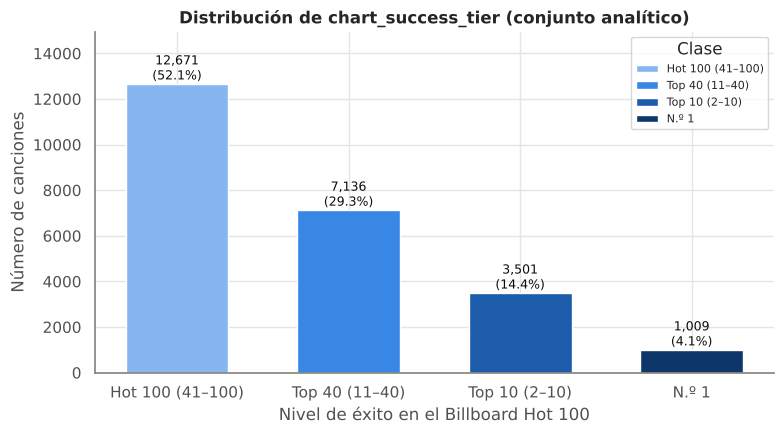

Razón de desbalance (clase mayoritaria / minoritaria): 12.6 : 1
Accuracy de un modelo que siempre predice la clase mayoritaria: 52.1%


In [ ]:
conteo = eda["tier_label"].value_counts().reindex(TIER_LABELS)
pct = conteo / conteo.sum() * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(TIER_LABELS, conteo.values, color=TIER_COLORS, width=0.6, label=TIER_LABELS)
for b, n, p in zip(bars, conteo.values, pct.values):
    ax.annotate(f"{n:,}\n({p:.1f}%)", (b.get_x() + b.get_width() / 2, b.get_height()),
                ha="center", va="bottom", fontsize=9, color="#0b0b0b")
ax.set_title("Distribución de chart_success_tier (conjunto analítico)")
ax.set_xlabel("Nivel de éxito en el Billboard Hot 100"); ax.set_ylabel("Número de canciones")
ax.set_ylim(0, conteo.max() * 1.18); ax.legend(title="Clase", fontsize=8)
plt.tight_layout(); plt.show()

ratio = conteo.max() / conteo.min()
print(f"Razón de desbalance (clase mayoritaria / minoritaria): {ratio:.1f} : 1")
print(f"Accuracy de un modelo que siempre predice la clase mayoritaria: {pct.max():.1f}%")

**Patrón:** el target está **desbalanceado**: *Hot 100 (41–100)* = 52,1 %, *Top 40* = 29,4 %, *Top 10* = 14,4 % y *N.º 1* = solo 4,1 % (1.009 canciones). La razón entre la clase mayoritaria y la minoritaria es **12,6 : 1**.

**Utilidad:** define la estrategia de evaluación. Un modelo que siempre responda "Hot 100" tendría **52,1 % de accuracy** sin aprender nada, por eso la accuracy no sirve como métrica principal.

**Limitación:** la distribución depende de cómo se construyó el dataset (canciones con audio disponible, sin el bloque no verificable). No representa la distribución de todas las canciones publicadas, solo de las que entraron a la lista.

## (b) Histogramas de variables numéricas

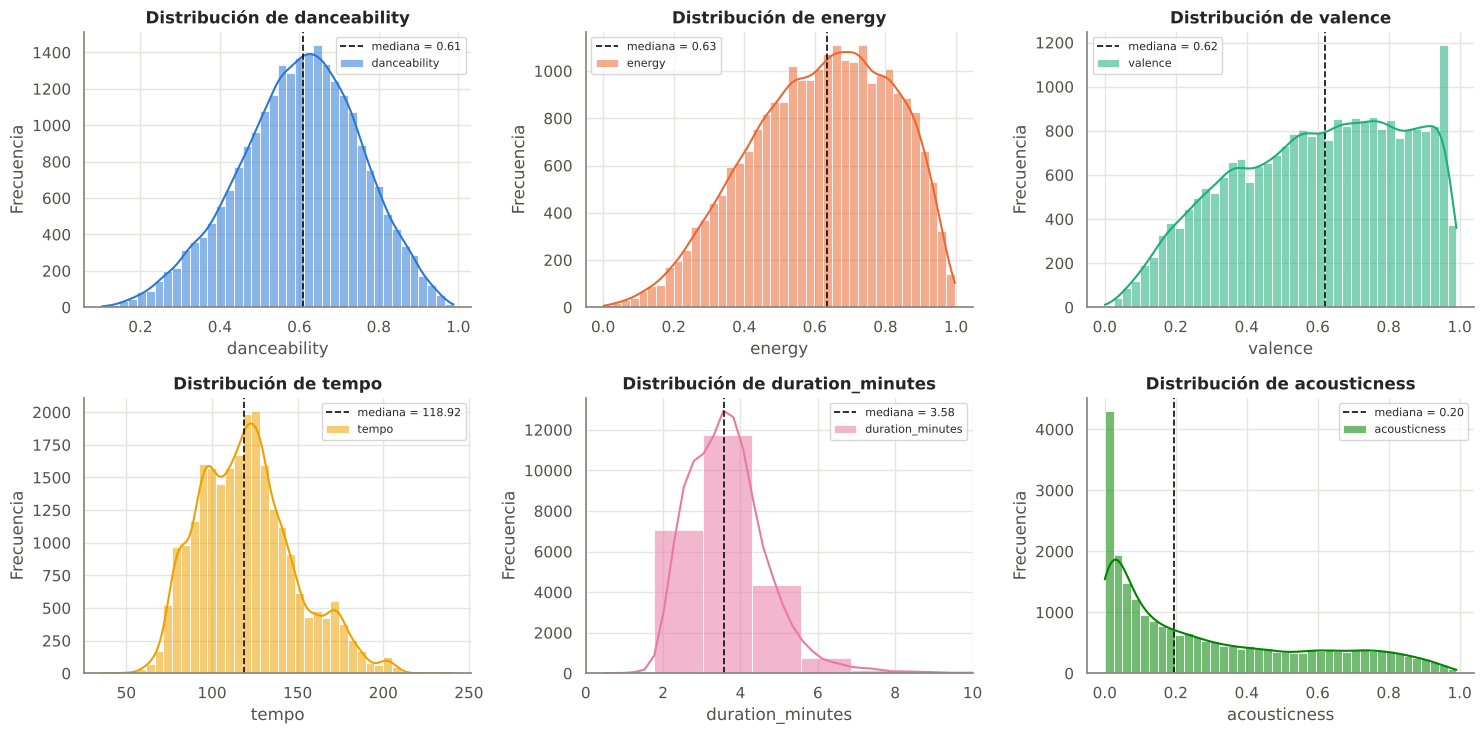

In [ ]:
hist_vars = ["danceability", "energy", "valence", "tempo", "duration_minutes", "acousticness"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, c, col in zip(axes.ravel(), hist_vars, CAT_COLORS):
    sns.histplot(eda[c].dropna(), bins=40, kde=True, ax=ax, color=col, alpha=0.55, label=c)
    ax.axvline(eda[c].median(), color="#0b0b0b", ls="--", lw=1.2, label=f"mediana = {eda[c].median():.2f}")
    ax.set_title(f"Distribución de {c}"); ax.set_xlabel(c); ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=8)
axes[1, 1].set_xlim(0, 10)  # recorte visual de la cola de duración (los atípicos se analizaron en 2.5)
plt.tight_layout(); plt.show()

**Patrón:**
- `danceability` es aproximadamente simétrica (mediana 0,61).
- `energy` y `valence` cubren casi todo el rango 0–1 (medianas 0,63 y 0,62); `valence` tiene un pico cerca de 0,96.
- `tempo` es multimodal (picos cerca de 100 y 120–125 BPM; mediana 118,9).
- `duration_minutes` se concentra entre 2 y 5 minutos (mediana 3,58) con una cola larga a la derecha.
- `acousticness` es muy asimétrica: muchas canciones casi sin carácter acústico.

**Utilidad:** justifica imputar con la **mediana** (robusta ante asimetrías) y **estandarizar** antes de la regresión logística y la red neuronal.

**Limitación:** son distribuciones marginales de todo el periodo 1958–2021; mezclan décadas con estilos muy distintos (ver gráfica g).

## (c) Diagramas de caja por nivel de éxito

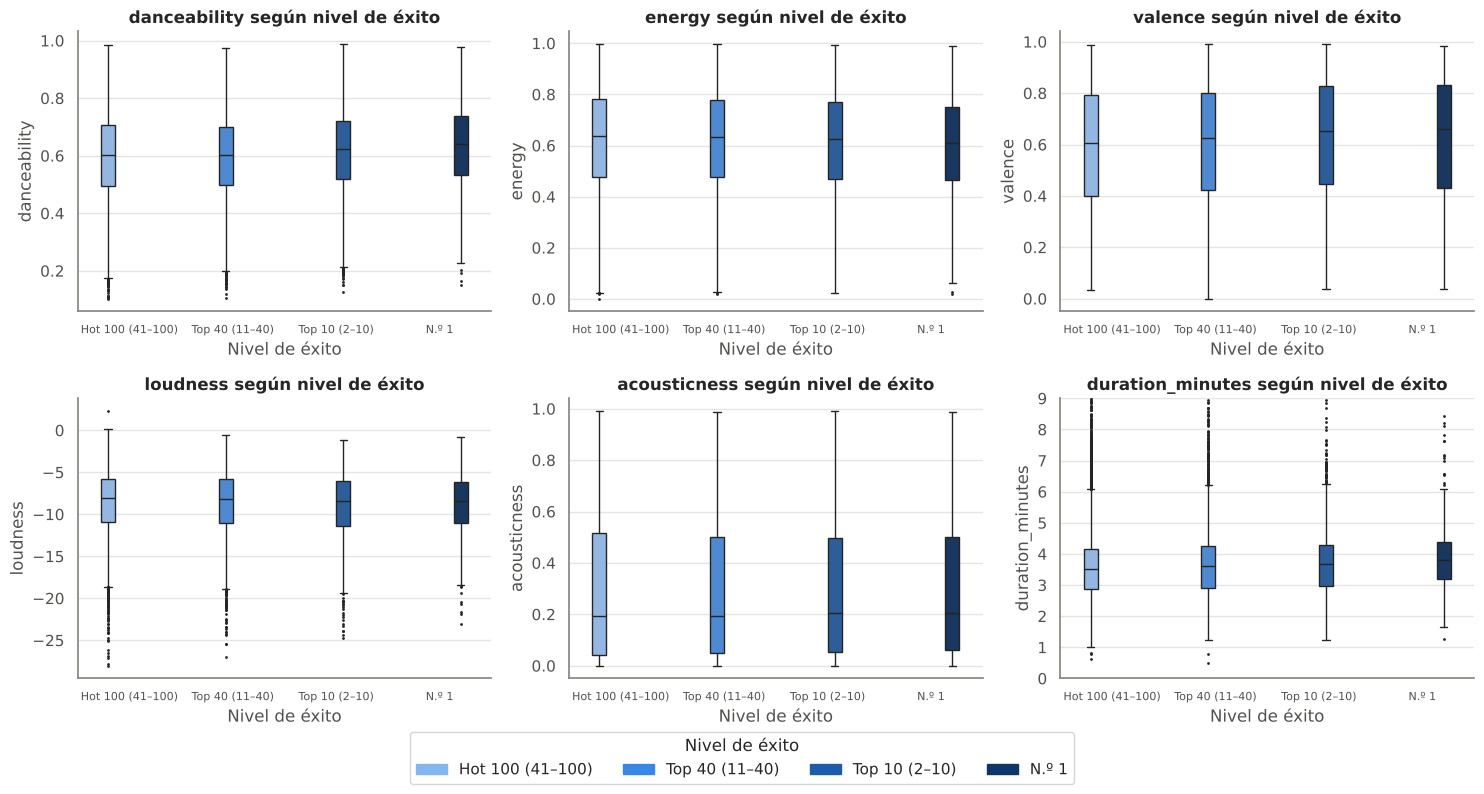

,danceability,energy,valence,loudness,acousticness,duration_minutes
tier_label,,,,,,
Hot 100 (41–100),0.6020,0.6390,0.6070,-8.1220,0.1920,3.5260
Top 40 (11–40),0.6040,0.6320,0.6260,-8.2270,0.1920,3.6020
Top 10 (2–10),0.6240,0.6260,0.6530,-8.4560,0.2050,3.6900
N.º 1,0.6410,0.6090,0.6620,-8.3610,0.2070,3.7980


In [ ]:
box_vars = ["danceability", "energy", "valence", "loudness", "acousticness", "duration_minutes"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), box_vars):
    sns.boxplot(data=eda, x="tier_label", y=c, hue="tier_label", palette=TIER_COLORS, ax=ax,
                fliersize=1, width=0.55, legend=False)
    ax.set_title(f"{c} según nivel de éxito"); ax.set_xlabel("Nivel de éxito"); ax.set_ylabel(c)
    ax.tick_params(axis="x", labelsize=8)
axes[1, 2].set_ylim(0, 9)
handles = [mpl.patches.Patch(color=c, label=l) for c, l in zip(TIER_COLORS, TIER_LABELS)]
plt.tight_layout(rect=(0, 0.06, 1, 1))
fig.legend(handles=handles, loc="lower center", ncol=4, title="Nivel de éxito", bbox_to_anchor=(0.5, 0.0))
plt.show()

display(eda.groupby("tier_label", observed=True)[box_vars].median().round(3))

**Patrón:** las medianas cambian de forma **muy leve y monótona** con el nivel de éxito:
- `danceability`: 0,602 (*Hot 100*) → 0,641 (*N.º 1*).
- `valence`: 0,607 → 0,662.
- `duration_minutes`: 3,53 → 3,80.
- `energy` baja ligeramente (0,639 → 0,609).

Sin embargo, las **cajas se solapan casi por completo** entre las cuatro clases.

**Utilidad:** anticipa el hallazgo central del proyecto: el audio contiene **una señal débil**. Ninguna variable separa por sí sola las clases, por lo que no se esperan métricas altas.

**Limitación:** comparar medianas no controla por década ni por género (p. ej., las canciones de los 70–80 duraban más y además tenían otra distribución de éxitos).

## (d) Mapa de calor de correlaciones

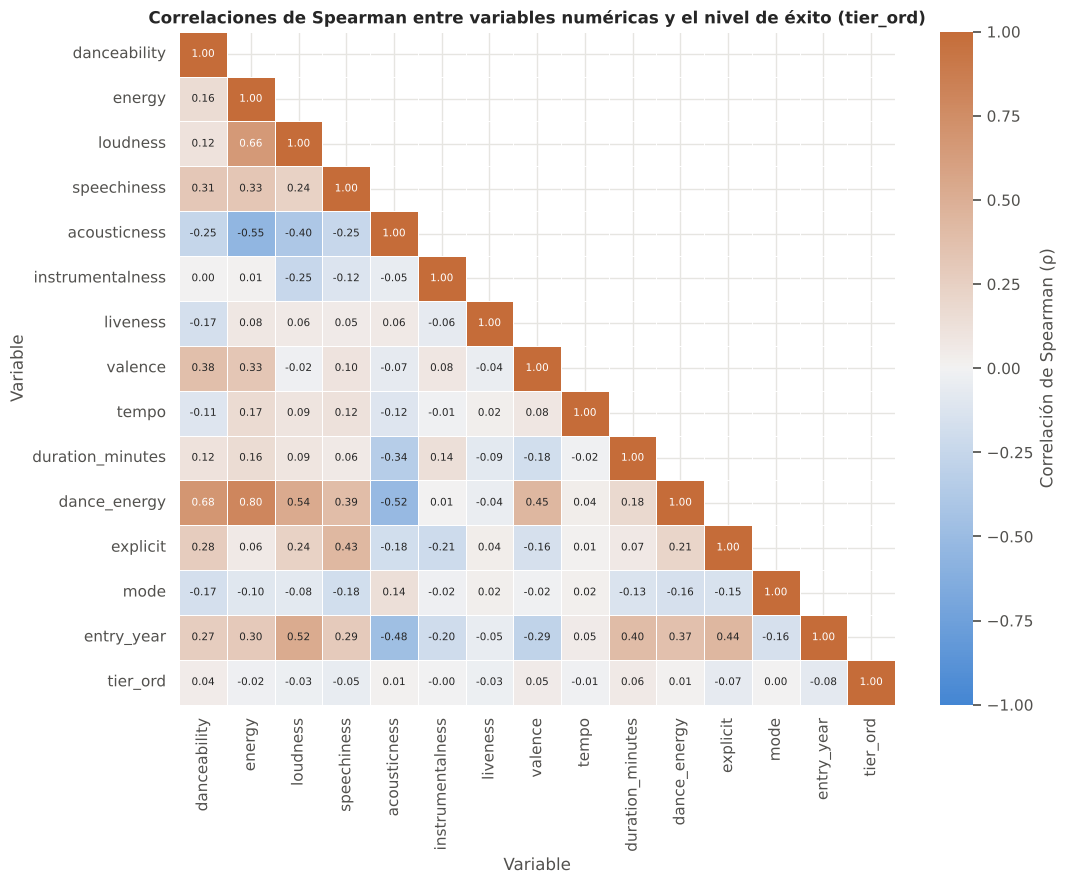

Correlación de cada variable con tier_ord (0 = Hot 100 … 3 = N.º 1):


,entry_year,explicit,duration_minutes,speechiness,valence,danceability,liveness,loudness,energy,tempo,acousticness,dance_energy,instrumentalness,mode
tier_ord,-0.0780,-0.0670,0.0580,-0.0510,0.0500,0.0450,-0.0300,-0.0280,-0.0220,-0.0140,0.0140,0.0080,-0.0020,0.0000


In [ ]:
corr_vars = ["danceability", "energy", "loudness", "speechiness", "acousticness", "instrumentalness",
             "liveness", "valence", "tempo", "duration_minutes", "dance_energy", "explicit", "mode", "entry_year", "tier_ord"]
corr = eda[corr_vars].corr(method="spearman")
mask_tri = np.triu(np.ones_like(corr, dtype=bool), k=1)
cmap_div = sns.diverging_palette(250, 30, s=80, l=55, center="light", as_cmap=True)  # azul–gris–naranja
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask_tri, cmap=cmap_div, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7.5}, linewidths=0.5, cbar_kws={"label": "Correlación de Spearman (ρ)"}, ax=ax)
ax.set_title("Correlaciones de Spearman entre variables numéricas y el nivel de éxito (tier_ord)")
ax.set_xlabel("Variable"); ax.set_ylabel("Variable")
plt.tight_layout(); plt.show()

print("Correlación de cada variable con tier_ord (0 = Hot 100 … 3 = N.º 1):")
display(corr["tier_ord"].drop("tier_ord").sort_values(key=abs, ascending=False).round(3).to_frame().T)

**Patrón (Spearman):**
- **Redundancias fuertes entre predictores:** `dance_energy` con `energy` (0,80) y `danceability` (0,68), por construcción; `energy`–`loudness` (0,66); `energy`–`acousticness` (−0,55).
- **Variables ligadas al tiempo:** `entry_year` correlaciona con `loudness` (0,52), `acousticness` (−0,48), `explicit` (0,44) y `duration_minutes` (0,40). El sonido de la música cambió con las décadas.
- **Con el target (`tier_ord`)**, todas las correlaciones son **muy débiles** (|ρ| ≤ 0,08): las mayores son `entry_year` (−0,08), `explicit` (−0,07), `duration_minutes` (+0,06), `speechiness` (−0,05) y `valence` (+0,05).

**Utilidad:** la redundancia sugiere usar regularización (incluida en la regresión logística) o modelos de árboles. La debilidad de las correlaciones con el target confirma lo visto en los boxplots.

**Limitaciones:** Spearman solo detecta relaciones **monótonas** entre pares; no capta interacciones (por ejemplo, que un rasgo importe solo en cierto género). **Correlación no es causalidad** (ver 3.8).

## (e) Gráfico de dispersión diferenciando grupos

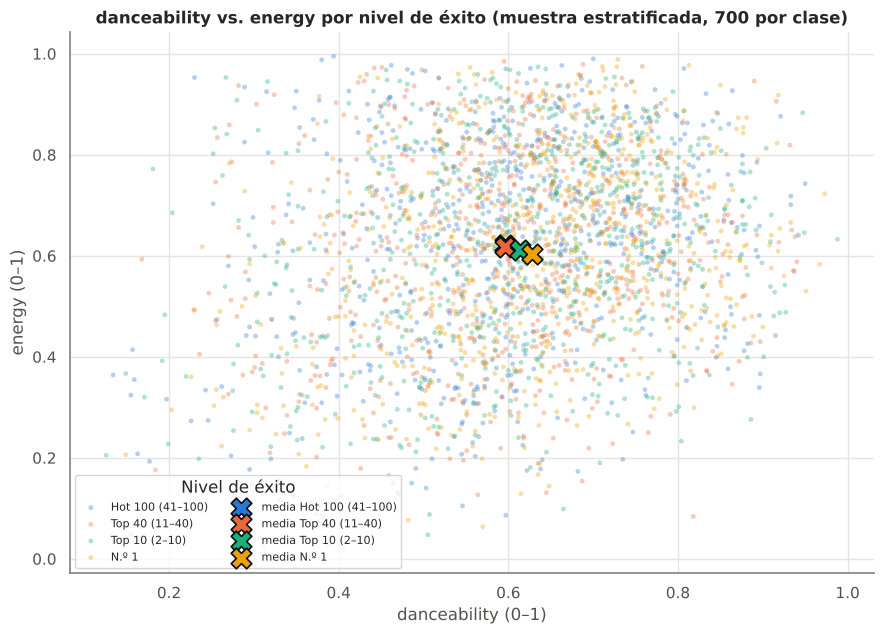

In [ ]:
muestra = pd.concat([g.sample(min(len(g), 700), random_state=SEED)
                     for _, g in eda.groupby("tier_label", observed=True)])
fig, ax = plt.subplots(figsize=(9, 6.5))
for lab, col in zip(TIER_LABELS, CAT_COLORS[:4]):
    sub = muestra[muestra["tier_label"] == lab]
    ax.scatter(sub["danceability"], sub["energy"], s=12, alpha=0.35, color=col, label=lab, edgecolors="none")
for lab, col in zip(TIER_LABELS, CAT_COLORS[:4]):   # centroide (media) de cada clase
    sub = eda[eda["tier_label"] == lab]
    ax.scatter(sub["danceability"].mean(), sub["energy"].mean(), s=220, marker="X", color=col,
               edgecolors="#0b0b0b", linewidths=1.2, label=f"media {lab}")
ax.set_title("danceability vs. energy por nivel de éxito (muestra estratificada, 700 por clase)")
ax.set_xlabel("danceability (0–1)"); ax.set_ylabel("energy (0–1)")
ax.legend(title="Nivel de éxito", fontsize=8, ncol=2, loc="lower left")
plt.tight_layout(); plt.show()

**Patrón:** las cuatro nubes de puntos se **superponen casi totalmente** en el plano bailabilidad–energía. Los centroides (X) de cada clase están muy próximos; el de *N.º 1* está apenas desplazado hacia más bailabilidad y algo menos de energía.

**Utilidad:** muestra visualmente por qué ninguna frontera simple (lineal o no) puede separar las clases con estas dos variables. Cualquier modelo tendrá errores frecuentes entre clases vecinas.

**Limitación:** es una muestra de 700 canciones por clase (para que *N.º 1* sea visible) y solo dos dimensiones de 24. La superposición en 2D no excluye que exista algo de separación en combinaciones de más variables.

## (f) Barras agrupadas: macro-género × nivel de éxito

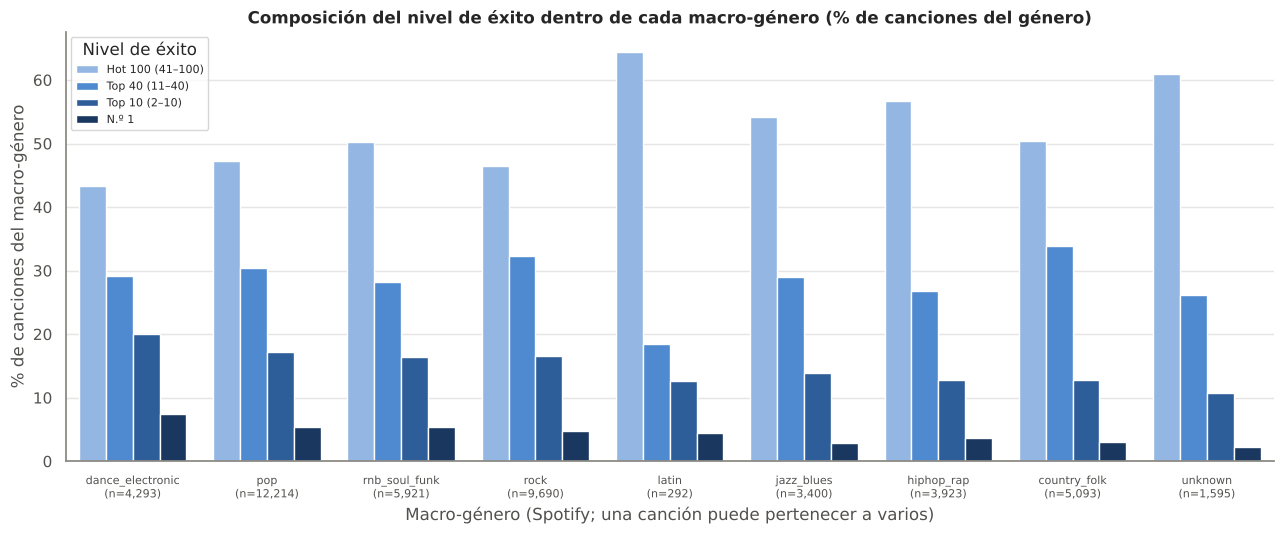

In [ ]:
filas = []
for g in GENRE_COLS:
    sub = eda[eda[g] == 1]
    dist = sub["tier_label"].value_counts(normalize=True).reindex(TIER_LABELS) * 100
    for lab, v in dist.items():
        filas.append({"macro_genero": g.replace("genre_", ""), "nivel": lab, "pct": v, "n": len(sub)})
gb = pd.DataFrame(filas)
orden = (gb[gb.nivel.isin(["Top 10 (2–10)", "N.º 1"])].groupby("macro_genero")["pct"].sum()
         .sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(13, 5.5))
sns.barplot(data=gb, x="macro_genero", y="pct", hue="nivel", order=orden, hue_order=TIER_LABELS,
            palette=TIER_COLORS, ax=ax, width=0.8)
ax.set_title("Composición del nivel de éxito dentro de cada macro-género (% de canciones del género)")
ax.set_xlabel("Macro-género (Spotify; una canción puede pertenecer a varios)")
ax.set_ylabel("% de canciones del macro-género")
ax.legend(title="Nivel de éxito", fontsize=8)
n_gen = gb.drop_duplicates("macro_genero").set_index("macro_genero")["n"]
ax.set_xticks(range(len(orden)))
ax.set_xticklabels([f"{g}\n(n={n_gen[g]:,})" for g in orden], fontsize=8)
plt.tight_layout(); plt.show()

**Patrón:** la composición del éxito varía por macro-género:
- **dance/electronic** tiene la mayor proporción de *Top 10* + *N.º 1* (≈ 27 %) y la menor de *Hot 100 (41–100)* (43 %).
- **latin** (n = 292), **unknown** (sin género en Spotify) y **hip-hop/rap** tienen las mayores proporciones de *Hot 100* (64 %, 61 % y 57 %).
- **pop**, **rock** y **r&b/soul/funk** quedan en una posición intermedia.

**Utilidad:** el género parece aportar más señal que cualquier rasgo de audio aislado (lo confirmará la importancia por permutación en 4.8).

**Limitaciones:**
1. En Spotify los géneros suelen asignarse al **artista**, no a la canción (verificar en la documentación del dataset), así que parte de la señal puede reflejar la **trayectoria del artista**.
2. `unknown` mezcla artistas poco conocidos y canciones sin *matching*.
3. Los macro-géneros se solapan y su construcción por palabras clave es una decisión propia.
4. "latin" tiene pocos casos.

## (g) Gráfica adicional: evolución de las características musicales por década

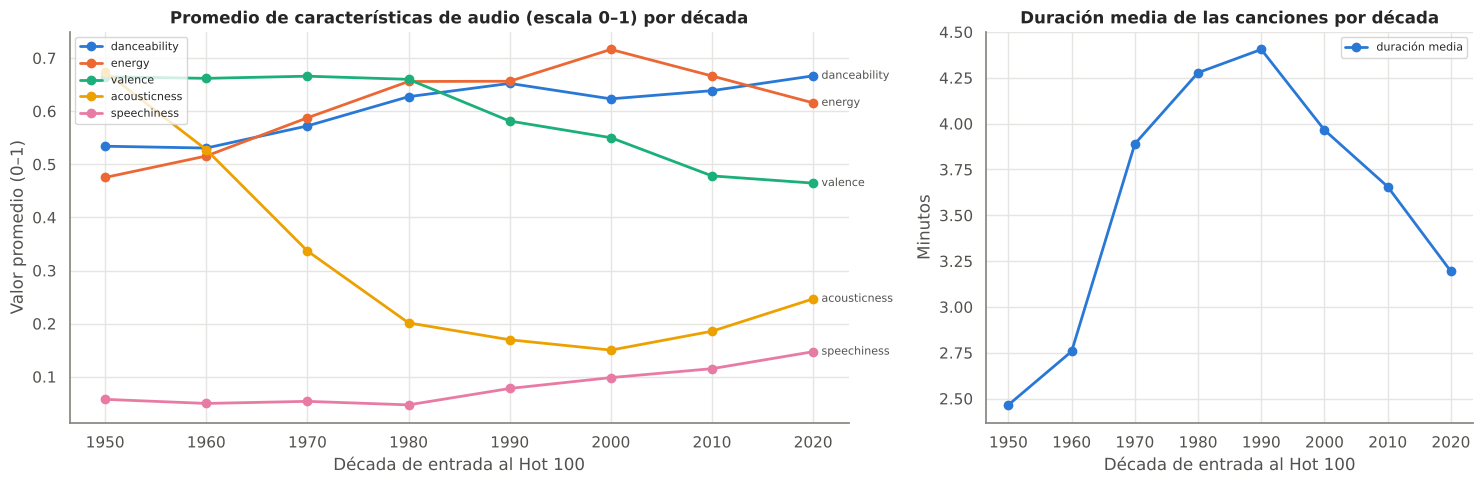

tier_label,Hot 100 (41–100),Top 40 (11–40),Top 10 (2–10),N.º 1
entry_decade,,,,
1950,48.3000,30.7000,17.0000,4.0000
1960,50.8000,30.8000,14.9000,3.5000
1970,50.2000,29.6000,14.9000,5.3000
1980,44.0000,30.4000,19.7000,5.8000
1990,50.3000,29.2000,15.9000,4.5000
2000,51.3000,31.1000,13.7000,3.9000
2010,62.5000,25.6000,9.2000,2.7000
2020,66.7000,25.2000,5.9000,2.2000


In [ ]:
trend_vars = ["danceability", "energy", "valence", "acousticness", "speechiness"]
tend = eda.groupby("entry_decade")[trend_vars + ["duration_minutes"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.6, 1]})
for c, col in zip(trend_vars, CAT_COLORS):
    axes[0].plot(tend.index.astype(int), tend[c], marker="o", ms=6, lw=2, color=col, label=c)
    axes[0].annotate(c, (tend.index[-1], tend[c].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                     fontsize=8, color="#52514e", va="center")
axes[0].set_title("Promedio de características de audio (escala 0–1) por década")
axes[0].set_xlabel("Década de entrada al Hot 100"); axes[0].set_ylabel("Valor promedio (0–1)")
axes[0].legend(fontsize=8, loc="upper left")
axes[1].plot(tend.index.astype(int), tend["duration_minutes"], marker="o", ms=6, lw=2,
             color=CAT_COLORS[0], label="duración media")
axes[1].set_title("Duración media de las canciones por década")
axes[1].set_xlabel("Década de entrada al Hot 100"); axes[1].set_ylabel("Minutos"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Composición del target por década (contexto para el experimento C)
comp_dec = pd.crosstab(eda["entry_decade"], eda["tier_label"], normalize="index").mul(100).round(1)
display(comp_dec)

**Patrón (tendencias musicales):**
- `acousticness` cae de 0,67 (años 50) a ≈ 0,15 (2000), con un leve repunte después.
- `energy` sube de 0,48 a 0,72 (2000) y luego baja a ≈ 0,62.
- `valence` (positividad) baja de ≈ 0,66 (50–80) a ≈ 0,47 (2020): las canciones se volvieron menos "alegres".
- `speechiness` se triplica (0,06 → 0,15), coherente con el auge del rap.
- La **duración** sube de 2,5 min (50) a 4,4 min (90) y vuelve a bajar a 3,2 min (2020), en línea con la era del *streaming*.

La tabla final muestra que la **proporción de *Hot 100 (41–100)* sube** de ≈ 50 % a 62–67 % en 2010–2020: en la era del *streaming* entran más canciones a la lista con recorridos cortos.

**Utilidad:** aporta la dimensión temporal pedida por la especificación y explica por qué el **contexto temporal** podría ayudar a predecir (experimento C).

**Limitaciones:** la década 2020 solo incluye 2020–2021 en el conjunto analítico (el bloque 2021–2026 se excluyó). Son promedios: ocultan la variabilidad dentro de cada década y el cambio en la composición de géneros.

## 3.8 Reto: análisis estadístico

**Prueba 1 – Correlación de Spearman** entre cada variable y el nivel de éxito ordinal.
- *H₀:* ρ = 0 (no hay asociación monótona). *H₁:* ρ ≠ 0. Nivel de significancia α = 0,05.
- Se usa Spearman (no Pearson) porque el target es **ordinal** y varias variables son asimétricas.

**Prueba 2 – Kruskal-Wallis + Mann-Whitney** para `danceability` entre clases, con **tamaño del efecto** (con ~20.000 filas casi cualquier diferencia mínima resulta "significativa", así que el tamaño del efecto es lo que importa).

In [ ]:
filas = []
for c in NUM_FEATURES + ["explicit"]:
    s = eda[[c, "tier_ord"]].dropna()
    r = stats.spearmanr(s[c], s["tier_ord"])
    filas.append({"variable": c, "rho_spearman": r.statistic, "p_valor": r.pvalue})
sp = pd.DataFrame(filas).set_index("variable").sort_values("rho_spearman", key=abs, ascending=False)
sp["significativa (α=0.05)"] = sp["p_valor"] < 0.05
sp["magnitud"] = pd.cut(sp["rho_spearman"].abs(), [0, 0.1, 0.3, 0.5, 1], labels=["despreciable", "débil", "moderada", "fuerte"])
display(sp.style.format({"rho_spearman": "{:.3f}", "p_valor": "{:.2e}"}))

grupos = [g["danceability"].dropna() for _, g in eda.groupby("tier_ord")]
kw = stats.kruskal(*grupos)
eps2 = (kw.statistic - len(grupos) + 1) / (sum(len(g) for g in grupos) - len(grupos))  # épsilon² de Kruskal-Wallis
print(f"Kruskal-Wallis (danceability ~ nivel): H = {kw.statistic:.1f}, p = {kw.pvalue:.2e}, ε² = {eps2:.4f}")

a, b = grupos[3], grupos[0]   # N.º 1 vs Hot 100 (41–100)
mw = stats.mannwhitneyu(a, b, alternative="two-sided")
rbc = 1 - 2 * mw.statistic / (len(a) * len(b))   # correlación biserial de rangos
print(f"Mann-Whitney N.º 1 vs Hot 100: U = {mw.statistic:,.0f}, p = {mw.pvalue:.2e}, "
      f"medianas = {a.median():.3f} vs {b.median():.3f}, r biserial = {rbc:.3f}")

,rho_spearman,p_valor,significativa (α=0.05),magnitud
variable,,,,
explicit,-0.067,1.92e-25,True,despreciable
duration_minutes,0.058,2.56e-19,True,despreciable
speechiness,-0.051,1.84e-15,True,despreciable
valence,0.050,3.48e-15,True,despreciable
danceability,0.045,3.69e-12,True,despreciable
liveness,-0.030,2.97e-06,True,despreciable
loudness,-0.028,1.21e-05,True,despreciable
energy,-0.022,5.13e-04,True,despreciable
tempo,-0.014,2.87e-02,True,despreciable


Kruskal-Wallis (danceability ~ nivel): H = 89.3, p = 3.13e-19, ε² = 0.0035
Mann-Whitney N.º 1 vs Hot 100: U = 7,206,441, p = 1.57e-11, medianas = 0.641 vs 0.602, r biserial = -0.127


**Resultados:**
- **Spearman:** 10 de 12 variables tienen correlación **estadísticamente significativa** con el nivel de éxito (p < 0,05), pero **todas** con magnitud **despreciable** (|ρ| ≤ 0,067). Las mayores: `explicit` (−0,067), `duration_minutes` (+0,058), `speechiness` (−0,051), `valence` (+0,050), `danceability` (+0,045).
- **Kruskal-Wallis (danceability):** H = 89,3, p ≈ 3·10⁻¹⁹ → se rechaza H₀ (las distribuciones no son iguales entre clases). Sin embargo, **ε² = 0,0035**: el nivel de éxito explica apenas un **0,35 %** de la variabilidad en bailabilidad.
- **Mann-Whitney (N.º 1 vs Hot 100):** medianas 0,641 vs 0,602, p ≈ 1,6·10⁻¹¹; correlación biserial de rangos ≈ **−0,13** (efecto **pequeño**; el signo negativo indica que, en este cálculo, los N.º 1 tienden a valores más altos).

**Interpretación:** el hallazgo visual de 3(c) es **real pero pequeño**. Con más de 24.000 observaciones, diferencias mínimas resultan "significativas"; por eso se reporta el **tamaño del efecto**.
**Limitaciones:** pruebas bivariadas, sin control de década o género, y con observaciones no del todo independientes (canciones del mismo artista).

### Correlación ≠ causalidad

Que `danceability` o `explicit` estén asociadas con el nivel de éxito **no** significa que aumentar la bailabilidad *cause* un mejor puesto. Hay al menos tres explicaciones alternativas:
- **Variables de confusión:** la década, el género, el presupuesto de promoción, la fama del artista o la difusión en radio/streaming pueden influir a la vez en el sonido y en el éxito.
- **Sesgo de selección:** solo vemos canciones que **ya entraron** al Hot 100.
- **Cambios en las reglas del ranking:** Billboard ha cambiado la forma de contar ventas, radio y streaming; las asociaciones pueden reflejar reglas de medición y no preferencias del público.

Para afirmar causalidad se necesitaría un diseño experimental (p. ej., pruebas A/B de versiones de una misma canción) o métodos de inferencia causal; este proyecto es **observacional** y **predictivo**.

### Desbalance de clases y su efecto en la evaluación

Las clases están **claramente desbalanceadas** (52 / 29 / 14 / 4 %; razón 12,6 : 1). Efectos sobre la evaluación y medidas tomadas:

| Problema | Medida adoptada |
|---|---|
| La accuracy premia predecir siempre la clase mayoritaria (52,1 % sin aprender nada) | Métrica principal **macro F1**; se reportan también **balanced accuracy**, F1 por clase y matriz de confusión |
| Los modelos tienden a ignorar la clase *N.º 1* | `class_weight="balanced"` en los modelos tradicionales y pesos de clase en la red neuronal |
| La partición podría dejar muy pocos N.º 1 en prueba | Split y validación cruzada **estratificados** (4,15 % de N.º 1 en train y en test) |
| Comparar contra un modelo trivial | `DummyClassifier` como línea base |

No se usa sobremuestreo sintético (SMOTE) para mantener el flujo sencillo y evitar generar canciones artificiales. Sería un posible trabajo futuro.

<a id="b4"></a>
# Bloque 4 · Modelos tradicionales de predicción (20 pts)

## 4.1 División entrenamiento / prueba (80/20, estratificada, agrupada y reproducible)

Se usa `StratifiedGroupKFold` con 5 particiones y se toma **una** como prueba (≈20 %):
- **Estratificada:** conserva la proporción de las 4 clases.
- **Agrupada** por `group_key`: una misma canción/pista nunca queda a la vez en entrenamiento y en prueba (evita que reingresos o errores de *matching* inflen las métricas).
- **Semilla fija** (`SEED = 42`).

El conjunto de prueba **no se toca** hasta la evaluación final (4.6).

In [ ]:
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(X_all, y_all, groups_all))

X_train, X_test = X_all.iloc[train_idx].reset_index(drop=True), X_all.iloc[test_idx].reset_index(drop=True)
y_train, y_test = y_all.iloc[train_idx].reset_index(drop=True), y_all.iloc[test_idx].reset_index(drop=True)
g_train, g_test = groups_all.iloc[train_idx].reset_index(drop=True), groups_all.iloc[test_idx].reset_index(drop=True)

print(f"Entrenamiento: {len(X_train):,} ({len(X_train)/len(X_all):.1%}) | Prueba: {len(X_test):,} ({len(X_test)/len(X_all):.1%})")
print("Grupos compartidos entre train y test:", len(set(g_train) & set(g_test)))
prop = pd.DataFrame({"total": y_all.value_counts(normalize=True), "train": y_train.value_counts(normalize=True),
                     "test": y_test.value_counts(normalize=True)}).sort_index()
prop.index = TIER_LABELS
display((prop * 100).round(2))

# Folds de validación cruzada FIJOS (k=5), agrupados y estratificados, reutilizados por TODOS los modelos
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
CV_FOLDS = list(inner.split(X_train, y_train, g_train))
print("Tamaño de los folds de validación:", [len(v) for _, v in CV_FOLDS])

Entrenamiento: 19,453 (80.0%) | Prueba: 4,864 (20.0%)
Grupos compartidos entre train y test: 0


,total,train,test
Hot 100 (41–100),52.1100,52.1100,52.1000
Top 40 (11–40),29.3500,29.3500,29.3400
Top 10 (2–10),14.4000,14.3900,14.4100
N.º 1,4.1500,4.1500,4.1500


Tamaño de los folds de validación: [3891, 3891, 3891, 3890, 3890]


## 4.2 Modelos y métricas

| Modelo | Justificación |
|---|---|
| `DummyClassifier` (clase más frecuente) | **Baseline**: rendimiento mínimo de referencia. Un modelo útil debe superarlo claramente. |
| `LogisticRegression` | Modelo lineal **interpretable** (coeficientes por clase). Exigido por la tabla 3.1. |
| `DecisionTreeClassifier` | Reglas legibles; captura no linealidades simples. Exigido por la tabla 3.1 (árbol / RF). |
| `RandomForestClassifier` | Ensamble de árboles; capta interacciones no lineales y es robusto a atípicos. |

Todos los modelos con pesos usan `class_weight='balanced'` para compensar el desbalance.
**Métrica principal: Macro F1** (promedia el F1 de las 4 clases por igual, así que las clases minoritarias pesan lo mismo). También se reportan accuracy, precision/recall macro, F1 ponderado, balanced accuracy, ROC-AUC multiclase (One-vs-Rest) y una métrica ordinal propia: **% de errores graves** (predicción a ≥ 2 niveles de distancia, p. ej. confundir un N.º 1 con una simple entrada).

In [ ]:
SCORING = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy",
           "f1_macro": "f1_macro", "f1_weighted": "f1_weighted",
           "precision_macro": "precision_macro", "recall_macro": "recall_macro"}

def make_pipeline(model, extra_cats=()):
    return Pipeline([("prep", make_preprocessor(extra_cats)), ("model", model)])

def evaluate(name, y_true, y_pred, y_proba=None):
    # Métricas de clasificación multiclase sobre un conjunto
    res = {
        "modelo": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "roc_auc_ovr_macro": roc_auc_score(y_true, y_proba, multi_class="ovr", average="macro") if y_proba is not None else np.nan,
        "%_errores_graves": np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)) >= 2) * 100,
    }
    for k, lab in enumerate(TIER_LABELS):
        res[f"F1 {lab}"] = f1_score(y_true, y_pred, labels=[k], average="macro", zero_division=0)
    return res

def cv_summary(name, pipe, X, y, folds=None):
    # Validación cruzada k=5 con los folds fijos → media y desviación estándar
    folds = folds or CV_FOLDS
    t0 = time.time()
    r = cross_validate(pipe, X, y, cv=folds, scoring=SCORING, n_jobs=1)
    out = {"modelo": name}
    for m in SCORING:
        out[f"{m}_mean"] = r[f"test_{m}"].mean(); out[f"{m}_std"] = r[f"test_{m}"].std()
    out["seg"] = time.time() - t0
    return out

def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, data, fmt, sub in [(axes[0], cm, "d", "conteos"), (axes[1], cmn, ".2f", "proporción por fila = recall")]:
        sns.heatmap(data, annot=True, fmt=fmt, cmap=sns.light_palette("#1c5cab", as_cmap=True), ax=ax,
                    xticklabels=TIER_LABELS, yticklabels=TIER_LABELS, cbar_kws={"label": sub})
        ax.set_title(sub.capitalize()); ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
        ax.tick_params(axis="x", rotation=20, labelsize=8); ax.tick_params(axis="y", rotation=0, labelsize=8)
    fig.suptitle(title, fontweight="bold"); plt.tight_layout(); plt.show()
    return cm

## 4.3 Validación cruzada (k = 5) de los modelos base

In [ ]:
base_models = {
    "Dummy (clase mayoritaria)": DummyClassifier(strategy="most_frequent"),
    "Regresión logística": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=SEED),
}
cv_rows = [cv_summary(n, make_pipeline(m), X_train[FEATURES_MAIN], y_train) for n, m in base_models.items()]
cv_table = pd.DataFrame(cv_rows).set_index("modelo")
display(cv_table[["f1_macro_mean", "f1_macro_std", "balanced_accuracy_mean", "balanced_accuracy_std",
                  "accuracy_mean", "f1_weighted_mean", "seg"]].round(4))

,f1_macro_mean,f1_macro_std,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,f1_weighted_mean,seg
modelo,,,,,,,
Dummy (clase mayoritaria),0.1713,0.0000,0.2500,0.0000,0.5211,0.3570,0.2742
Regresión logística,0.2739,0.0046,0.3347,0.0099,0.3500,0.3814,1.1204
Árbol de decisión,0.2506,0.0081,0.3011,0.0062,0.3105,0.3481,1.0689
Random Forest,0.2965,0.0067,0.2966,0.0056,0.4777,0.4482,21.7212


**Interpretación (validación cruzada, 5 folds agrupados):**
- **Dummy:** macro F1 = 0,171 y balanced accuracy = 0,25, pero **accuracy = 0,521**. Ilustra por qué la accuracy engaña.
- **Random Forest:** mejor macro F1 (**0,297 ± 0,007**) y la mejor accuracy entre los modelos útiles (0,478).
- **Regresión logística:** macro F1 = 0,274, pero **mayor balanced accuracy (0,335)**: reparte mejor sus aciertos entre clases, aunque se equivoca más en la clase mayoritaria.
- **Árbol de decisión:** el más débil (0,251).

Las desviaciones estándar son pequeñas (≤ 0,01), así que las diferencias entre modelos son estables entre folds. Todos superan claramente al baseline, aunque con valores **absolutos modestos**: es la consecuencia esperada de la señal débil observada en el EDA.

## 4.4 Optimización de hiperparámetros

- **Regresión logística → `GridSearchCV`** sobre la fuerza de regularización `C`.
- **Random Forest → `RandomizedSearchCV`** (más eficiente que una rejilla completa en un espacio grande).

Ambas búsquedas usan **solo el conjunto de entrenamiento**, los mismos 5 folds agrupados y la métrica `f1_macro`.

In [ ]:
t0 = time.time()
grid_lr = GridSearchCV(make_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED)),
                       param_grid={"model__C": [0.01, 0.1, 1, 10]},
                       cv=CV_FOLDS, scoring="f1_macro", n_jobs=1)
grid_lr.fit(X_train[FEATURES_MAIN], y_train)
print(f"GridSearchCV LR → mejor C = {grid_lr.best_params_['model__C']} | macro F1 CV = {grid_lr.best_score_:.4f} "
      f"({time.time()-t0:.0f} s)")
display(pd.DataFrame(grid_lr.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]].round(4))

GridSearchCV LR → mejor C = 1 | macro F1 CV = 0.2739 (4 s)


,param_model__C,mean_test_score,std_test_score
0,0.0100,0.2735,0.0058
1,0.1000,0.2732,0.0045
2,1.0000,0.2739,0.0046
3,10.0000,0.2739,0.0045


In [ ]:
t0 = time.time()
param_dist = {
    "model__n_estimators": [200, 300, 400],
    "model__max_depth": [8, 12, 16, 20, None],
    "model__min_samples_leaf": [1, 3, 5, 10, 20],
    "model__max_features": ["sqrt", 0.3, 0.5],
}
rand_rf = RandomizedSearchCV(
    make_pipeline(RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
    param_distributions=param_dist, n_iter=N_ITER_SEARCH, cv=CV_FOLDS, scoring="f1_macro",
    random_state=SEED, n_jobs=1, return_train_score=True)
rand_rf.fit(X_train[FEATURES_MAIN], y_train)
print(f"RandomizedSearchCV RF ({N_ITER_SEARCH} combinaciones × 5 folds) → {time.time()-t0:.0f} s")
print("Mejores hiperparámetros:", rand_rf.best_params_)
res_rs = pd.DataFrame(rand_rf.cv_results_)
display(res_rs[["params", "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]]
        .sort_values("rank_test_score").head(6).round(4))

RandomizedSearchCV RF (12 combinaciones × 5 folds) → 427 s
Mejores hiperparámetros: {'model__n_estimators': 400, 'model__min_samples_leaf': 10, 'model__max_features': 0.5, 'model__max_depth': 12}


,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
7,"{'model__n_estimators': 400, 'model__min_sampl...",0.7370,0.3166,0.0057,1
3,"{'model__n_estimators': 200, 'model__min_sampl...",0.6635,0.3146,0.0083,2
10,"{'model__n_estimators': 400, 'model__min_sampl...",0.8331,0.3143,0.0069,3
8,"{'model__n_estimators': 300, 'model__min_sampl...",0.6734,0.3134,0.0030,4
4,"{'model__n_estimators': 300, 'model__min_sampl...",0.6475,0.3133,0.0111,5
9,"{'model__n_estimators': 300, 'model__min_sampl...",0.8657,0.3129,0.0065,6


In [ ]:
best_lr = grid_lr.best_estimator_
best_rf = rand_rf.best_estimator_
cv_rows.append(cv_summary("Regresión logística (GridSearch)", clone(best_lr), X_train[FEATURES_MAIN], y_train))
cv_rows.append(cv_summary("Random Forest (RandomizedSearch)", clone(best_rf), X_train[FEATURES_MAIN], y_train))
cv_table = pd.DataFrame(cv_rows).set_index("modelo")
display(cv_table[["f1_macro_mean", "f1_macro_std", "balanced_accuracy_mean", "balanced_accuracy_std",
                  "accuracy_mean", "f1_weighted_mean"]].round(4))

,f1_macro_mean,f1_macro_std,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,f1_weighted_mean
modelo,,,,,,
Dummy (clase mayoritaria),0.1713,0.0000,0.2500,0.0000,0.5211,0.3570
Regresión logística,0.2739,0.0046,0.3347,0.0099,0.3500,0.3814
Árbol de decisión,0.2506,0.0081,0.3011,0.0062,0.3105,0.3481
Random Forest,0.2965,0.0067,0.2966,0.0056,0.4777,0.4482
Regresión logística (GridSearch),0.2739,0.0046,0.3347,0.0099,0.3500,0.3814
Random Forest (RandomizedSearch),0.3166,0.0057,0.3219,0.0070,0.4371,0.4418


**Resultados de la optimización:**
- **Regresión logística:** el valor de `C` casi no cambia el resultado (0,2732–0,2739). El modelo está limitado por la **información disponible**, no por la regularización. Se queda `C = 1`.
- **Random Forest:** la búsqueda aleatoria eligió `n_estimators=400, max_depth=12, min_samples_leaf=10, max_features=0.5`. La macro F1 en CV sube de **0,297 a 0,317** (+0,020). Los árboles menos profundos y con hojas más grandes generalizan mejor que el bosque por defecto (profundidad ilimitada).

## 4.5 Diagnóstico de generalización (train vs. validación)

In [ ]:
gen = res_rs.sort_values("rank_test_score").head(1)[["mean_train_score", "mean_test_score"]]
gen.index = ["RF optimizado"]
r_lr = cross_validate(clone(best_lr), X_train[FEATURES_MAIN], y_train, cv=CV_FOLDS, scoring="f1_macro", return_train_score=True)
gen.loc["LR optimizada"] = [r_lr["train_score"].mean(), r_lr["test_score"].mean()]
gen["brecha"] = gen["mean_train_score"] - gen["mean_test_score"]
gen.columns = ["macro F1 train (CV)", "macro F1 validación (CV)", "brecha"]
display(gen.round(4))

,macro F1 train (CV),macro F1 validación (CV),brecha
RF optimizado,0.7370,0.3166,0.4204
LR optimizada,0.2845,0.2739,0.0105


**Diagnóstico:**
- **Random Forest optimizado:** macro F1 de **0,737 en entrenamiento vs 0,317 en validación** (brecha ≈ 0,42). El bosque memoriza buena parte del entrenamiento. Es una señal de **sobreajuste**, típica de los Random Forest; lo que importa para decidir es el desempeño en validación, que es el mejor de todos los modelos.
- **Regresión logística:** 0,285 vs 0,274 (brecha ≈ 0,01). **No sobreajusta, pero subajusta**: un modelo lineal no puede capturar más patrón del que hay.

En ambos casos el techo lo pone la **baja información de las variables de audio**, no la falta de datos ni de capacidad.

## 4.6 Evaluación final en el conjunto de prueba

Todos los modelos se reentrenan con el **entrenamiento completo** y se evalúan **una sola vez** en prueba.

In [ ]:
final_models = {
    "Dummy (clase mayoritaria)": make_pipeline(base_models["Dummy (clase mayoritaria)"]),
    "Regresión logística": make_pipeline(base_models["Regresión logística"]),
    "Árbol de decisión": make_pipeline(base_models["Árbol de decisión"]),
    "Random Forest": make_pipeline(base_models["Random Forest"]),
    "Regresión logística (GridSearch)": clone(best_lr),
    "Random Forest (RandomizedSearch)": clone(best_rf),
}
test_rows, fitted, probas, preds = [], {}, {}, {}
for name, pipe in final_models.items():
    pipe.fit(X_train[FEATURES_MAIN], y_train)
    fitted[name] = pipe
    preds[name] = pipe.predict(X_test[FEATURES_MAIN])
    probas[name] = pipe.predict_proba(X_test[FEATURES_MAIN])
    test_rows.append(evaluate(name, y_test, preds[name], probas[name]))

test_table = pd.DataFrame(test_rows).set_index("modelo")
test_table.insert(0, "macro F1 CV (media ± std)",
                  [f"{cv_table.loc[n, 'f1_macro_mean']:.3f} ± {cv_table.loc[n, 'f1_macro_std']:.3f}" for n in test_table.index])
display(test_table.style.format(precision=3).background_gradient(
    cmap=sns.light_palette("#3987e5", as_cmap=True), subset=["f1_macro", "balanced_accuracy", "roc_auc_ovr_macro"]))

,macro F1 CV (media ± std),accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,roc_auc_ovr_macro,%_errores_graves,F1 Hot 100 (41–100),F1 Top 40 (11–40),F1 Top 10 (2–10),F1 N.º 1
modelo,,,,,,,,,,,,,
Dummy (clase mayoritaria),0.171 ± 0.000,0.521,0.130,0.250,0.171,0.357,0.250,0.500,18.565,0.685,0.000,0.000,0.000
Regresión logística,0.274 ± 0.005,0.345,0.292,0.336,0.270,0.373,0.336,0.586,32.401,0.522,0.235,0.183,0.137
Árbol de decisión,0.251 ± 0.008,0.297,0.293,0.302,0.250,0.343,0.302,0.552,37.459,0.442,0.279,0.184,0.095
Random Forest,0.297 ± 0.007,0.476,0.329,0.299,0.300,0.450,0.299,0.599,14.926,0.637,0.303,0.183,0.078
Regresión logística (GridSearch),0.274 ± 0.005,0.345,0.292,0.336,0.270,0.373,0.336,0.586,32.401,0.522,0.235,0.183,0.137
Random Forest (RandomizedSearch),0.317 ± 0.006,0.426,0.312,0.317,0.311,0.434,0.317,0.598,19.572,0.586,0.311,0.227,0.122


**Evaluación final en prueba (4.864 canciones, nunca usadas antes).** Los resultados de prueba son coherentes con la validación cruzada (diferencias ≤ 0,006 en macro F1), así que **no hay señales de que la CV haya sido optimista**.

| Modelo | Macro F1 | Balanced acc. | Accuracy | AUC OvR | F1 N.º 1 | % errores graves |
|---|---|---|---|---|---|---|
| Dummy | 0,171 | 0,250 | 0,521 | 0,500 | 0,000 | 18,6 |
| Regresión logística | 0,270 | **0,336** | 0,345 | 0,586 | **0,137** | 32,4 |
| Árbol de decisión | 0,250 | 0,302 | 0,297 | 0,552 | 0,095 | 37,5 |
| Random Forest (defecto) | 0,300 | 0,299 | **0,476** | **0,599** | 0,078 | **14,9** |
| **Random Forest optimizado** | **0,311** | 0,317 | 0,426 | 0,598 | 0,122 | 19,6 |

**Lectura:** el RF optimizado tiene la mejor macro F1; la regresión logística, la mejor balanced accuracy y el mejor F1 en *N.º 1*. El Dummy tiene pocos "errores graves" solo porque nunca predice clases altas (y nunca acierta ninguna). Un AUC de ≈ 0,60 indica una capacidad de ordenamiento **apenas superior al azar (0,50)**.

Modelo tradicional con mejor macro F1 en CV: Random Forest (RandomizedSearch)
                  precision    recall  f1-score   support

Hot 100 (41–100)      0.608     0.566     0.586      2534
  Top 40 (11–40)      0.337     0.289     0.311      1427
   Top 10 (2–10)      0.189     0.284     0.227       701
           N.º 1      0.116     0.129     0.122       202

        accuracy                          0.426      4864
       macro avg      0.312     0.317     0.311      4864
    weighted avg      0.447     0.426     0.434      4864



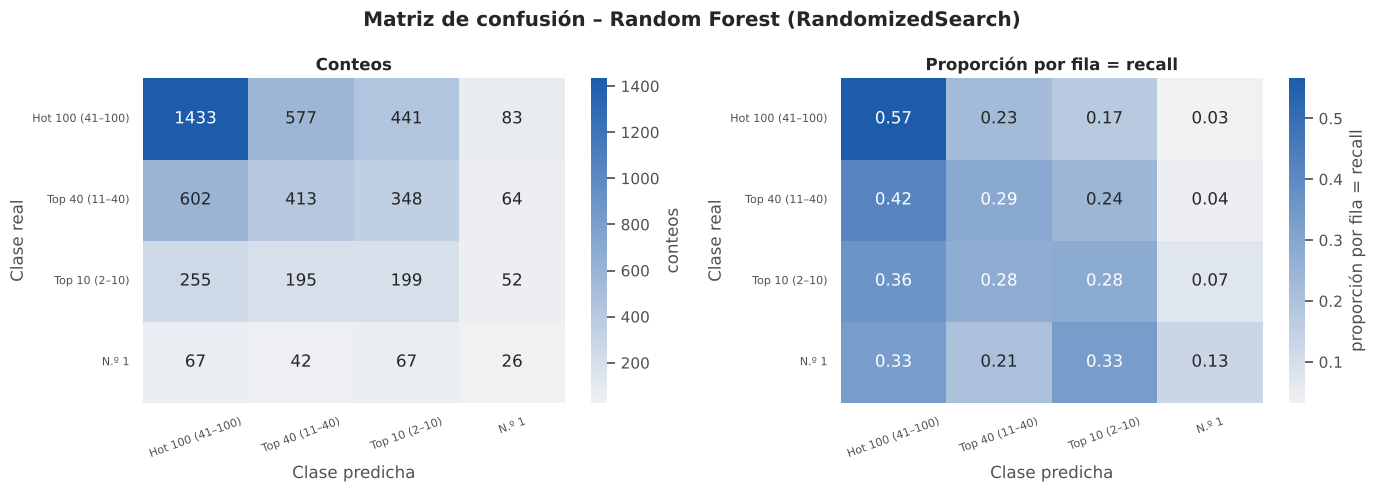

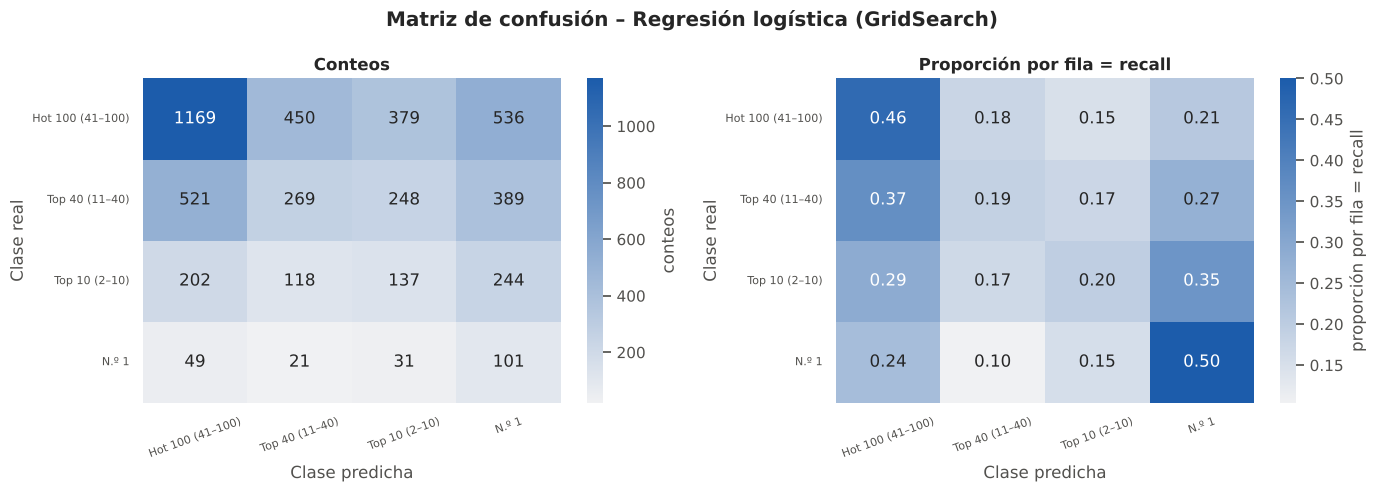

In [ ]:
# Selección del modelo tradicional por CV (no por test): mayor macro F1 medio en validación cruzada
BEST_TRAD = cv_table.drop(index="Dummy (clase mayoritaria)")["f1_macro_mean"].idxmax()
print("Modelo tradicional con mejor macro F1 en CV:", BEST_TRAD)
print(classification_report(y_test, preds[BEST_TRAD], target_names=TIER_LABELS, digits=3))
cm_best = plot_confusion(y_test, preds[BEST_TRAD], f"Matriz de confusión – {BEST_TRAD}")
_ = plot_confusion(y_test, preds["Regresión logística (GridSearch)"], "Matriz de confusión – Regresión logística (GridSearch)")

**Errores del Random Forest optimizado (prueba):**
- **Hot 100 (41–100):** acierta 57 % (1.433 de 2.534); 23 % se confunde con *Top 40* y 17 % con *Top 10*.
- **Top 40 (11–40):** solo 29 % de acierto; el 42 % se predice como *Hot 100*.
- **Top 10 (2–10):** 28 % de acierto; se reparte entre todas las clases.
- **N.º 1:** solo **26 de 202 (13 %)** detectados; **33 % se predice como *Hot 100*** (error grave) y 33 % como *Top 10* (error "cercano").

**Patrón:** los errores **no** se concentran entre clases vecinas: el modelo confunde con frecuencia extremos de la escala. Esto confirma que el audio no ordena bien el nivel de éxito.

La regresión logística con pesos balanceados (segunda matriz) **reparte más predicciones hacia clases altas**: detecta más *N.º 1* y *Top 10*, a cambio de muchos más falsos positivos y errores graves (32 %).

**Costo en la vida real:**
- Un **falso negativo de N.º 1** (subestimar un futuro éxito) implica dejar de invertir en promoción de una canción valiosa: **costo de oportunidad alto**.
- Un **falso positivo** (sobrestimar una canción) implica invertir presupuesto de marketing en una canción que no rendirá: **costo directo**.

Con los niveles de acierto actuales, ninguno de los dos errores es aceptable para decisiones automáticas.

## 4.7 Curvas ROC multiclase (One-vs-Rest)

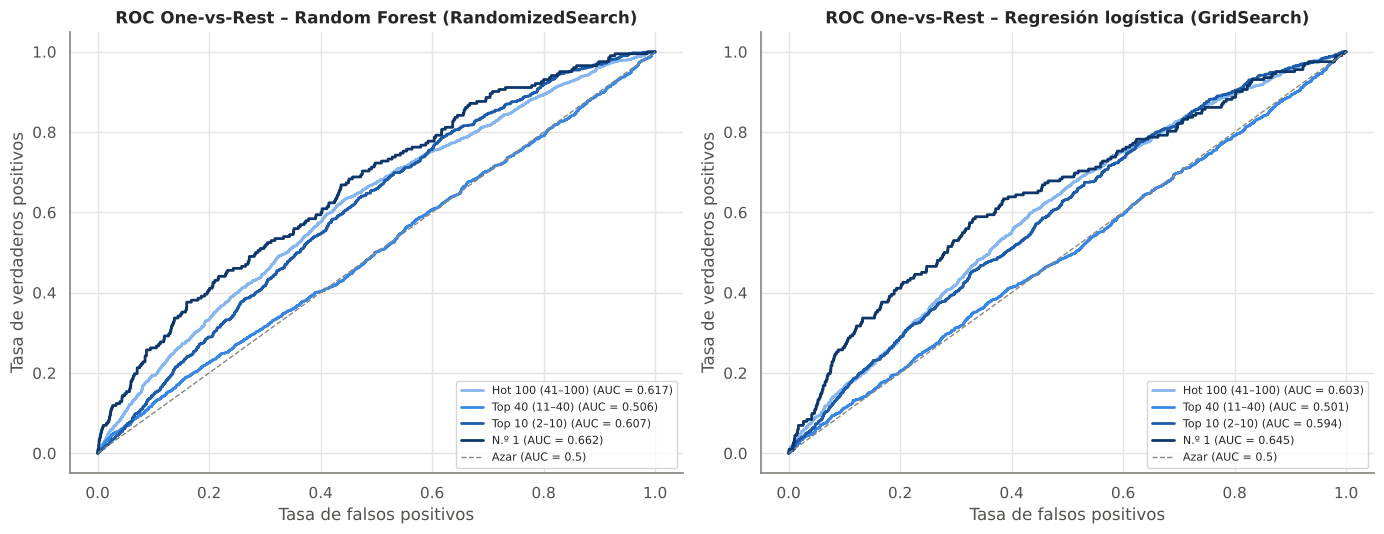

In [ ]:
y_test_bin = label_binarize(y_test, classes=range(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, name in zip(axes, [BEST_TRAD, "Regresión logística (GridSearch)"]):
    for k, (lab, col) in enumerate(zip(TIER_LABELS, TIER_COLORS)):
        fpr, tpr, _ = roc_curve(y_test_bin[:, k], probas[name][:, k])
        auc_k = roc_auc_score(y_test_bin[:, k], probas[name][:, k])
        ax.plot(fpr, tpr, lw=2, color=col, label=f"{lab} (AUC = {auc_k:.3f})")
    ax.plot([0, 1], [0, 1], ls="--", color="#898781", lw=1, label="Azar (AUC = 0.5)")
    ax.set_title(f"ROC One-vs-Rest – {name}"); ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**Patrón:** las curvas quedan **cerca de la diagonal del azar**. En el RF optimizado, la clase **N.º 1** es la mejor ordenada (AUC = 0,662), seguida de *Hot 100* (0,617) y *Top 10* (0,607). La clase intermedia *Top 40* es prácticamente indistinguible del azar (AUC = 0,506). La regresión logística muestra el mismo patrón con valores algo menores (0,645 / 0,603 / 0,594 / 0,501).

**Utilidad:** el AUC no depende de un umbral y confirma que el modelo tiene **algo** de capacidad para ordenar los extremos (N.º 1 vs resto), pero no para las clases intermedias.

**Limitación:** el AUC One-vs-Rest con clases desbalanceadas puede verse optimista; para la clase minoritaria es más informativa la curva **precisión-recall** (reto final).

## 4.8 Importancia de variables y contraste con el EDA

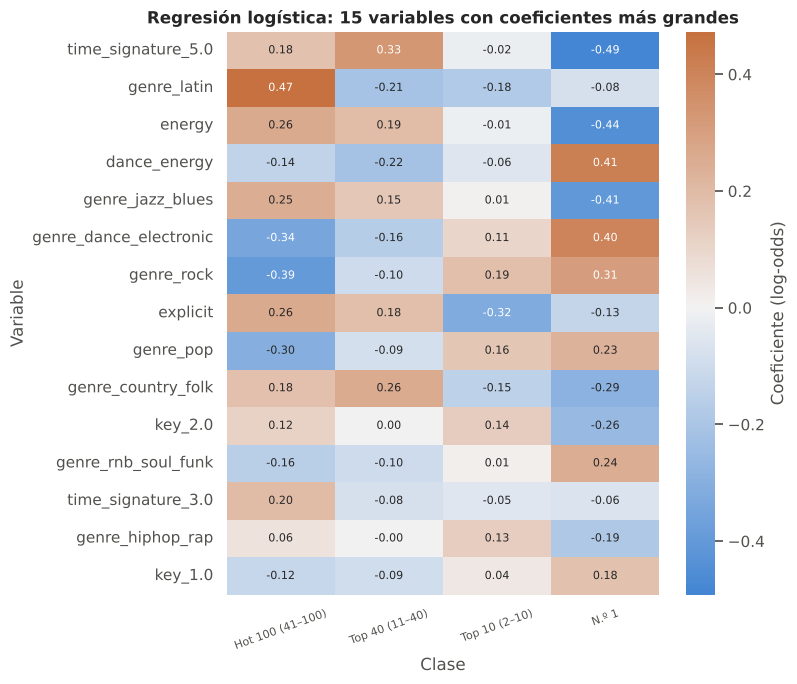

In [ ]:
feat_names = fitted["Regresión logística (GridSearch)"].named_steps["prep"].get_feature_names_out()

# (1) Coeficientes de la regresión logística (variables estandarizadas → comparables)
coefs = pd.DataFrame(fitted["Regresión logística (GridSearch)"].named_steps["model"].coef_.T,
                     index=feat_names, columns=TIER_LABELS)
top_coef = coefs.loc[coefs.abs().max(axis=1).sort_values(ascending=False).index[:15]]
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(top_coef, cmap=cmap_div, center=0, annot=True, fmt=".2f", annot_kws={"size": 8},
            cbar_kws={"label": "Coeficiente (log-odds)"}, ax=ax)
ax.set_title("Regresión logística: 15 variables con coeficientes más grandes")
ax.set_xlabel("Clase"); ax.set_ylabel("Variable"); ax.tick_params(axis="x", rotation=20, labelsize=8)
plt.tight_layout(); plt.show()

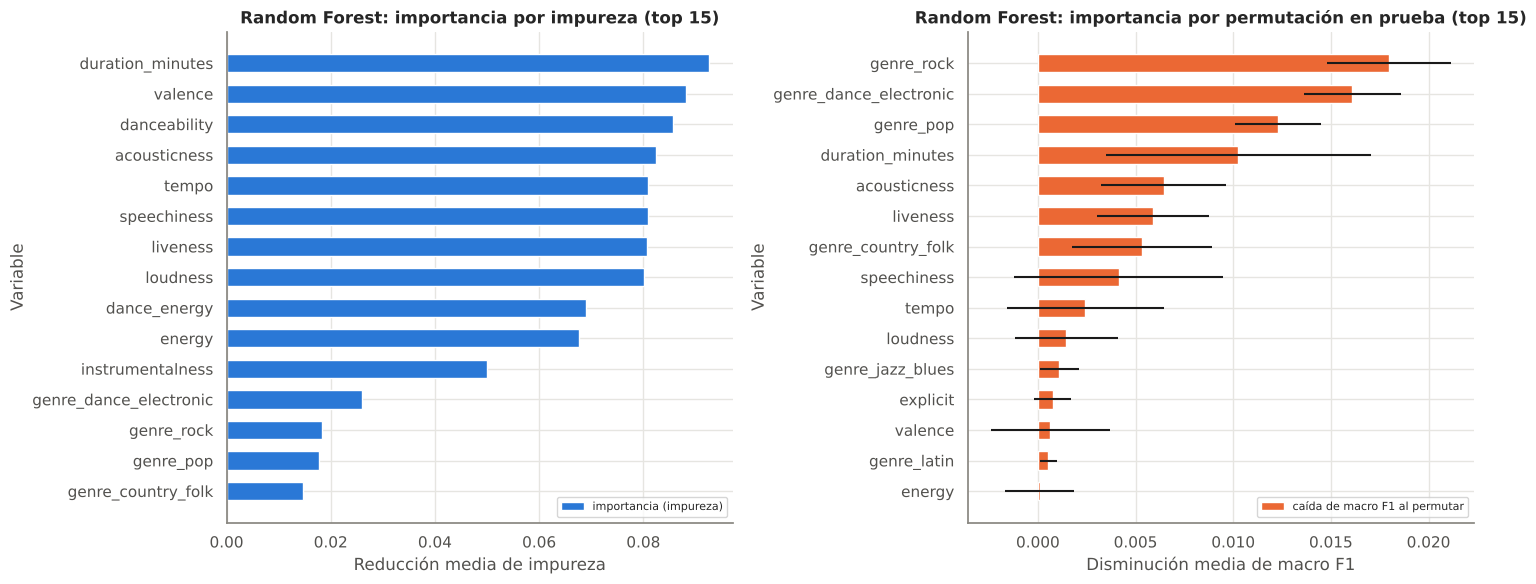

,rank_permutacion,importancia_perm,rho_spearman_EDA
genre_rock,1,0.0180,NaN
genre_dance_electronic,2,0.0161,NaN
genre_pop,3,0.0123,NaN
duration_minutes,4,0.0103,0.0576
acousticness,5,0.0064,0.0136
liveness,6,0.0059,-0.0300
genre_country_folk,7,0.0053,NaN
speechiness,8,0.0041,-0.0510
tempo,9,0.0024,-0.0140
loudness,10,0.0014,-0.0281


In [ ]:
# (2) Importancia por impureza del Random Forest optimizado y (3) importancia por permutación (test)
rf_pipe = fitted["Random Forest (RandomizedSearch)"]
imp_rf = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=feat_names).sort_values(ascending=False)

perm = permutation_importance(rf_pipe, X_test[FEATURES_MAIN], y_test, scoring="f1_macro",
                              n_repeats=5, random_state=SEED, n_jobs=1)
imp_perm = pd.Series(perm.importances_mean, index=FEATURES_MAIN).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top = imp_rf.head(15)[::-1]
axes[0].barh(top.index, top.values, color=CAT_COLORS[0], height=0.6, label="importancia (impureza)")
axes[0].set_title("Random Forest: importancia por impureza (top 15)")
axes[0].set_xlabel("Reducción media de impureza"); axes[0].set_ylabel("Variable"); axes[0].legend(fontsize=8)
topp = imp_perm.head(15)[::-1]
axes[1].barh(topp.index, topp.values, xerr=pd.Series(perm.importances_std, index=FEATURES_MAIN)[topp.index],
             color=CAT_COLORS[1], height=0.6, label="caída de macro F1 al permutar")
axes[1].set_title("Random Forest: importancia por permutación en prueba (top 15)")
axes[1].set_xlabel("Disminución media de macro F1"); axes[1].set_ylabel("Variable"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

comp_imp = pd.DataFrame({"rank_permutacion": imp_perm.rank(ascending=False).astype(int),
                         "importancia_perm": imp_perm,
                         "rho_spearman_EDA": sp["rho_spearman"].reindex(imp_perm.index)}).head(10)
display(comp_imp.round(4))

**Comparación de las tres medidas de importancia:**
- **Importancia por impureza (RF):** destaca `duration_minutes`, `valence`, `danceability`, `acousticness`, `tempo`… Esta medida está **sesgada a favor de variables continuas** con muchos valores posibles, por eso las binarias de género aparecen abajo.
- **Importancia por permutación (RF, en prueba; más confiable):** las variables cuya permutación más reduce la macro F1 son **`genre_rock`, `genre_dance_electronic`, `genre_pop`** y `duration_minutes`, seguidas de `acousticness`, `liveness` y `genre_country_folk`. `valence` y `energy` aportan ≈ 0 una vez que el resto está presente.
- **Regresión logística:** los coeficientes más grandes son de **género** (latin → *Hot 100*; dance/electronic, rock y r&b → *N.º 1*), `time_signature`, `energy` (negativo para *N.º 1*), `dance_energy` (positivo para *N.º 1*) y `explicit`.

**Contraste con el EDA:** es coherente. El gráfico (f) ya mostraba diferencias por género mayores que cualquier diferencia por rasgo de audio, y la duración era de las pocas variables numéricas con correlación algo mayor (ρ = 0,058). Las magnitudes son todas **pequeñas** (la variable más importante reduce la macro F1 solo en ≈ 0,018).

**Advertencia:** importancia ≠ causalidad. Que el género "rock" sea importante no significa que producir rock cause más éxito. Además, el género es metadato del artista y puede actuar como sustituto de su trayectoria.

## 4.8.1 Reto: selección del modelo tradicional (sin basarse en una sola métrica)

**Modelo tradicional seleccionado: Random Forest optimizado (RandomizedSearchCV).** La decisión no se basa en una sola métrica:

| Criterio | Random Forest optimizado | Regresión logística | Comentario |
|---|---|---|---|
| **Rendimiento** (macro F1 CV / prueba) | **0,317 / 0,311** | 0,274 / 0,270 | El RF es mejor en la métrica principal, de forma estable entre folds |
| Balanced accuracy | 0,317 | **0,336** | La LR reparte mejor el recall entre clases |
| Detección de N.º 1 (F1) | 0,122 | **0,137** | Ambos muy bajos |
| **Costo de errores** (% errores graves) | **19,6 %** | 32,4 % | El RF confunde mucho menos "N.º 1 ↔ entrada simple", el error más costoso |
| **Interpretabilidad** | Media (permutación) | **Alta** (coeficientes) | La LR es más fácil de explicar a negocio |
| Complejidad / cómputo | Media (400 árboles) | **Baja** | — |
| **Generalización** | Brecha train–val alta | Brecha mínima | El RF sobreajusta, pero su validación sigue siendo la mejor |

**Conclusión:** se elige el **RF optimizado** porque maximiza la métrica principal y **minimiza los errores graves** (los más costosos para la discográfica). La **regresión logística** se recomienda como modelo **explicativo complementario**. En cualquier caso, el rendimiento absoluto es bajo: ninguno de los dos sirve para decisiones automáticas.

<a id="b4ia"></a>
## 4.9 Experimento complementario: ¿aporta valor el enriquecimiento con IA?

**Diseño controlado:** mismo split, mismos 5 folds, mismo target, mismo algoritmo y mismos hiperparámetros (los del Random Forest optimizado); solo cambia el conjunto de predictores.

| Modelo | Predictores |
|---|---|
| **A** | Características musicales originales (conjunto principal) |
| **B** | A + `acoustic_mood_cluster` (enriquecimiento IA **auditado** en 2.10: se reconstruye al 100 % con energy y valence) |
| **C** *(exploratorio)* | A + `musical_era` (enriquecimiento IA derivado de la **fecha**; no es musical) |

También se repite A vs B con la regresión logística para comprobar que la conclusión no depende del algoritmo. La incertidumbre de la diferencia en prueba se estima con **bootstrap pareado** (1.000 remuestreos).

In [ ]:
rf_params = {k.replace("model__", ""): v for k, v in rand_rf.best_params_.items()}
def rf_tuned():
    return RandomForestClassifier(**rf_params, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
def lr_tuned():
    return LogisticRegression(C=grid_lr.best_params_["model__C"], max_iter=3000, class_weight="balanced", random_state=SEED)

experimentos = {
    "A · RF audio original": (FEATURES_MAIN, (), rf_tuned),
    "B · RF audio + acoustic_mood_cluster": (FEATURES_B, ("acoustic_mood_cluster",), rf_tuned),
    "C · RF audio + musical_era (exploratorio)": (FEATURES_C, ("musical_era",), rf_tuned),
    "A · LR audio original": (FEATURES_MAIN, (), lr_tuned),
    "B · LR audio + acoustic_mood_cluster": (FEATURES_B, ("acoustic_mood_cluster",), lr_tuned),
}
ia_cv, ia_test, ia_pred = [], [], {}
for name, (feats, extra, mk) in experimentos.items():
    pipe = make_pipeline(mk(), extra_cats=extra)
    r = cross_validate(pipe, X_train[feats], y_train, cv=CV_FOLDS, scoring=["f1_macro", "balanced_accuracy"])
    pipe.fit(X_train[feats], y_train)
    ia_pred[name] = pipe.predict(X_test[feats])
    ev = evaluate(name, y_test, ia_pred[name], pipe.predict_proba(X_test[feats]))
    ia_cv.append({"experimento": name,
                  "macro F1 CV": f"{r['test_f1_macro'].mean():.4f} ± {r['test_f1_macro'].std():.4f}",
                  "bal. acc. CV": f"{r['test_balanced_accuracy'].mean():.4f} ± {r['test_balanced_accuracy'].std():.4f}",
                  "macro F1 test": ev["f1_macro"], "bal. acc. test": ev["balanced_accuracy"],
                  **{k: v for k, v in ev.items() if k.startswith("F1 ")}})
ia_table = pd.DataFrame(ia_cv).set_index("experimento")
display(ia_table.style.format(precision=4))

,macro F1 CV,bal. acc. CV,macro F1 test,bal. acc. test,F1 Hot 100 (41–100),F1 Top 40 (11–40),F1 Top 10 (2–10),F1 N.º 1
experimento,,,,,,,,
A · RF audio original,0.3166 ± 0.0057,0.3219 ± 0.0070,0.3114,0.3169,0.5860,0.3112,0.2267,0.1218
B · RF audio + acoustic_mood_cluster,0.3140 ± 0.0077,0.3192 ± 0.0094,0.3086,0.3143,0.5859,0.3083,0.2275,0.1129
C · RF audio + musical_era (exploratorio),0.3214 ± 0.0046,0.3305 ± 0.0054,0.3165,0.3263,0.5970,0.2968,0.2496,0.1224
A · LR audio original,0.2739 ± 0.0046,0.3347 ± 0.0099,0.2696,0.3363,0.5225,0.2354,0.1832,0.1372
B · LR audio + acoustic_mood_cluster,0.2772 ± 0.0060,0.3392 ± 0.0125,0.2662,0.3209,0.5173,0.2375,0.1906,0.1193


In [ ]:
def bootstrap_diff(y_true, pred_a, pred_b, metric, n=1000, seed=SEED):
    # Bootstrap pareado: remuestrea las MISMAS filas para ambos modelos
    rng = np.random.default_rng(seed)
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    diffs = np.empty(n)
    for i in range(n):
        idx = rng.integers(0, len(y_true), len(y_true))
        diffs[i] = metric(y_true[idx], pred_b[idx]) - metric(y_true[idx], pred_a[idx])
    return diffs.mean(), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)

f1m = lambda a, b: f1_score(a, b, average="macro")
bt = []
for etiqueta, a, b in [("RF: B − A", "A · RF audio original", "B · RF audio + acoustic_mood_cluster"),
                       ("RF: C − A", "A · RF audio original", "C · RF audio + musical_era (exploratorio)"),
                       ("LR: B − A", "A · LR audio original", "B · LR audio + acoustic_mood_cluster")]:
    for mname, mf in [("macro F1", f1m), ("balanced accuracy", balanced_accuracy_score)]:
        m, lo, hi = bootstrap_diff(y_test, ia_pred[a], ia_pred[b], mf)
        bt.append({"comparación": etiqueta,
                   "métrica": mname, "diferencia media": m, "IC 95% inf.": lo, "IC 95% sup.": hi,
                   "¿IC incluye 0?": lo <= 0 <= hi})
display(pd.DataFrame(bt).round(4))

,comparación,métrica,diferencia media,IC 95% inf.,IC 95% sup.,¿IC incluye 0?
0,RF: B − A,macro F1,-0.0029,-0.0126,0.0060,True
1,RF: B − A,balanced accuracy,-0.0027,-0.0131,0.0073,True
2,RF: C − A,macro F1,0.0050,-0.0073,0.0170,True
3,RF: C − A,balanced accuracy,0.0093,-0.0039,0.0225,True
4,LR: B − A,macro F1,-0.0032,-0.0092,0.0029,True
5,LR: B − A,balanced accuracy,-0.0153,-0.0267,-0.0052,False


**¿Aporta el enriquecimiento con IA?**

| Comparación (prueba) | Δ macro F1 [IC 95 %] | Δ balanced acc. [IC 95 %] |
|---|---|---|
| RF: **B − A** (`acoustic_mood_cluster`) | −0,003 [−0,013; 0,006] | −0,003 [−0,013; 0,007] |
| RF: **C − A** (`musical_era`) | +0,005 [−0,007; 0,017] | +0,009 [−0,004; 0,023] |
| LR: **B − A** | −0,003 [−0,009; 0,003] | **−0,015 [−0,027; −0,005]** |

- **Modelo B:** `acoustic_mood_cluster` **no mejora** el resultado. En CV, RF pasa de 0,317 a 0,314 y LR de 0,274 a 0,277; en prueba todos los intervalos de macro F1 incluyen el 0. Es lo esperado: la auditoría mostró que la etiqueta es una **función determinista de `energy` y `valence`**, que ya están en el modelo, así que no agrega información nueva. Por clase, el F1 de *N.º 1* incluso baja (0,122 → 0,113 en RF).
- **Experimento C:** `musical_era` mejora **ligeramente** (CV 0,317 → 0,321; balanced accuracy 0,322 → 0,331), sin significancia en prueba. Lo que aporta es **contexto temporal** (en 2010–2021 hay más *Hot 100* de corta duración), no información musical.

**Conclusión:** las etiquetas de IA "seguras" **no aportan información musical adicional**. Las que sí "mejorarían" mucho el modelo son precisamente las que **reproducen el resultado histórico** (siguiente sección).

### 4.9.1 Análisis separado de `hit_longevity_profile` (NO se usa como predictor)

Objetivo: comprobar si esta etiqueta de IA aporta información musical o si **reproduce resultados históricos**.

Tabla de contingencia (conteos):


,Hot 100 (41–100),Top 40 (11–40),Top 10 (2–10),N.º 1
hit_longevity_profile,,,,
fleeting_entry,12567,1888,126,8
standard_chart_run,3020,4222,1930,442
sustained_radio_hit,629,1966,1405,485
mega_marathon_hit,4,168,421,195


Rango de weeks_on_chart por perfil:


,min,max
hit_longevity_profile,,
fleeting_entry,1.0000,9.0000
standard_chart_run,10.0000,19.0000
sustained_radio_hit,20.0000,29.0000
mega_marathon_hit,30.0000,87.0000


,medida,valor
0,V de Cramér con chart_success_tier,0.3972
1,Spearman con peak_position,-0.7056
2,Spearman con weeks_on_chart,0.9180
3,¿Los perfiles son rangos de semanas sin solapa...,True


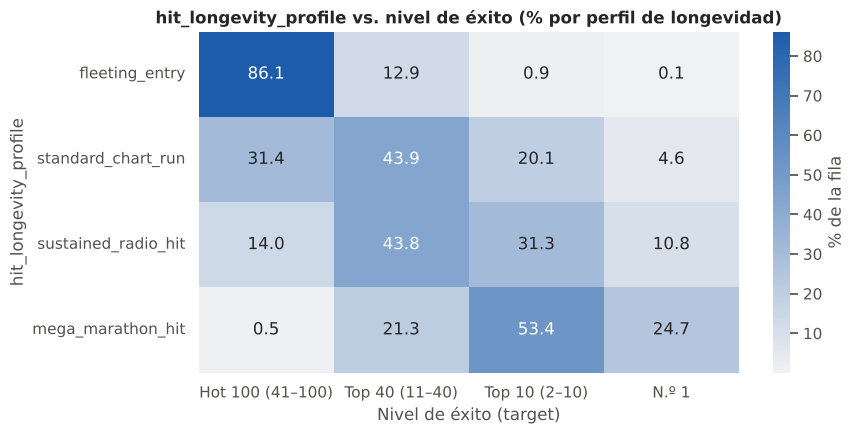

Macro F1 usando SOLO hit_longevity_profile (fuga, no válido): 0.383


In [ ]:
hl = df[df["target_verificable"] & ~df["bloque_no_verificable"]].copy()
HL_ORDER = ["fleeting_entry", "standard_chart_run", "sustained_radio_hit", "mega_marathon_hit"]

ct = pd.crosstab(hl["hit_longevity_profile"], hl[TARGET]).reindex(index=HL_ORDER, columns=TIER_ORDER)
ct.columns = TIER_LABELS
print("Tabla de contingencia (conteos):"); display(ct)

def cramers_v(tabla):
    chi2 = stats.chi2_contingency(tabla)[0]
    n = tabla.values.sum(); r, k = tabla.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

rng_hl = hl.groupby("hit_longevity_profile")["weeks_on_chart"].agg(["min", "max"]).reindex(HL_ORDER)
print("Rango de weeks_on_chart por perfil:"); display(rng_hl)
rangos_sin_solape = bool((rng_hl["max"].values[:-1] < rng_hl["min"].values[1:]).all())
hl_ord = hl["hit_longevity_profile"].map({v: i for i, v in enumerate(HL_ORDER)})
asoc = pd.DataFrame({
    "medida": ["V de Cramér con chart_success_tier", "Spearman con peak_position", "Spearman con weeks_on_chart",
               "¿Los perfiles son rangos de semanas sin solapamiento?"],
    "valor": [cramers_v(ct), stats.spearmanr(hl_ord, hl["peak_position"]).statistic,
              stats.spearmanr(hl_ord, hl["weeks_on_chart"]).statistic,
              rangos_sin_solape],
})
display(asoc)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(ct.div(ct.sum(axis=1), axis=0) * 100, annot=True, fmt=".1f",
            cmap=sns.light_palette("#1c5cab", as_cmap=True), cbar_kws={"label": "% de la fila"}, ax=ax)
ax.set_title("hit_longevity_profile vs. nivel de éxito (% por perfil de longevidad)")
ax.set_xlabel("Nivel de éxito (target)"); ax.set_ylabel("hit_longevity_profile")
plt.tight_layout(); plt.show()

# ¿Qué macro F1 "lograría" un modelo con esta etiqueta? (solo para cuantificar la fuga)
hl_X = pd.get_dummies(hl["hit_longevity_profile"])
f1_hl = cross_val_score(DecisionTreeClassifier(random_state=SEED), hl_X, hl[TARGET], cv=5, scoring="f1_macro").mean()
print(f"Macro F1 usando SOLO hit_longevity_profile (fuga, no válido): {f1_hl:.3f}")

**Resultado:**
- `hit_longevity_profile` es **exactamente** `weeks_on_chart` cortado en rangos sin solapamiento (1–9, 10–19, 20–29, ≥ 30 semanas).
- Su asociación con el resultado histórico es **fuerte**: Spearman = **0,92** con `weeks_on_chart` y **−0,71** con `peak_position`; V de Cramér con el target = **0,40**.
- En la tabla de contingencia, el 86 % de las `fleeting_entry` son *Hot 100 (41–100)* y solo 4 de 788 `mega_marathon_hit` lo son.
- Usándola **sola** como predictor se obtendría macro F1 = **0,383**, más que el mejor modelo de audio (0,311).

**Interpretación:** esta etiqueta **no describe la música**; describe **cuánto tiempo estuvo la canción en la lista**, un resultado que solo se conoce *después* del éxito. Incluirla daría métricas atractivas pero **falsas** para cualquier canción nueva. Lo mismo ocurre con `confidence_score` (macro F1 = 0,483 por sí sola) y con los textos `cot_rationale`/`evidence_span`, que citan el target y el pico.

**Lección metodológica:** en este dataset, **el enriquecimiento con IA mezcla etiquetas musicales redundantes con etiquetas que filtran el resultado**. Antes de usar datos enriquecidos hay que auditar **cómo** se generaron.

### 4.9.2 Análisis de sensibilidad: ¿qué pasa si se incluye el bloque no verificable?

Se repite la validación cruzada del Random Forest optimizado incluyendo las filas 2021–2026 (con su propio split agrupado). **No** sustituye al análisis principal; solo muestra cuánto cambiarían las conclusiones.

In [ ]:
sens = df[df["target_verificable"]].dropna(subset=["energy", "valence", "loudness"]).reset_index(drop=True)
Xs, ys, gs = sens[FEATURES_MAIN], sens[TARGET].map(y_map), sens["group_key"]
tr_s, _ = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(Xs, ys, gs))
folds_s = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(Xs.iloc[tr_s], ys.iloc[tr_s], gs.iloc[tr_s]))
r_s = cross_validate(make_pipeline(rf_tuned()), Xs.iloc[tr_s], ys.iloc[tr_s], cv=folds_s,
                     scoring=["f1_macro", "balanced_accuracy"])
sens_tab = pd.DataFrame({
    "filas": [len(df_model), len(sens)],
    "macro F1 CV": [cv_table.loc["Random Forest (RandomizedSearch)", "f1_macro_mean"], r_s["test_f1_macro"].mean()],
    "bal. acc. CV": [cv_table.loc["Random Forest (RandomizedSearch)", "balanced_accuracy_mean"], r_s["test_balanced_accuracy"].mean()],
    "% clase N.º 1": [(y_all == 3).mean() * 100, (ys == 3).mean() * 100],
}, index=["Principal (sin bloque no verificable)", "Sensibilidad (con bloque 2021–2026)"])
display(sens_tab.round(4))

,filas,macro F1 CV,bal. acc. CV,% clase N.º 1
Principal (sin bloque no verificable),24317,0.3166,0.3219,4.1494
Sensibilidad (con bloque 2021–2026),27317,0.3231,0.3357,4.4075


**Resultado:** con el bloque 2021–2026 incluido, la macro F1 en CV sube levemente (**0,317 → 0,323**) y la balanced accuracy pasa de 0,322 a 0,336. La mejora es pequeña y puede deberse a que el bloque contiene muchas "versiones" casi idénticas de las mismas canciones y una distribución de clases distinta. Aunque el split agrupado mitiga parte del problema, los títulos con "(Version N)" tienen `song_id` y `spotify_track_id` diferentes, así que **no quedan agrupados**.

**Conclusión:** las conclusiones principales (señal débil, RF ≈ 0,31–0,32 de macro F1) **no cambian** al incluir o excluir el bloque. La exclusión es la opción conservadora.

<a id="b5"></a>
# Bloque 5 · Red neuronal artificial con TensorFlow/Keras (20 pts)

## 5.1 Preparación de los datos

- **Mismos predictores** (`FEATURES_MAIN`) y **misma partición** train/test que el Bloque 4.
- **Validación:** se separa el *fold* 1 de `CV_FOLDS` (≈20 % del entrenamiento, **agrupado** por canción) como conjunto de validación para `EarlyStopping`. Se prefiere a `validation_split`, que tomaría simplemente las últimas filas sin respetar grupos ni estratificación.
- **Preprocesamiento:** el mismo `ColumnTransformer`, ajustado **solo** con el sub-entrenamiento; validación y prueba solo se transforman.
- **Desbalance:** se usan pesos de clase `balanced` en la función de pérdida, coherente con los modelos tradicionales.

In [ ]:
tr_i, va_i = CV_FOLDS[0]
X_sub, X_val = X_train[FEATURES_MAIN].iloc[tr_i], X_train[FEATURES_MAIN].iloc[va_i]
y_sub, y_val = y_train.iloc[tr_i].to_numpy(), y_train.iloc[va_i].to_numpy()

prep_nn = make_preprocessor().fit(X_sub)                  # ajuste SOLO con sub-entrenamiento
Xs_sub = prep_nn.transform(X_sub).astype("float32")
Xs_val = prep_nn.transform(X_val).astype("float32")
Xs_test = prep_nn.transform(X_test[FEATURES_MAIN]).astype("float32")
y_test_np = y_test.to_numpy()

cw = compute_class_weight("balanced", classes=np.arange(4), y=y_sub)
CLASS_WEIGHT = dict(enumerate(cw))
N_INPUT = Xs_sub.shape[1]
print(f"Sub-train: {Xs_sub.shape} | Validación: {Xs_val.shape} | Prueba: {Xs_test.shape}")
print("Pesos de clase:", {TIER_LABELS[k]: round(v, 2) for k, v in CLASS_WEIGHT.items()})

Sub-train: (15562, 37) | Validación: (3891, 37) | Prueba: (4864, 37)
Pesos de clase: {'Hot 100 (41–100)': np.float64(0.48), 'Top 40 (11–40)': np.float64(0.85), 'Top 10 (2–10)': np.float64(1.74), 'N.º 1': np.float64(6.03)}


## 5.2 Arquitectura y configuración

| Elemento | Elección | Justificación |
|---|---|---|
| Entrada | `N_INPUT` neuronas (una por columna tras One-Hot) | Debe coincidir con el número de variables transformadas. |
| Ocultas | Dense 64 (ReLU) → Dense 32 (ReLU) | Punto de partida del documento de especificación: ~2× el número de entradas en la primera capa y reducción a la mitad ("embudo"), suficiente para interacciones no lineales sin sobredimensionar con ~17.000 filas. ReLU evita el desvanecimiento del gradiente. |
| Salida | Dense 4 (**Softmax**) | Una probabilidad por clase, que suman 1. |
| Pérdida | `sparse_categorical_crossentropy` | Multiclase con etiquetas enteras (0–3), sin necesidad de One-Hot del target. |
| Optimizador | **Adam** (lr = 0,001) | Tasa de aprendizaje adaptativa por parámetro; estándar robusto. |
| Métrica | accuracy (+ macro F1 calculado aparte) | Keras reporta accuracy; la selección se hace por macro F1 en validación. |
| Parada | `EarlyStopping(val_loss, patience=15, restore_best_weights=True)`, máximo **200 épocas** | Detiene cuando la validación deja de mejorar y recupera los mejores pesos. |

In [ ]:
def build_nn(hidden=(64, 32), dropout=0.0, l2=0.0, lr=1e-3):
    reg = regularizers.l2(l2) if l2 > 0 else None
    model = keras.Sequential([layers.Input(shape=(N_INPUT,), name="entrada")])
    for i, units in enumerate(hidden):
        model.add(layers.Dense(units, activation="relu", kernel_regularizer=reg, name=f"oculta_{i+1}"))
        if dropout > 0:
            model.add(layers.Dropout(dropout, name=f"dropout_{i+1}"))
    model.add(layers.Dense(4, activation="softmax", name="salida_softmax"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def train_nn(name, batch_size=64, **kw):
    tf.keras.utils.set_random_seed(SEED)                 # misma inicialización en cada experimento
    model = build_nn(**kw)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
    t0 = time.time()
    hist = model.fit(Xs_sub, y_sub, validation_data=(Xs_val, y_val), epochs=200, batch_size=batch_size,
                     class_weight=CLASS_WEIGHT, callbacks=[es], verbose=0)
    h = pd.DataFrame(hist.history)
    best_ep = int(h["val_loss"].idxmin()) + 1
    p_val = model.predict(Xs_val, verbose=0)
    p_tr = model.predict(Xs_sub, verbose=0)
    info = {"modelo": name, "épocas entrenadas": len(h), "mejor época": best_ep,
            "loss train (mejor época)": h.loc[best_ep - 1, "loss"], "loss val (mejor época)": h.loc[best_ep - 1, "val_loss"],
            "macro F1 train": f1_score(y_sub, p_tr.argmax(1), average="macro"),
            "macro F1 val": f1_score(y_val, p_val.argmax(1), average="macro"),
            "bal. acc. val": balanced_accuracy_score(y_val, p_val.argmax(1)),
            "parámetros": model.count_params(), "seg": time.time() - t0}
    return model, h, info

def plot_history(h, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, m, lab in [(axes[0], "loss", "Pérdida (entropía cruzada)"), (axes[1], "accuracy", "Accuracy")]:
        ax.plot(h.index + 1, h[m], lw=2, color=CAT_COLORS[0], label="entrenamiento")
        ax.plot(h.index + 1, h[f"val_{m}"], lw=2, color=CAT_COLORS[1], label="validación")
        best = h["val_loss"].idxmin() + 1
        ax.axvline(best, color="#898781", ls="--", lw=1, label=f"mejor época ({best})")
        ax.set_title(f"{title}: {lab}"); ax.set_xlabel("Época"); ax.set_ylabel(lab); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

## 5.3 Red base (64 → 32 → 4)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 64)             │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_softmax (Dense)          │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,934 (54.43 KB)

 Trainable params: 4,644 (18.14 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,290 (36.29 KB)

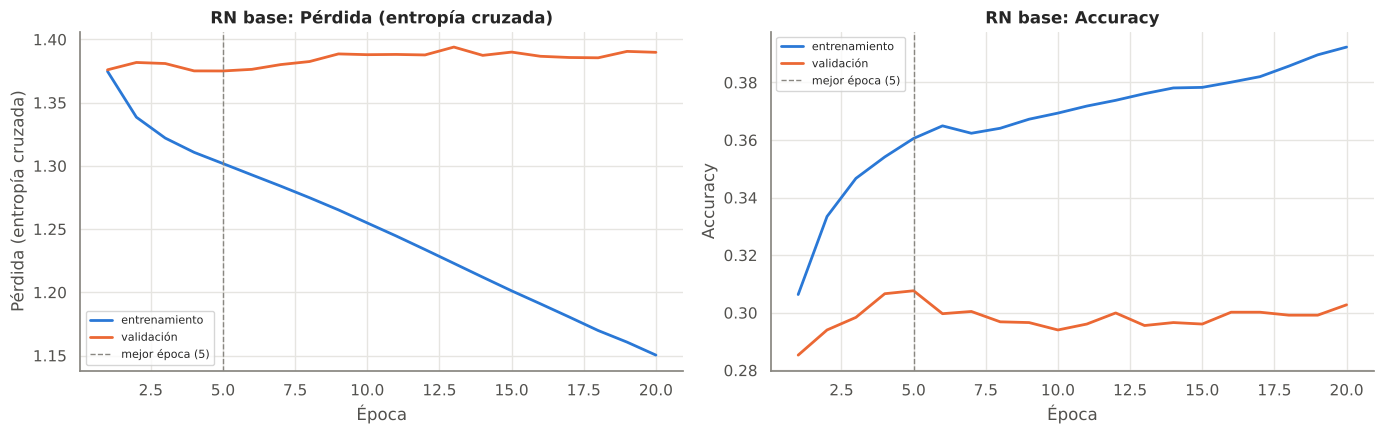

,épocas entrenadas,mejor época,loss train (mejor época),loss val (mejor época),macro F1 train,macro F1 val,bal. acc. val,parámetros,seg
modelo,,,,,,,,,
RN base (64-32),20,5,1.3018,1.3750,0.2887,0.2533,0.3132,4644,12.2266


In [ ]:
nn_base, h_base, info_base = train_nn("RN base (64-32)", hidden=(64, 32))
nn_base.summary()
plot_history(h_base, "RN base")
display(pd.DataFrame([info_base]).set_index("modelo").round(4))

**Diagnóstico de la red base:**
- La pérdida de **entrenamiento baja de forma continua** (≈ 1,38 → 1,15).
- La de **validación toca su mínimo en la época 5** (1,375) y luego **sube**.
- La accuracy de entrenamiento sube hasta ≈ 0,39 mientras la de validación se estanca en ≈ 0,30.

**Señal clara de sobreajuste temprano:** la red empieza a memorizar el entrenamiento casi de inmediato. `EarlyStopping` detuvo el entrenamiento en la época 20 y **restauró los pesos de la época 5**. Macro F1 en validación = **0,253**.

Nota: la accuracy de validación es baja porque los **pesos de clase** empujan a la red a predecir clases minoritarias; por eso la red se juzga por macro F1 y no por accuracy.

## 5.4 Experimentos de mejora

| Experimento | Cambio | Hipótesis |
|---|---|---|
| **Exp. 1** | Dropout 0,3 + regularización L2 (1e-4), misma arquitectura | Si la red base sobreajusta, la regularización reduce la brecha train–validación. |
| **Exp. 2** | Arquitectura más ancha y profunda (128-64-32) + Dropout 0,3 + lr = 0,0005 + batch 128 | Si la red base **subajusta**, más capacidad (controlada con dropout y aprendizaje más lento) podría capturar más patrones. |

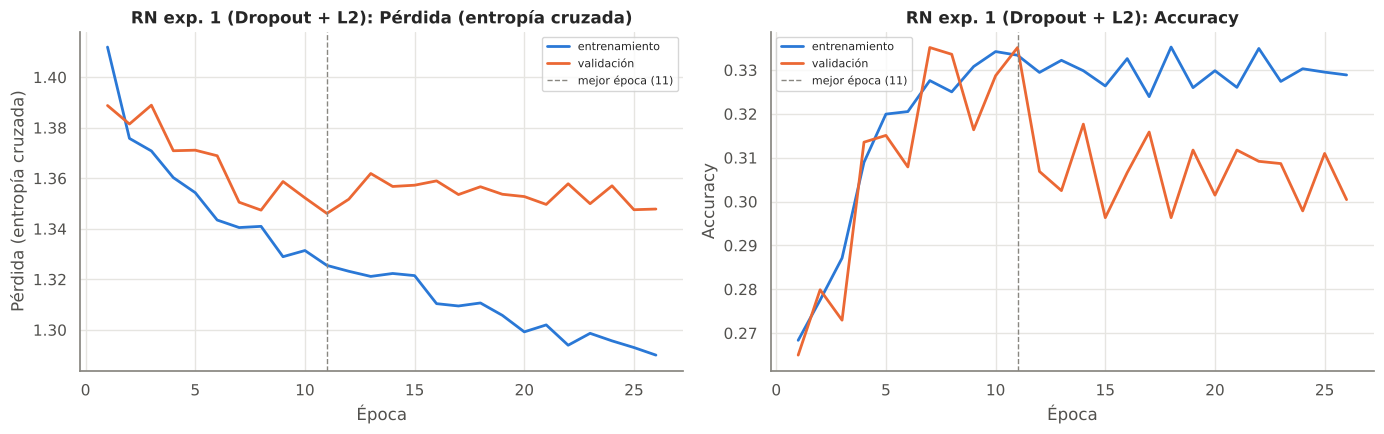

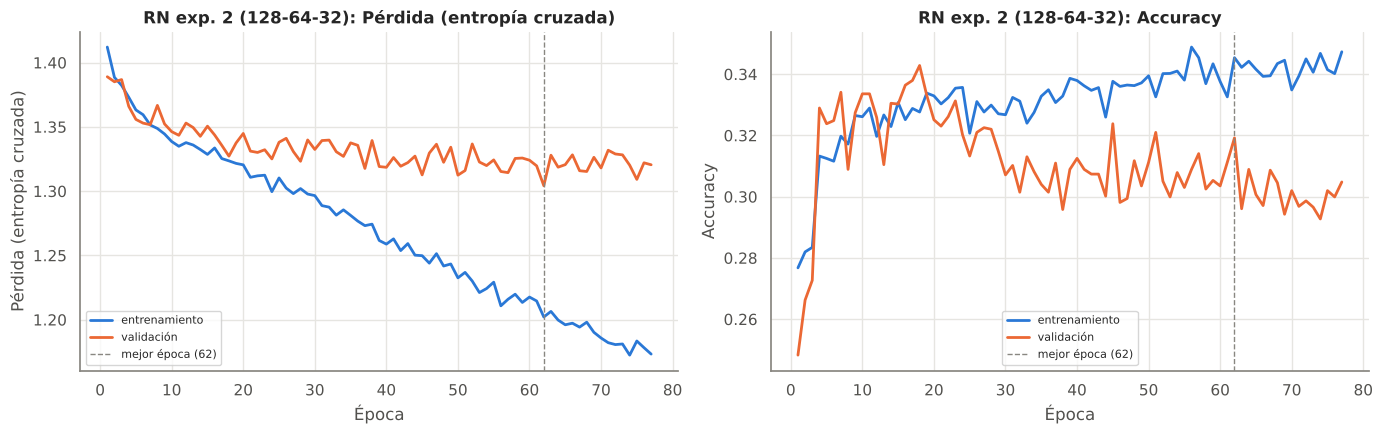

In [ ]:
nn_e1, h_e1, info_e1 = train_nn("RN exp. 1 (Dropout + L2)", hidden=(64, 32), dropout=0.3, l2=1e-4)
plot_history(h_e1, "RN exp. 1 (Dropout + L2)")
nn_e2, h_e2, info_e2 = train_nn("RN exp. 2 (128-64-32, lr 5e-4, batch 128)", hidden=(128, 64, 32),
                                dropout=0.3, lr=5e-4, batch_size=128)
plot_history(h_e2, "RN exp. 2 (128-64-32)")

In [ ]:
nn_models = {info_base["modelo"]: nn_base, info_e1["modelo"]: nn_e1, info_e2["modelo"]: nn_e2}
nn_table = pd.DataFrame([info_base, info_e1, info_e2]).set_index("modelo")
nn_table["brecha F1 (train − val)"] = nn_table["macro F1 train"] - nn_table["macro F1 val"]
display(nn_table.round(4))

BEST_NN = nn_table["macro F1 val"].idxmax()      # selección por VALIDACIÓN, no por prueba
print("Red seleccionada por macro F1 en validación:", BEST_NN)

,épocas entrenadas,mejor época,loss train (mejor época),loss val (mejor época),macro F1 train,macro F1 val,bal. acc. val,parámetros,seg,brecha F1 (train − val)
modelo,,,,,,,,,,
RN base (64-32),20,5,1.3018,1.3750,0.2887,0.2533,0.3132,4644,12.2266,0.0354
RN exp. 1 (Dropout + L2),26,11,1.3255,1.3461,0.2904,0.2755,0.3299,4644,16.8124,0.0150
"RN exp. 2 (128-64-32, lr 5e-4, batch 128)",77,62,1.2021,1.3042,0.3385,0.2721,0.3263,15332,36.6198,0.0664


Red seleccionada por macro F1 en validación: RN exp. 1 (Dropout + L2)


**Comparación de experimentos (selección por macro F1 en validación):**

| Red | Épocas (mejor) | Loss val | Macro F1 train | Macro F1 val | Brecha |
|---|---|---|---|---|---|
| Base 64-32 | 20 (5) | 1,375 | 0,289 | 0,253 | 0,035 |
| **Exp. 1: Dropout 0,3 + L2** | 26 (11) | 1,346 | 0,290 | **0,276** | **0,015** |
| Exp. 2: 128-64-32, lr 5e-4, batch 128 | 77 (62) | **1,304** | 0,339 | 0,272 | 0,066 |

- **Exp. 1 funcionó:** la regularización **redujo la brecha** train–validación (0,035 → 0,015), retrasó el sobreajuste (mejor época 5 → 11) y **subió la macro F1 en validación** de 0,253 a 0,276. Es la evidencia de que el problema de la red base era sobreajuste.
- **Exp. 2:** más capacidad y un aprendizaje más lento consiguen la **menor pérdida de validación**, pero la macro F1 no mejora (0,272) y la brecha vuelve a crecer (0,066). Las curvas muestran que la pérdida de entrenamiento sigue bajando mientras la de validación se aplana desde la época ≈ 20: más capacidad solo sirve para memorizar.

**Red seleccionada: Exp. 1 (Dropout + L2).** La elección se hace en validación, **sin mirar la prueba**.

## 5.5 Evaluación final de la red en prueba y comparación con los modelos tradicionales

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,roc_auc_ovr_macro,%_errores_graves,F1 Hot 100 (41–100),F1 Top 40 (11–40),F1 Top 10 (2–10),F1 N.º 1
modelo,,,,,,,,,,,,
RN base (64-32),0.2919,0.2838,0.3233,0.2458,0.3311,0.3233,0.5856,35.2796,0.4323,0.2623,0.1655,0.1229
RN exp. 1 (Dropout + L2),0.3238,0.2958,0.3312,0.2671,0.3620,0.3312,0.5861,33.0387,0.4769,0.2783,0.1849,0.1283
"RN exp. 2 (128-64-32, lr 5e-4, batch 128)",0.3016,0.2890,0.3132,0.2585,0.3381,0.3132,0.5759,31.8873,0.4222,0.2804,0.2161,0.1151


                  precision    recall  f1-score   support

Hot 100 (41–100)      0.618     0.388     0.477      2534
  Top 40 (11–40)      0.325     0.243     0.278      1427
   Top 10 (2–10)      0.166     0.208     0.185       701
           N.º 1      0.074     0.485     0.128       202

        accuracy                          0.324      4864
       macro avg      0.296     0.331     0.267      4864
    weighted avg      0.444     0.324     0.362      4864



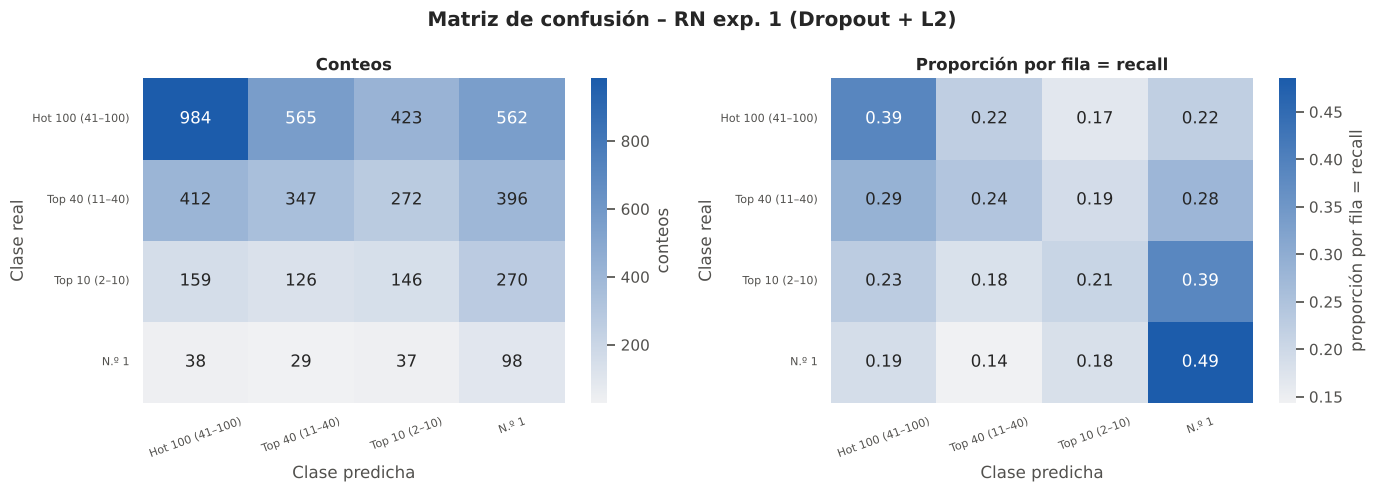

In [ ]:
nn_test_rows, nn_pred = [], {}
for name, m in nn_models.items():
    p = m.predict(Xs_test, verbose=0)
    nn_pred[name] = p.argmax(1)
    nn_test_rows.append(evaluate(name, y_test_np, nn_pred[name], p))
nn_test = pd.DataFrame(nn_test_rows).set_index("modelo")
display(nn_test.round(4))
print(classification_report(y_test_np, nn_pred[BEST_NN], target_names=TIER_LABELS, digits=3))
_ = plot_confusion(y_test_np, nn_pred[BEST_NN], f"Matriz de confusión – {BEST_NN}")

### Tabla comparativa final (todos los modelos, conjunto de prueba)

La columna "validación" muestra la macro F1 media de la CV de 5 folds para los modelos tradicionales y la macro F1 en el fold de validación para las redes (no son idénticas en diseño, pero ambas se calculan **sin** el conjunto de prueba).

,tipo,macro F1 validación,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,roc_auc_ovr_macro,%_errores_graves,F1 Hot 100 (41–100),F1 Top 40 (11–40),F1 Top 10 (2–10),F1 N.º 1,complejidad
modelo,,,,,,,,,,,,,,,
Random Forest (RandomizedSearch),Tradicional,0.317,0.426,0.312,0.317,0.311,0.434,0.317,0.598,19.572,0.586,0.311,0.227,0.122,media
Random Forest,Tradicional,0.297,0.476,0.329,0.299,0.300,0.450,0.299,0.599,14.926,0.637,0.303,0.183,0.078,media
Regresión logística (GridSearch),Tradicional,0.274,0.345,0.292,0.336,0.270,0.373,0.336,0.586,32.401,0.522,0.235,0.183,0.137,baja
Regresión logística,Tradicional,0.274,0.345,0.292,0.336,0.270,0.373,0.336,0.586,32.401,0.522,0.235,0.183,0.137,baja
RN exp. 1 (Dropout + L2),Red neuronal,0.275,0.324,0.296,0.331,0.267,0.362,0.331,0.586,33.039,0.477,0.278,0.185,0.128,alta
"RN exp. 2 (128-64-32, lr 5e-4, batch 128)",Red neuronal,0.272,0.302,0.289,0.313,0.258,0.338,0.313,0.576,31.887,0.422,0.280,0.216,0.115,alta
Árbol de decisión,Tradicional,0.251,0.297,0.293,0.302,0.250,0.343,0.302,0.552,37.459,0.442,0.279,0.184,0.095,baja
RN base (64-32),Red neuronal,0.253,0.292,0.284,0.323,0.246,0.331,0.323,0.586,35.280,0.432,0.262,0.166,0.123,alta
Dummy (clase mayoritaria),Baseline,0.171,0.521,0.130,0.250,0.171,0.357,0.250,0.500,18.565,0.685,0.000,0.000,0.000,—


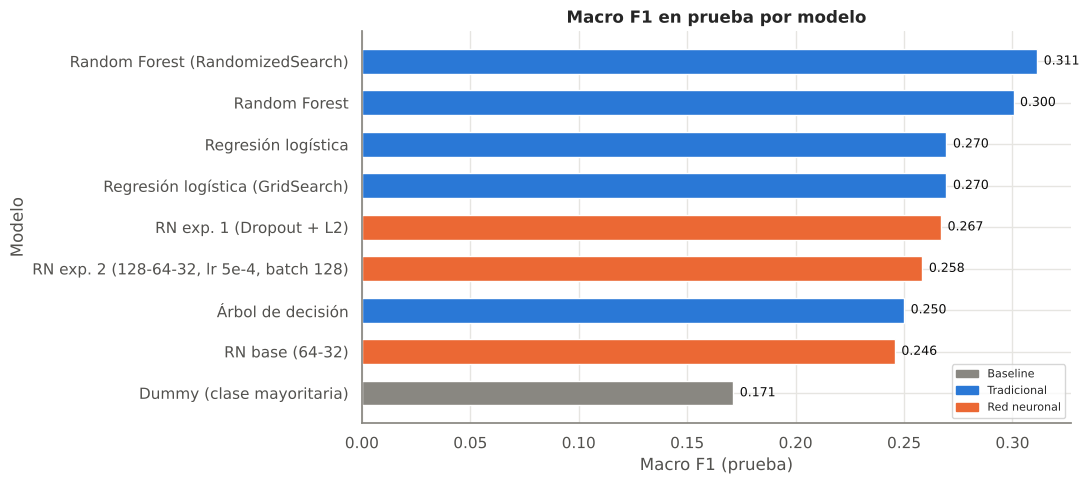

In [ ]:
final_cols = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted",
              "balanced_accuracy", "roc_auc_ovr_macro", "%_errores_graves"] + [f"F1 {l}" for l in TIER_LABELS]
tabla_final = pd.concat([test_table[final_cols], nn_test[final_cols]])
tabla_final.insert(0, "macro F1 validación", list(cv_table.loc[test_table.index, "f1_macro_mean"]) +
                   list(nn_table.loc[nn_test.index, "macro F1 val"]))
tabla_final.insert(0, "tipo", ["Baseline"] + ["Tradicional"] * (len(test_table) - 1) + ["Red neuronal"] * len(nn_test))
tabla_final["complejidad"] = (["—", "baja", "baja", "media", "baja", "media"] + ["alta"] * len(nn_test))
tabla_final = tabla_final.sort_values("f1_macro", ascending=False)
display(tabla_final.style.format(precision=3, subset=final_cols + ["macro F1 validación"]).background_gradient(
    cmap=sns.light_palette("#3987e5", as_cmap=True), subset=["f1_macro", "balanced_accuracy", "roc_auc_ovr_macro"]))

fig, ax = plt.subplots(figsize=(11, 5))
orden_m = tabla_final.sort_values("f1_macro").index
colores = [{"Baseline": "#898781", "Tradicional": CAT_COLORS[0], "Red neuronal": CAT_COLORS[1]}[t]
           for t in tabla_final.loc[orden_m, "tipo"]]
ax.barh(orden_m, tabla_final.loc[orden_m, "f1_macro"], color=colores, height=0.6)
for y, v in enumerate(tabla_final.loc[orden_m, "f1_macro"]):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=9, color="#0b0b0b")
ax.set_title("Macro F1 en prueba por modelo"); ax.set_xlabel("Macro F1 (prueba)"); ax.set_ylabel("Modelo")
ax.legend(handles=[mpl.patches.Patch(color=c, label=l) for l, c in
                   [("Baseline", "#898781"), ("Tradicional", CAT_COLORS[0]), ("Red neuronal", CAT_COLORS[1])]],
          fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**¿Es competitiva la red neuronal? No, en este problema.**

| Modelo | Macro F1 prueba | Balanced acc. | AUC | % errores graves | Complejidad |
|---|---|---|---|---|---|
| **RF optimizado** | **0,311** | 0,317 | **0,598** | **19,6** | media |
| Regresión logística | 0,270 | **0,336** | 0,586 | 32,4 | baja |
| RN exp. 1 (mejor red) | 0,267 | 0,331 | 0,586 | 33,0 | alta |
| RN base | 0,246 | 0,323 | 0,586 | 35,3 | alta |

La mejor red queda **por debajo del Random Forest** en macro F1 (−0,044) y **al nivel de la regresión logística**, con más errores graves. Su perfil es parecido al de la regresión logística (alto recall de *N.º 1* = 0,49 pero precisión de solo 0,07): los pesos de clase la empujan a predecir muchas canciones como *N.º 1*.

**Reto: ¿justifica la red su complejidad?** **No.** Cuesta más entrenar, es menos interpretable, su resultado varía con la semilla y la arquitectura, y no supera a un modelo de árboles más sencillo. Con datos **tabulares** de pocas variables y señal débil, los ensambles de árboles suelen ser más competitivos que las redes densas. La red sí cumple su papel en el proyecto: confirma, con otra familia de modelos, que **el límite está en la información de las variables**, no en el algoritmo.

<a id="reto"></a>
# Reto final · Escenario B (clasificación)

*"Suponga que su modelo obtiene un accuracy del 90 %, pero detecta correctamente solo el 40 % de los casos de la clase de interés."* Se responde con métricas calculadas en este notebook, tomando como **clase de interés** el **N.º 1** (la más valiosa y la más escasa).

Para ajustar el umbral **sin mirar el conjunto de prueba**, se usan probabilidades *out-of-fold* del modelo tradicional seleccionado sobre el entrenamiento (`cross_val_predict` con los mismos 5 folds). El umbral se elige allí y se aplica **una sola vez** a prueba.

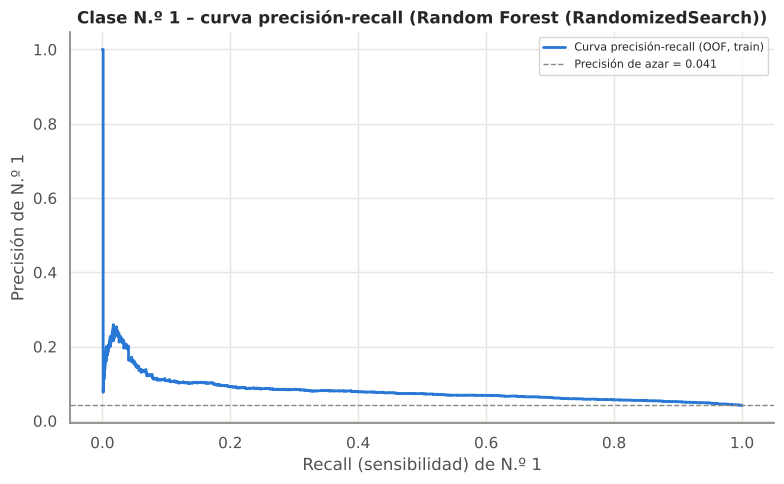

,umbral p(N.º 1),recall N.º 1,precisión N.º 1,% canciones marcadas
0,0.1000,0.8760,0.0530,68.3030
1,0.1500,0.6510,0.0660,40.7390
2,0.2000,0.3880,0.0810,19.8480
3,0.2500,0.1960,0.0930,8.7490
4,0.3000,0.0930,0.1110,3.4700
5,0.4000,0.0250,0.2330,0.4420
6,0.5000,0.0020,0.1250,0.0820


Umbral elegido en train (OOF): 0.15


,accuracy,recall N.º 1,precisión N.º 1,macro F1
regla,,,,
argmax (por defecto),0.4260,0.1290,0.1160,0.3110
umbral N.º 1 = 0.15,0.3210,0.6240,0.0600,0.2290


In [ ]:
best_pipe_trad = clone(final_models[BEST_TRAD])
oof = cross_val_predict(best_pipe_trad, X_train[FEATURES_MAIN], y_train, cv=CV_FOLDS, method="predict_proba")
y_tr_n1 = (y_train.to_numpy() == 3).astype(int)
prec, rec, thr = precision_recall_curve(y_tr_n1, oof[:, 3])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(rec, prec, lw=2, color=CAT_COLORS[0], label="Curva precisión-recall (OOF, train)")
ax.axhline(y_tr_n1.mean(), color="#898781", ls="--", lw=1, label=f"Precisión de azar = {y_tr_n1.mean():.3f}")
ax.set_title(f"Clase N.º 1 – curva precisión-recall ({BEST_TRAD})")
ax.set_xlabel("Recall (sensibilidad) de N.º 1"); ax.set_ylabel("Precisión de N.º 1"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Tabla de umbrales candidatos
cand = []
for t in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    pred_bin = (oof[:, 3] >= t).astype(int)
    cand.append({"umbral p(N.º 1)": t, "recall N.º 1": recall_score(y_tr_n1, pred_bin, zero_division=0),
                 "precisión N.º 1": precision_score(y_tr_n1, pred_bin, zero_division=0),
                 "% canciones marcadas": pred_bin.mean() * 100})
cand = pd.DataFrame(cand)
display(cand.round(3))

# Regla: el umbral más alto que logre recall ≥ 0.50 en OOF (elegido en train)
ok = cand[cand["recall N.º 1"] >= 0.50]
UMBRAL = ok["umbral p(N.º 1)"].max() if len(ok) else cand["umbral p(N.º 1)"].min()
print(f"Umbral elegido en train (OOF): {UMBRAL}")

def predict_with_threshold(proba, t):
    pred = proba.argmax(1)
    pred[proba[:, 3] >= t] = 3
    return pred

p_test = probas[BEST_TRAD]
antes = preds[BEST_TRAD]; despues = predict_with_threshold(p_test.copy(), UMBRAL)
reto = pd.DataFrame([
    {"regla": "argmax (por defecto)", "accuracy": accuracy_score(y_test, antes),
     "recall N.º 1": recall_score(y_test == 3, antes == 3), "precisión N.º 1": precision_score(y_test == 3, antes == 3, zero_division=0),
     "macro F1": f1_score(y_test, antes, average="macro")},
    {"regla": f"umbral N.º 1 = {UMBRAL}", "accuracy": accuracy_score(y_test, despues),
     "recall N.º 1": recall_score(y_test == 3, despues == 3), "precisión N.º 1": precision_score(y_test == 3, despues == 3, zero_division=0),
     "macro F1": f1_score(y_test, despues, average="macro")},
]).set_index("regla")
display(reto.round(3))

**Respuestas al Escenario B, con los datos de este proyecto.** La situación del enunciado (accuracy alta, recall bajo en la clase de interés) **ocurre aquí**: el Dummy tiene **52 % de accuracy** y **0 %** de recall en *N.º 1*; el RF optimizado detecta solo el **12,9 %** de los N.º 1 de prueba (26 de 202).

**1. ¿Es bueno el modelo para el caso?** No, si el objetivo es identificar números 1. Una accuracy alta en un problema desbalanceado puede lograrse ignorando la clase minoritaria. Lo que importa es el costo de los errores: dejar pasar 6 de cada 10 casos de interés no es aceptable.

**2. ¿Qué métrica mirar?** El **recall** y la **precisión** de la clase de interés, su **F1**, la curva **precisión-recall** (más informativa que la ROC con clases raras) y, a nivel global, **macro F1** y **balanced accuracy**. La matriz de confusión muestra *a qué clase* van los errores.

**3. ¿Cómo ajustar el umbral?** En lugar de `argmax`, se marca una canción como *N.º 1* si `p(N.º 1) ≥ umbral`:
- Con probabilidades **out-of-fold del entrenamiento** se eligió el umbral más alto que da recall ≥ 0,50: **0,15**.
- Aplicado **una sola vez** a prueba: el recall de *N.º 1* sube de **0,129 a 0,624**, pero la precisión baja de 0,116 a **0,060** (la tasa base es 0,042, así que sigue siendo apenas 1,4 veces mejor que el azar). Además, la accuracy cae de 0,426 a 0,321 y la macro F1 de 0,311 a 0,229.

Bajar el umbral cambia falsos negativos por **muchos** falsos positivos: con estas variables no hay un umbral que dé a la vez buen recall y buena precisión.

**4. Riesgos de ajustar el umbral mirando la prueba:** el umbral quedaría **sobreajustado al conjunto de prueba**. La métrica reportada sería optimista y dejaría de ser una estimación honesta del desempeño futuro (*leakage* de evaluación). Por eso aquí se eligió con validación (*out-of-fold*) y la prueba se usó una sola vez. Si se quisiera seguir iterando, haría falta un conjunto de validación separado o una validación cruzada anidada.

<a id="b6"></a>
# Bloque 6 · Informe ejecutivo (10 pts)

In [ ]:
# Resumen numérico que sustenta el informe (se recalcula en cada ejecución)
resumen_ejec = tabla_final.loc[[BEST_TRAD, BEST_NN, "Dummy (clase mayoritaria)"],
                               ["f1_macro", "balanced_accuracy", "accuracy", "roc_auc_ovr_macro", "%_errores_graves",
                                "F1 N.º 1", "F1 Hot 100 (41–100)"]]
display(resumen_ejec.round(3))

,f1_macro,balanced_accuracy,accuracy,roc_auc_ovr_macro,%_errores_graves,F1 N.º 1,F1 Hot 100 (41–100)
modelo,,,,,,,
Random Forest (RandomizedSearch),0.3110,0.3170,0.4260,0.5980,19.5720,0.1220,0.5860
RN exp. 1 (Dropout + L2),0.2670,0.3310,0.3240,0.5860,33.0390,0.1280,0.4770
Dummy (clase mayoritaria),0.1710,0.2500,0.5210,0.5000,18.5650,0.0000,0.6850


## Informe ejecutivo – Music Hit Predictor

*Dirigido a la dirección de la discográfica. Cifras obtenidas en la ejecución de este notebook (semilla 42).*

**El problema.** Queríamos saber si las características musicales de una canción (bailabilidad, energía, positividad, tempo, duración, acústica, género, entre otras) permiten anticipar qué tan alto llegó en el Billboard Hot 100: entrada simple (puestos 41–100), Top 40, Top 10 o número 1. Usamos un dataset público de Kaggle con 32.503 canciones entre 1958 y 2026, con audio de Spotify y etiquetas generadas por inteligencia artificial.

**Calidad de los datos.** Tras una auditoría trabajamos con 24.317 canciones verificables. Eliminamos 24 duplicados exactos y excluimos 5.159 canciones sin audio de Spotify. También apartamos 3.000 registros de 2021–2026 con señales claras de haber sido generados artificialmente: fechas que no coinciden con las de Billboard, títulos tipo "Version 1057" y una cantidad irreal de números 1.

**Hallazgos del análisis exploratorio.** La música del Hot 100 cambió mucho con el tiempo: hoy es menos acústica, menos "alegre", con más partes habladas, y las canciones son más cortas desde los años 90. Sin embargo, **las diferencias entre niveles de éxito son mínimas**. Los números 1 son apenas un poco más bailables, positivos y largos, y ninguna característica explica más del 1 % de las diferencias. El género musical aporta algo más que los rasgos de sonido.

**Mejor modelo.** Comparamos un modelo de referencia, regresión logística, árbol de decisión, Random Forest y una red neuronal. El mejor fue un **Random Forest optimizado**, con un **macro F1 de 0,31** en datos nunca vistos, frente a 0,17 del modelo de referencia. La red neuronal no lo superó (0,27) pese a ser más compleja. Es una mejora real, pero **modesta**: la capacidad para ordenar canciones (AUC = 0,60) está poco por encima del azar (0,50).

**Errores y su costo.** El modelo detecta solo 13 de cada 100 números 1 y, en uno de cada tres casos, los confunde con entradas simples. Si forzamos que detecte más números 1, encuentra el 62 %, pero solo el 6 % de sus alertas son correctas. En la práctica, esto significa invertir promoción en muchas canciones equivocadas o dejar pasar éxitos reales.

**Hallazgo sobre la inteligencia artificial.** Las etiquetas de IA que describen la música no mejoran el modelo, porque repiten información que ya estaba en los datos. Las que sí "mejoran" el resultado lo hacen porque **contienen la respuesta**: describen cuántas semanas duró la canción en la lista o mencionan su posición. Usarlas sería un autoengaño.

**Limitaciones.** El dataset solo incluye canciones que ya entraron al Hot 100, por lo que **no sirve para predecir si una canción nueva entrará**. Faltan variables decisivas como promoción, fama del artista, radio, redes sociales o fecha de lanzamiento. Además, los datos de Spotify tienen errores de asociación y sesgo hacia canciones disponibles en la plataforma, y los resultados son asociaciones, **no causas**.

**Recomendaciones.** Usar el análisis para entender tendencias, **no** para decidir automáticamente qué canciones promocionar. Mantener el criterio artístico como decisión principal. Auditar siempre los datos enriquecidos con IA antes de comprarlos o usarlos.

**Trabajo futuro.** Incorporar datos de promoción, historial del artista, *streaming* y redes sociales; incluir canciones que **no** entraron a la lista; analizar por época y por género; y validar con lanzamientos recientes y reales.

**Consideraciones éticas.** No usar el modelo para descartar artistas emergentes: reforzaría los sesgos históricos de la industria hacia ciertos géneros. Hay que ser transparentes sobre sus limitaciones y no presentarlo como un "predictor de éxitos".

<a id="cierre"></a>
# Cierre del proyecto

## C.1 Tabla comparativa final de todos los modelos

La tabla completa está en la sección 5.5 (`tabla_final`). Aquí se repite una versión compacta, incluyendo los experimentos de enriquecimiento con IA.

In [ ]:
compacta = tabla_final[["tipo", "macro F1 validación", "f1_macro", "balanced_accuracy", "accuracy",
                        "roc_auc_ovr_macro", "%_errores_graves", "complejidad"]].copy()
ia_extra = ia_table[["macro F1 test", "bal. acc. test"]].rename(columns={"macro F1 test": "f1_macro", "bal. acc. test": "balanced_accuracy"})
ia_extra["tipo"] = "Experimento IA"
compacta = pd.concat([compacta, ia_extra])
display(compacta.style.format(precision=3, na_rep="—"))

,tipo,macro F1 validación,f1_macro,balanced_accuracy,accuracy,roc_auc_ovr_macro,%_errores_graves,complejidad
Random Forest (RandomizedSearch),Tradicional,0.317,0.311,0.317,0.426,0.598,19.572,media
Random Forest,Tradicional,0.297,0.300,0.299,0.476,0.599,14.926,media
Regresión logística (GridSearch),Tradicional,0.274,0.270,0.336,0.345,0.586,32.401,baja
Regresión logística,Tradicional,0.274,0.270,0.336,0.345,0.586,32.401,baja
RN exp. 1 (Dropout + L2),Red neuronal,0.275,0.267,0.331,0.324,0.586,33.039,alta
"RN exp. 2 (128-64-32, lr 5e-4, batch 128)",Red neuronal,0.272,0.258,0.313,0.302,0.576,31.887,alta
Árbol de decisión,Tradicional,0.251,0.250,0.302,0.297,0.552,37.459,baja
RN base (64-32),Red neuronal,0.253,0.246,0.323,0.292,0.586,35.280,alta
Dummy (clase mayoritaria),Baseline,0.171,0.171,0.250,0.521,0.500,18.565,—
A · RF audio original,Experimento IA,—,0.311,0.317,—,—,—,—


## C.2 Checklist de cumplimiento de la rúbrica

| Bloque | Requisito | Dónde | Estado |
|---|---|---|---|
| 1 | Problema, contexto, usuarios e impacto | 1.1–1.4 | ✅ |
| 1 | Fuente (enlace, autor, fecha, licencia) y justificación | 1.5 | ✅  |
| 1 | Carga en Colab (botón de carga / Drive) | 1.6 | ✅ |
| 1 | 10 primeras y 5 últimas filas; registros y columnas | 1.7–1.9 | ✅ |
| 1 | Tipos, nulos y duplicados | 1.9 | ✅ |
| 1 | Definición y justificación del target | 1.10 | ✅ (regla verificada al 100 %) |
| 1 | Diccionario de datos (nombre, tipo, unidad, significado) | 1.11 | ✅ 33 columnas |
| 1 | Reto: `report_data_quality(df)` | 1.12 | ✅ |
| 2 | Duplicados con justificación | 2.1–2.3 | ✅ |
| 2 | Faltantes + comparación de ≥ 2 estrategias | 2.4 | ✅ 4 estrategias |
| 2 | Atípicos con boxplots e IQR + decisión | 2.5 | ✅ |
| 2 | Valores inválidos (sin eliminar automáticamente) | 2.6 | ✅ |
| 2 | Codificación justificada | 2.8, 2.11 | ✅ One-Hot / multi-hot |
| 2 | ≥ 2 variables nuevas | 2.9 | ✅ `duration_minutes`, `dance_energy`, macro-géneros, `entry_decade` |
| 2 | X/y y escalado con Pipeline/ColumnTransformer | 2.11 | ✅ |
| 2 | Reto: *data leakage* explicado y evitado | 2.10 | ✅ con demostración |
| 3 | Gráficas (a)–(g) con título, ejes y leyenda | 3(a)–3(g) | ✅ |
| 3 | Patrón / utilidad / limitación por gráfica | después de cada gráfica | ✅ |
| 3 | Reto: prueba estadística + correlación vs causalidad + desbalance | 3.8 | ✅ |
| 4 | Split 80/20, semilla, estratificación | 4.1 | ✅ (además agrupado) |
| 4 | ≥ 3 modelos (LR, árbol/RF, otro) + baseline | 4.2–4.3 | ✅ Dummy, LR, árbol, RF |
| 4 | Transformaciones ajustadas solo con train | Pipeline | ✅ |
| 4 | CV k = 5 (media y desviación) | 4.3 | ✅ |
| 4 | GridSearchCV / RandomizedSearchCV | 4.4 | ✅ ambos |
| 4 | Accuracy, precision, recall, F1, matriz de confusión, ROC/AUC | 4.6–4.7 | ✅ (+ macro/weighted F1, balanced accuracy) |
| 4 | Tabla comparativa de Pandas | 4.6 | ✅ |
| 4 | Importancia de variables vs EDA | 4.8 | ✅ coeficientes, impureza, permutación |
| 4 | Reto: selección multi-criterio (interpretabilidad, costo de errores) | 4.8.1 | ✅ |
| 4 | Experimento IA (A vs B, mismos folds, bootstrap) | 4.9 | ✅ |
| 4 | `hit_longevity_profile` por separado | 4.9.1 | ✅ |
| 5 | Mismas variables y partición | 5.1 | ✅ |
| 5 | Escalado ajustado con train | 5.1 | ✅ |
| 5 | ≥ 2 capas ReLU, Softmax, justificación de neuronas | 5.2 | ✅ |
| 5 | Pérdida y optimizador justificados | 5.2 | ✅ |
| 5 | Validación + EarlyStopping, ≤ 200 épocas | 5.2–5.4 | ✅ |
| 5 | Curvas de pérdida y métrica | 5.3–5.4 | ✅ |
| 5 | Mismas métricas en prueba | 5.5 | ✅ |
| 5 | ≥ 2 experimentos de mejora en tabla | 5.4 | ✅ |
| 5 | Tabla final con todos los modelos | 5.5 / C.1 | ✅ |
| 5 | Reto: sobre/subajuste y ¿vale la pena la red? | 5.3–5.5 | ✅ |
| 6 | Informe ejecutivo 400–600 palabras | Bloque 6 | ✅ (≈ 560 palabras) |
| Entrega | Enlaces a dataset, propuesta y video al inicio | Portada | ✅  |
| Entrega | Declaración de uso de IA | C.4 | ✅  |
| Extra | Reto final Escenario B | Reto final | ✅ |

## C.3 Limitaciones del proyecto

1. **Sesgo de selección del target:** solo hay canciones que entraron al Hot 100. El modelo **no** predice si una canción inédita entrará a la lista ni distingue éxitos de fracasos fuera de ella.
2. **Señal débil:** las variables de audio explican muy poco del nivel de éxito (|ρ| ≤ 0,07; macro F1 ≈ 0,31; AUC ≈ 0,60). Faltan variables decisivas: promoción, sello, fama previa del artista, radio, *streaming*, redes sociales, fecha de lanzamiento y colaboraciones.
3. **Calidad de la fuente:** errores de *matching* con Spotify (109 pistas compartidas por canciones distintas, una duración de 51 min dudosa), 5.161 canciones sin audio (faltante no aleatorio) y un bloque de 3.000 registros 2021–2026 de procedencia no verificable que se excluyó.
4. **Variables de procedencia dudosa:** `confidence_score`, `spotify_track_popularity` y las etiquetas IA derivadas del resultado se excluyeron porque su construcción no está documentada o filtra el resultado. Los géneros de Spotify parecen asignarse a nivel de artista.
5. **Representatividad temporal:** las reglas de Billboard cambiaron (ventas, radio, *streaming*). Un mismo puesto no significa lo mismo en 1965 y en 2020, y el modelo mezcla seis décadas.
6. **Exclusión de filas sin audio:** el conjunto analítico sub-representa canciones antiguas y menos exitosas.
7. **Sin causalidad:** todas las relaciones son asociaciones observacionales.
8. **Sensibilidad de la red neuronal:** los resultados de la red pueden variar ligeramente entre entornos (CPU/GPU, versión de TensorFlow) aunque se fijen las semillas.
9. **Metadatos no verificados:** autor, URL y licencia del dataset deben confirmarse en Kaggle; la metodología del autor se presenta tal como fue declarada.

## C.4 Declaración de uso de inteligencia artificial

En este proyecto se utilizaron asistentes de IA de la siguiente manera:
- **Claude AI (Anthropic)** como **asistente de programación**.
- **ChatGPT (OpenAI)** como **apoyo metodológico**, revisión e interpretación.

Todas las cifras del notebook provienen de la ejecución del código sobre el dataset real; ninguna métrica fue escrita a mano sin haberse calculado.

## C.5 Referencias

- Dataset: `billboard_hot_100_spotify_audio_features_enriched.csv`, Kaggle. `[COMPLETAR: autor, año, URL y licencia tal como aparecen en Kaggle]`
- Billboard. *Billboard Hot 100* (fuente original de las posiciones). https://www.billboard.com/charts/hot-100/
- Spotify for Developers. *Web API Reference – audio features*. https://developer.spotify.com/documentation/web-api
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Abadi, M. et al. (2015). *TensorFlow: Large-scale machine learning on heterogeneous systems*. https://www.tensorflow.org
- Chollet, F. et al. (2015). *Keras*. https://keras.io
- Kaufman, S., Rosset, S., Perlich, C. y Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM TKDD*, 6(4).
- Documentación de scikit-learn: *Common pitfalls – Data leakage*; `StratifiedGroupKFold`; *Model evaluation: classification metrics*.